# Trabajar con predicciones del cambio de morosidad

In [3]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

# ======================================================
# 1. LOCALIZAR LA RAÍZ DEL PROYECTO
# ======================================================

ROOT = next(
    (
        ruta
        for ruta in (Path.cwd(), *Path.cwd().parents)
        if (ruta / "src/modeling/data.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


# ======================================================
# 2. IMPORTAR NUESTRA INFRAESTRUCTURA
# ======================================================

from src.modeling.data import preparar_datasets
from src.modeling.splits import construir_folds_temporales
from src.modeling.baselines import evaluar_baselines_cv
from src.modeling.delta import entrenar_predecir_delta


# ======================================================
# 3. CARGAR DATASET RECONSTRUIDO
# ======================================================

RUTA_DATASET = (
    ROOT
    / "data/processed/rebuild/"
    / "panel_features_multihorizonte.parquet"
)

if not RUTA_DATASET.is_file():
    raise FileNotFoundError(RUTA_DATASET)

features = pd.read_parquet(RUTA_DATASET)

print("Dataset:", RUTA_DATASET)
print("Dimensiones:", features.shape)
print("Bancos:", features["banco"].nunique())
print("Período:", features["fecha"].min(), "→", features["fecha"].max())

assert features.shape == (5972, 46)
assert features["banco"].nunique() == 23
assert not features.duplicated(["banco", "fecha"]).any()

print("\nDataset verificado correctamente.")


# ======================================================
# 4. RECUPERAR PARTICIONES ACADÉMICAS
# ======================================================

datasets, resumen_datasets = preparar_datasets(features)

folds_cv, resumen_folds = construir_folds_temporales(datasets)

print("\nPARTICIONES POR HORIZONTE")

display(resumen_datasets)

print("\nFOLDS TEMPORALES")

display(resumen_folds)

assert len(datasets) == 3
assert len(resumen_folds) == 15


# ======================================================
# 5. ESTABLECER LOS BASELINES DE REFERENCIA
# ======================================================

detalle_baselines, resumen_baselines = evaluar_baselines_cv(
    datasets,
    folds_cv,
)

print("\nBASELINES DE REFERENCIA")

display(resumen_baselines.round(4))

assert len(detalle_baselines) == 30
assert len(resumen_baselines) == 6

print("\nInfraestructura experimental preparada.")

Dataset: /home/gustavo-paredes/Documents/Developer/Yachay/morosidad-bancos-ecuador/data/processed/rebuild/panel_features_multihorizonte.parquet
Dimensiones: (5972, 46)
Bancos: 23
Período: 2003-01-01 00:00:00 → 2026-09-01 00:00:00

Dataset verificado correctamente.

PARTICIONES POR HORIZONTE


,horizonte,desarrollo,test,variables_numericas,variables_categoricas
0,1,5666,276,21,1
1,2,5644,253,21,1
2,3,5621,230,21,1



FOLDS TEMPORALES


,horizonte,fold,train,validacion,ultima_etiqueta_train,primera_fecha_val
0,1,2021,4355,276,2020-12-01,2021-01-01
1,1,2022,4631,276,2021-12-01,2022-01-01
2,1,2023,4907,276,2022-12-01,2023-01-01
3,1,2024,5183,276,2023-12-01,2024-01-01
4,1,2025,5459,184,2024-12-01,2025-01-01
5,2,2021,4333,276,2020-12-01,2021-01-01
6,2,2022,4609,276,2021-12-01,2022-01-01
7,2,2023,4885,276,2022-12-01,2023-01-01
8,2,2024,5161,276,2023-12-01,2024-01-01
9,2,2025,5437,161,2024-12-01,2025-01-01



BASELINES DE REFERENCIA


,horizonte,modelo,mae_medio,mae_std,folds
0,1,Persistencia_estacional,0.3618,0.0754,5
1,1,Persistencia,0.3702,0.0789,5
2,2,Persistencia_estacional,0.4948,0.0913,5
3,2,Persistencia,0.5025,0.0949,5
4,3,Persistencia_estacional,0.5963,0.1058,5
5,3,Persistencia,0.6019,0.1061,5



Infraestructura experimental preparada.


### entrenamiento con RIdge

In [4]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo
from src.modeling.delta import entrenar_predecir_delta
from src.modeling.baselines import predecir_persistencia_estacional
from src.modeling.data import TEST_INICIO


# ======================================================
# EXPERIMENTO E1.1
# RIDGE DIRECTO VS RIDGE CON VARIACIONES
# ======================================================

resultados_e1 = []
predicciones_e1 = []


# ======================================================
# 1. RECORRER LOS TRES HORIZONTES
# ======================================================

for h, configuracion in datasets.items():

    datos = configuracion["desarrollo"]

    target = configuracion["target"]
    fecha_target = configuracion["fecha_target"]

    numericas = configuracion["numericas"]
    predictoras = configuracion["predictoras"]

    print(f"\n{'=' * 55}")
    print(f"HORIZONTE: {h} MES(ES)")
    print(f"{'=' * 55}")

    # ==================================================
    # 2. RECORRER LOS CINCO FOLDS
    # ==================================================

    for fold in folds_cv[h]:

        anio = fold["fold"]

        train = datos.loc[fold["train_idx"]].copy()
        val = datos.loc[fold["val_idx"]].copy()

        # Garantizar que no utilizamos información futura.
        assert train[fecha_target].max() < val["fecha"].min()

        assert (val[fecha_target] < TEST_INICIO).all()

        # Variables predictoras.
        X_train = train[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        # Objetivo real de validación.
        y_train = train[target]
        y_real = val[target].to_numpy(dtype=float)

        # ==============================================
        # MODELO A: RIDGE DIRECTO
        # ==============================================

        modelo_directo = construir_modelo(
            "Ridge",
            numericas,
        )

        modelo_directo.fit(X_train, y_train)

        pred_directo = modelo_directo.predict(X_val)

        # ==============================================
        # MODELO B: RIDGE CON VARIACIONES
        # ==============================================

        pred_delta = entrenar_predecir_delta(
            nombre="Ridge",
            entrenamiento=train,
            validacion=val,
            target=target,
            numericas=numericas,
            predictoras=predictoras,
            recortar=False,
        )

        # ==============================================
        # MODELO C: BASELINE ESTACIONAL
        # ==============================================

        pred_estacional = predecir_persistencia_estacional(
            entrenamiento=train,
            validacion=val,
            target=target,
            fecha_target=fecha_target,
        )

        # ==============================================
        # 3. EVALUAR LOS TRES ENFOQUES
        # ==============================================

        predicciones = {
            "Ridge_directo": pred_directo,
            "Ridge_delta": pred_delta,
            "Persistencia_estacional": pred_estacional,
        }

        for estrategia, pred in predicciones.items():

            assert len(pred) == len(y_real)
            assert np.isfinite(pred).all()

            mae = mean_absolute_error(y_real, pred)

            rmse = np.sqrt(
                np.mean((y_real - pred) ** 2)
            )

            resultados_e1.append({
                "horizonte": h,
                "fold": anio,
                "estrategia": estrategia,
                "observaciones": len(val),
                "mae_pp": mae,
                "rmse_pp": rmse,
            })

        # ==============================================
        # 4. CONSERVAR PREDICCIONES INDIVIDUALES
        # ==============================================

        predicciones_e1.append(
            pd.DataFrame({
                "horizonte": h,
                "fold": anio,
                "banco": val["banco"].to_numpy(),
                "fecha": val["fecha"].to_numpy(),
                "fecha_objetivo": val[fecha_target].to_numpy(),
                "morosidad_actual": val["morosidad_pp"].to_numpy(),
                "y_real": y_real,
                "pred_directo": pred_directo,
                "pred_delta": pred_delta,
                "pred_estacional": pred_estacional,
            })
        )

        # ==============================================
        # 5. MOSTRAR RESULTADO DEL FOLD
        # ==============================================

        mae_directo = mean_absolute_error(
            y_real, pred_directo
        )

        mae_delta = mean_absolute_error(
            y_real, pred_delta
        )

        mae_estacional = mean_absolute_error(
            y_real, pred_estacional
        )

        print(
            f"Fold {anio} | "
            f"Directo: {mae_directo:.4f} | "
            f"Delta: {mae_delta:.4f} | "
            f"Estacional: {mae_estacional:.4f}"
        )


# ======================================================
# 6. CONSOLIDAR RESULTADOS
# ======================================================

detalle_e1 = pd.DataFrame(resultados_e1)

predicciones_e1 = pd.concat(
    predicciones_e1,
    ignore_index=True,
)

# Verificar integridad de los experimentos.
assert len(detalle_e1) == 45

assert set(detalle_e1["estrategia"]) == {
    "Ridge_directo",
    "Ridge_delta",
    "Persistencia_estacional",
}

assert not predicciones_e1.duplicated(
    ["horizonte", "fold", "banco", "fecha"]
).any()

print("\nEXPERIMENTO E1.1 FINALIZADO")
print("Evaluaciones:", len(detalle_e1))
print("Predicciones individuales:", len(predicciones_e1))


HORIZONTE: 1 MES(ES)
Fold 2021 | Directo: 0.3392 | Delta: 0.3389 | Estacional: 0.3153
Fold 2022 | Directo: 0.4005 | Delta: 0.3995 | Estacional: 0.3866
Fold 2023 | Directo: 0.4384 | Delta: 0.4374 | Estacional: 0.4044
Fold 2024 | Directo: 0.4885 | Delta: 0.4872 | Estacional: 0.4461
Fold 2025 | Directo: 0.2619 | Delta: 0.2612 | Estacional: 0.2566

HORIZONTE: 2 MES(ES)
Fold 2021 | Directo: 0.5071 | Delta: 0.5065 | Estacional: 0.4820
Fold 2022 | Directo: 0.5724 | Delta: 0.5717 | Estacional: 0.5493
Fold 2023 | Directo: 0.5179 | Delta: 0.5166 | Estacional: 0.4774
Fold 2024 | Directo: 0.6884 | Delta: 0.6876 | Estacional: 0.6044
Fold 2025 | Directo: 0.3362 | Delta: 0.3357 | Estacional: 0.3609

HORIZONTE: 3 MES(ES)
Fold 2021 | Directo: 0.6425 | Delta: 0.6421 | Estacional: 0.5486
Fold 2022 | Directo: 0.7239 | Delta: 0.7236 | Estacional: 0.7160
Fold 2023 | Directo: 0.6303 | Delta: 0.6291 | Estacional: 0.5802
Fold 2024 | Directo: 0.7887 | Delta: 0.7880 | Estacional: 0.6831
Fold 2025 | Directo: 0.4

## Evaluaciones

In [5]:
# ======================================================
# EXPERIMENTO E1.1
# RESUMEN Y COMPARACIÓN DE RESULTADOS
# ======================================================

# 1. Promedio simple de los cinco folds.
resumen_e1 = (
    detalle_e1
    .groupby(["horizonte", "estrategia"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        rmse_medio=("rmse_pp", "mean"),
        folds=("fold", "count"),
    )
    .reset_index()
)

print("=== RESULTADOS GENERALES ===")

display(
    resumen_e1
    .sort_values(["horizonte", "mae_medio"])
    .round(4)
)

# 2. Construir tabla comparativa.
comparacion_e1 = resumen_e1.pivot(
    index="horizonte",
    columns="estrategia",
    values="mae_medio",
)

# 3. Mejora porcentual de Delta frente a Directo.
comparacion_e1["mejora_vs_directo_pct"] = (
    (
        comparacion_e1["Ridge_directo"]
        - comparacion_e1["Ridge_delta"]
    )
    / comparacion_e1["Ridge_directo"]
    * 100
)

# 4. Mejora porcentual frente al baseline estacional.
comparacion_e1["mejora_vs_estacional_pct"] = (
    (
        comparacion_e1["Persistencia_estacional"]
        - comparacion_e1["Ridge_delta"]
    )
    / comparacion_e1["Persistencia_estacional"]
    * 100
)

print("\n=== COMPARACIÓN RIDGE DIRECTO VS DELTA ===")

display(comparacion_e1.round(4))

# 5. Revisar resultados individuales por fold.
tabla_folds_e1 = detalle_e1.pivot(
    index=["horizonte", "fold"],
    columns="estrategia",
    values="mae_pp",
).reset_index()

print("\n=== RESULTADOS POR FOLD ===")

display(tabla_folds_e1.round(4))

# 6. Verificar reproducibilidad de Ridge directo.
referencias_directas = {
    1: 0.3857,
    2: 0.5244,
    3: 0.6395,
}

for h, mae_referencia in referencias_directas.items():

    mae_obtenido = comparacion_e1.loc[
        h, "Ridge_directo"
    ]

    assert round(float(mae_obtenido), 4) == mae_referencia, (
        f"Ridge directo no coincide para horizonte {h}"
    )

print("\nREPRODUCCIÓN DE RIDGE DIRECTO: VALIDADA")

=== RESULTADOS GENERALES ===


,horizonte,estrategia,mae_medio,mae_std,rmse_medio,folds
0,1,Persistencia_estacional,0.3618,0.0754,0.7648,5
1,1,Ridge_delta,0.3848,0.0879,0.7655,5
2,1,Ridge_directo,0.3857,0.0881,0.7656,5
3,2,Persistencia_estacional,0.4948,0.0913,0.9368,5
4,2,Ridge_delta,0.5236,0.1273,0.9237,5
5,2,Ridge_directo,0.5244,0.1274,0.9238,5
6,3,Persistencia_estacional,0.5963,0.1058,1.1184,5
7,3,Ridge_delta,0.6389,0.1424,1.1175,5
8,3,Ridge_directo,0.6395,0.1424,1.1175,5



=== COMPARACIÓN RIDGE DIRECTO VS DELTA ===


estrategia,Persistencia_estacional,Ridge_delta,Ridge_directo,mejora_vs_directo_pct,mejora_vs_estacional_pct
horizonte,,,,,
1,0.3618,0.3848,0.3857,0.2265,-6.3668
2,0.4948,0.5236,0.5244,0.1445,-5.8325
3,0.5963,0.6389,0.6395,0.0932,-7.1544



=== RESULTADOS POR FOLD ===


estrategia,horizonte,fold,Persistencia_estacional,Ridge_delta,Ridge_directo
0,1,2021,0.3153,0.3389,0.3392
1,1,2022,0.3866,0.3995,0.4005
2,1,2023,0.4044,0.4374,0.4384
3,1,2024,0.4461,0.4872,0.4885
4,1,2025,0.2566,0.2612,0.2619
5,2,2021,0.4820,0.5065,0.5071
6,2,2022,0.5493,0.5717,0.5724
7,2,2023,0.4774,0.5166,0.5179
8,2,2024,0.6044,0.6876,0.6884
9,2,2025,0.3609,0.3357,0.3362



REPRODUCCIÓN DE RIDGE DIRECTO: VALIDADA


### visualizar la comparacion 

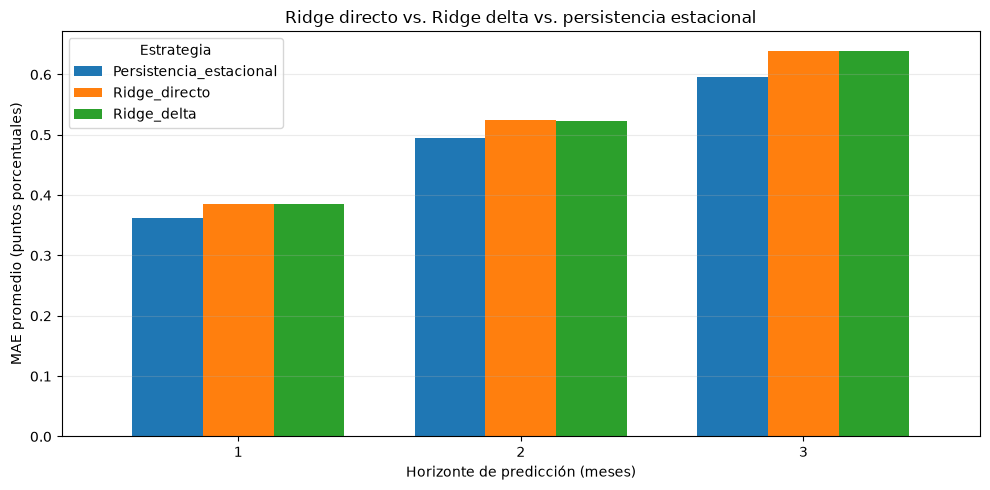

In [6]:
import matplotlib.pyplot as plt

# ======================================================
# COMPARACIÓN VISUAL DE MAE
# ======================================================

columnas_grafico = [
    "Persistencia_estacional",
    "Ridge_directo",
    "Ridge_delta",
]

ax = comparacion_e1[columnas_grafico].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
)

ax.set_title(
    "Ridge directo vs. Ridge delta vs. persistencia estacional"
)

ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE promedio (puntos porcentuales)")

ax.set_xticklabels(
    comparacion_e1.index,
    rotation=0,
)

ax.legend(title="Estrategia")

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

### Experimento con Random forest

In [7]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error

from src.modeling.models import construir_modelo
from src.modeling.delta import entrenar_predecir_delta
from src.modeling.baselines import predecir_persistencia_estacional
from src.modeling.data import TEST_INICIO


# ======================================================
# EXPERIMENTO E1.2
# RANDOM FOREST DIRECTO VS RANDOM FOREST DELTA
# ======================================================

resultados_rf = []
predicciones_individuales_rf = []


# ======================================================
# 1. RECORRER HORIZONTES
# ======================================================

for h, configuracion in datasets.items():

    datos = configuracion["desarrollo"]

    target = configuracion["target"]
    fecha_target = configuracion["fecha_target"]

    numericas = configuracion["numericas"]
    predictoras = configuracion["predictoras"]

    print(f"\n{'=' * 60}")
    print(f"RANDOM FOREST - HORIZONTE {h} MES(ES)")
    print(f"{'=' * 60}")

    # ==================================================
    # 2. RECORRER FOLDS TEMPORALES
    # ==================================================

    for fold in folds_cv[h]:

        anio = fold["fold"]

        train = datos.loc[fold["train_idx"]].copy()
        val = datos.loc[fold["val_idx"]].copy()

        # Garantías temporales.
        assert train[fecha_target].max() < val["fecha"].min()
        assert (val[fecha_target] < TEST_INICIO).all()

        # Predictores.
        X_train = train[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        y_train = train[target]
        y_real = val[target].to_numpy(dtype=float)

        # ==============================================
        # MODELO A: RANDOM FOREST DIRECTO
        # ==============================================

        modelo_directo = construir_modelo(
            "RandomForest",
            numericas,
        )

        modelo_directo.fit(X_train, y_train)

        pred_directo = modelo_directo.predict(X_val)

        # ==============================================
        # MODELO B: RANDOM FOREST DELTA
        # ==============================================

        pred_delta = entrenar_predecir_delta(
            nombre="RandomForest",
            entrenamiento=train,
            validacion=val,
            target=target,
            numericas=numericas,
            predictoras=predictoras,
            recortar=False,
        )

        # ==============================================
        # BASELINE: PERSISTENCIA ESTACIONAL
        # ==============================================

        pred_estacional = predecir_persistencia_estacional(
            entrenamiento=train,
            validacion=val,
            target=target,
            fecha_target=fecha_target,
        )

        # ==============================================
        # 3. EVALUAR
        # ==============================================

        predicciones = {
            "RandomForest_directo": pred_directo,
            "RandomForest_delta": pred_delta,
            "Persistencia_estacional": pred_estacional,
        }

        metricas_fold = {}

        for estrategia, pred in predicciones.items():

            assert len(pred) == len(y_real)
            assert np.isfinite(pred).all()

            mae = mean_absolute_error(y_real, pred)
            rmse = np.sqrt(mean_squared_error(y_real, pred))

            resultados_rf.append({
                "horizonte": h,
                "fold": anio,
                "estrategia": estrategia,
                "observaciones": len(val),
                "mae_pp": mae,
                "rmse_pp": rmse,
            })

            metricas_fold[estrategia] = mae

        # ==============================================
        # 4. CONSERVAR PREDICCIONES INDIVIDUALES
        # ==============================================

        predicciones_individuales_rf.append(
            pd.DataFrame({
                "horizonte": h,
                "fold": anio,
                "banco": val["banco"].to_numpy(),
                "fecha": val["fecha"].to_numpy(),
                "fecha_objetivo": val[fecha_target].to_numpy(),
                "morosidad_actual": val["morosidad_pp"].to_numpy(),
                "y_real": y_real,
                "pred_rf_directo": pred_directo,
                "pred_rf_delta": pred_delta,
                "pred_estacional": pred_estacional,
            })
        )

        # ==============================================
        # 5. MOSTRAR RESULTADOS DEL FOLD
        # ==============================================

        print(
            f"Fold {anio} | "
            f"Directo: {metricas_fold['RandomForest_directo']:.4f} | "
            f"Delta: {metricas_fold['RandomForest_delta']:.4f} | "
            f"Estacional: {metricas_fold['Persistencia_estacional']:.4f}",
            flush=True,
        )


# ======================================================
# 6. CONSOLIDAR RESULTADOS
# ======================================================

detalle_rf = pd.DataFrame(resultados_rf)

predicciones_rf = pd.concat(
    predicciones_individuales_rf,
    ignore_index=True,
)

# 3 horizontes x 5 folds x 3 estrategias.
assert len(detalle_rf) == 45

assert not predicciones_rf.duplicated(
    ["horizonte", "fold", "banco", "fecha"]
).any()

assert predicciones_rf[
    ["y_real", "pred_rf_directo", "pred_rf_delta"]
].notna().all().all()

print("\nEXPERIMENTO E1.2 FINALIZADO")
print("Evaluaciones:", len(detalle_rf))
print("Predicciones individuales:", len(predicciones_rf))


RANDOM FOREST - HORIZONTE 1 MES(ES)
Fold 2021 | Directo: 0.3964 | Delta: 0.3764 | Estacional: 0.3153
Fold 2022 | Directo: 0.3906 | Delta: 0.3817 | Estacional: 0.3866
Fold 2023 | Directo: 0.4306 | Delta: 0.3624 | Estacional: 0.4044
Fold 2024 | Directo: 0.5017 | Delta: 0.4005 | Estacional: 0.4461
Fold 2025 | Directo: 0.2886 | Delta: 0.2426 | Estacional: 0.2566

RANDOM FOREST - HORIZONTE 2 MES(ES)
Fold 2021 | Directo: 0.5092 | Delta: 0.6385 | Estacional: 0.4820
Fold 2022 | Directo: 0.5608 | Delta: 0.5193 | Estacional: 0.5493
Fold 2023 | Directo: 0.5086 | Delta: 0.4645 | Estacional: 0.4774
Fold 2024 | Directo: 0.6523 | Delta: 0.5953 | Estacional: 0.6044
Fold 2025 | Directo: 0.3974 | Delta: 0.3389 | Estacional: 0.3609

RANDOM FOREST - HORIZONTE 3 MES(ES)
Fold 2021 | Directo: 0.6061 | Delta: 0.8268 | Estacional: 0.5486
Fold 2022 | Directo: 0.6832 | Delta: 0.6236 | Estacional: 0.7160
Fold 2023 | Directo: 0.6585 | Delta: 0.5486 | Estacional: 0.5802
Fold 2024 | Directo: 0.7484 | Delta: 0.7157 

In [8]:
# ======================================================
# EXPERIMENTO E1.2
# COMPARACIÓN RANDOM FOREST DIRECTO VS DELTA
# ======================================================

# 1. Resumen de métricas por horizonte.
resumen_rf = (
    detalle_rf
    .groupby(["horizonte", "estrategia"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        rmse_medio=("rmse_pp", "mean"),
        folds=("fold", "count"),
    )
    .reset_index()
)

print("=== RESUMEN GENERAL ===")

display(
    resumen_rf
    .sort_values(["horizonte", "mae_medio"])
    .round(4)
)


# ======================================================
# 2. TABLA COMPARATIVA
# ======================================================

comparacion_rf = resumen_rf.pivot(
    index="horizonte",
    columns="estrategia",
    values="mae_medio",
)

comparacion_rf["mejora_vs_directo_pct"] = (
    (
        comparacion_rf["RandomForest_directo"]
        - comparacion_rf["RandomForest_delta"]
    )
    / comparacion_rf["RandomForest_directo"]
    * 100
)

comparacion_rf["mejora_vs_estacional_pct"] = (
    (
        comparacion_rf["Persistencia_estacional"]
        - comparacion_rf["RandomForest_delta"]
    )
    / comparacion_rf["Persistencia_estacional"]
    * 100
)

print("\n=== COMPARACIÓN RANDOM FOREST ===")

display(comparacion_rf.round(4))


# ======================================================
# 3. RESULTADOS POR FOLD
# ======================================================

tabla_folds_rf = detalle_rf.pivot(
    index=["horizonte", "fold"],
    columns="estrategia",
    values="mae_pp",
).reset_index()

print("\n=== COMPARACIÓN POR FOLD ===")

display(tabla_folds_rf.round(4))


# ======================================================
# 4. VERIFICAR REPRODUCIBILIDAD ACADÉMICA
# ======================================================

referencias_rf = {
    1: 0.4016,
    2: 0.5257,
    3: 0.6414,
}

for h, mae_esperado in referencias_rf.items():

    mae_obtenido = comparacion_rf.loc[
        h, "RandomForest_directo"
    ]

    assert round(float(mae_obtenido), 4) == mae_esperado, (
        f"Discrepancia académica en horizonte {h}"
    )

print("\nRANDOM FOREST DIRECTO: EQUIVALENCIA ACADÉMICA VALIDADA")

=== RESUMEN GENERAL ===


,horizonte,estrategia,mae_medio,mae_std,rmse_medio,folds
1,1,RandomForest_delta,0.3527,0.0630,0.7214,5
0,1,Persistencia_estacional,0.3618,0.0754,0.7648,5
2,1,RandomForest_directo,0.4016,0.0771,0.8496,5
3,2,Persistencia_estacional,0.4948,0.0913,0.9368,5
4,2,RandomForest_delta,0.5113,0.1175,0.9994,5
5,2,RandomForest_directo,0.5257,0.0926,0.9870,5
6,3,Persistencia_estacional,0.5963,0.1058,1.1184,5
7,3,RandomForest_delta,0.6257,0.1577,1.2799,5
8,3,RandomForest_directo,0.6414,0.0892,1.2313,5



=== COMPARACIÓN RANDOM FOREST ===


estrategia,Persistencia_estacional,RandomForest_delta,RandomForest_directo,mejora_vs_directo_pct,mejora_vs_estacional_pct
horizonte,,,,,
1,0.3618,0.3527,0.4016,12.1627,2.5115
2,0.4948,0.5113,0.5257,2.7353,-3.3369
3,0.5963,0.6257,0.6414,2.4504,-4.9311



=== COMPARACIÓN POR FOLD ===


estrategia,horizonte,fold,Persistencia_estacional,RandomForest_delta,RandomForest_directo
0,1,2021,0.3153,0.3764,0.3964
1,1,2022,0.3866,0.3817,0.3906
2,1,2023,0.4044,0.3624,0.4306
3,1,2024,0.4461,0.4005,0.5017
4,1,2025,0.2566,0.2426,0.2886
5,2,2021,0.4820,0.6385,0.5092
6,2,2022,0.5493,0.5193,0.5608
7,2,2023,0.4774,0.4645,0.5086
8,2,2024,0.6044,0.5953,0.6523
9,2,2025,0.3609,0.3389,0.3974



RANDOM FOREST DIRECTO: EQUIVALENCIA ACADÉMICA VALIDADA


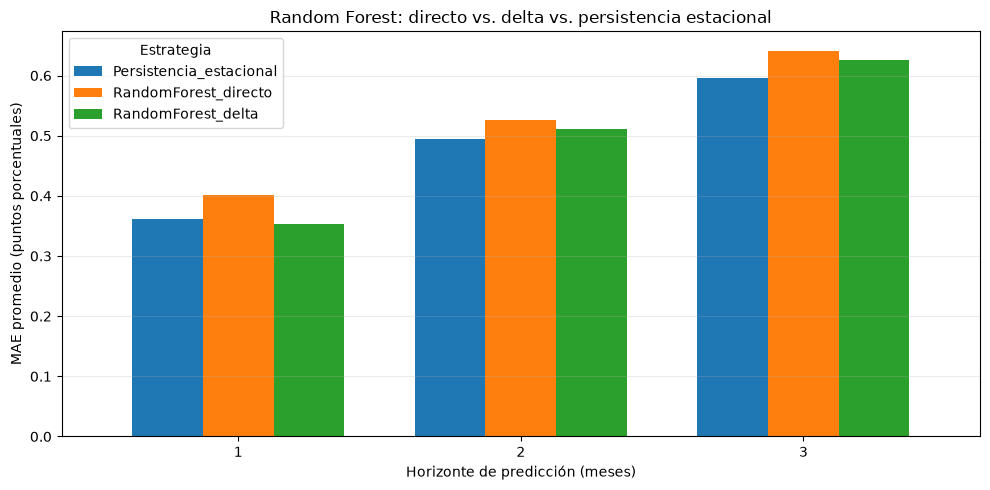

In [9]:
import matplotlib.pyplot as plt

# ======================================================
# COMPARACIÓN VISUAL DE RANDOM FOREST
# ======================================================

columnas_grafico = [
    "Persistencia_estacional",
    "RandomForest_directo",
    "RandomForest_delta",
]

ax = comparacion_rf[columnas_grafico].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
)

ax.set_title(
    "Random Forest: directo vs. delta vs. persistencia estacional"
)

ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE promedio (puntos porcentuales)")

ax.set_xticklabels(
    comparacion_rf.index,
    rotation=0,
)

ax.legend(title="Estrategia")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Experimento con HistGradientBoosting

In [10]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error

from src.modeling.models import construir_modelo
from src.modeling.delta import entrenar_predecir_delta
from src.modeling.baselines import predecir_persistencia_estacional
from src.modeling.data import TEST_INICIO


# ======================================================
# EXPERIMENTO E1.3
# HISTGRADIENTBOOSTING DIRECTO VS DELTA
# ======================================================

resultados_hgb = []
predicciones_individuales_hgb = []

for h, configuracion in datasets.items():

    datos = configuracion["desarrollo"]

    target = configuracion["target"]
    fecha_target = configuracion["fecha_target"]

    numericas = configuracion["numericas"]
    predictoras = configuracion["predictoras"]

    print(f"\n{'=' * 60}")
    print(f"HISTGRADIENTBOOSTING - HORIZONTE {h} MES(ES)")
    print(f"{'=' * 60}")

    for fold in folds_cv[h]:

        anio = fold["fold"]

        train = datos.loc[fold["train_idx"]].copy()
        val = datos.loc[fold["val_idx"]].copy()

        # ==============================================
        # 1. VERIFICAR INTEGRIDAD TEMPORAL
        # ==============================================

        assert train[fecha_target].max() < val["fecha"].min()
        assert (val[fecha_target] < TEST_INICIO).all()

        # ==============================================
        # 2. PREPARAR VARIABLES
        # ==============================================

        X_train = train[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        y_train = train[target]
        y_real = val[target].to_numpy(dtype=float)

        # ==============================================
        # 3. HISTGRADIENTBOOSTING DIRECTO
        # ==============================================

        modelo_directo = construir_modelo(
            "HistGradientBoosting",
            numericas,
        )

        modelo_directo.fit(X_train, y_train)

        pred_directo = modelo_directo.predict(X_val)

        # ==============================================
        # 4. HISTGRADIENTBOOSTING DELTA
        # ==============================================

        pred_delta = entrenar_predecir_delta(
            nombre="HistGradientBoosting",
            entrenamiento=train,
            validacion=val,
            target=target,
            numericas=numericas,
            predictoras=predictoras,
            recortar=False,
        )

        # ==============================================
        # 5. PERSISTENCIA ESTACIONAL
        # ==============================================

        pred_estacional = predecir_persistencia_estacional(
            entrenamiento=train,
            validacion=val,
            target=target,
            fecha_target=fecha_target,
        )

        # ==============================================
        # 6. CALCULAR MÉTRICAS
        # ==============================================

        predicciones = {
            "HistGB_directo": pred_directo,
            "HistGB_delta": pred_delta,
            "Persistencia_estacional": pred_estacional,
        }

        metricas_fold = {}

        for estrategia, pred in predicciones.items():

            assert len(pred) == len(y_real)
            assert np.isfinite(pred).all()

            mae = mean_absolute_error(y_real, pred)

            rmse = np.sqrt(
                mean_squared_error(y_real, pred)
            )

            resultados_hgb.append({
                "horizonte": h,
                "fold": anio,
                "estrategia": estrategia,
                "observaciones": len(val),
                "mae_pp": mae,
                "rmse_pp": rmse,
            })

            metricas_fold[estrategia] = mae

        # ==============================================
        # 7. CONSERVAR PREDICCIONES INDIVIDUALES
        # ==============================================

        predicciones_individuales_hgb.append(
            pd.DataFrame({
                "horizonte": h,
                "fold": anio,
                "banco": val["banco"].to_numpy(),
                "fecha": val["fecha"].to_numpy(),
                "fecha_objetivo": val[fecha_target].to_numpy(),
                "morosidad_actual": val["morosidad_pp"].to_numpy(),
                "y_real": y_real,
                "pred_hgb_directo": pred_directo,
                "pred_hgb_delta": pred_delta,
                "pred_estacional": pred_estacional,
            })
        )

        print(
            f"Fold {anio} | "
            f"Directo: {metricas_fold['HistGB_directo']:.4f} | "
            f"Delta: {metricas_fold['HistGB_delta']:.4f} | "
            f"Estacional: {metricas_fold['Persistencia_estacional']:.4f}",
            flush=True,
        )


# ======================================================
# 8. CONSOLIDAR RESULTADOS
# ======================================================

detalle_hgb = pd.DataFrame(resultados_hgb)

predicciones_hgb = pd.concat(
    predicciones_individuales_hgb,
    ignore_index=True,
)

# Tres horizontes, cinco folds y tres estrategias.
assert len(detalle_hgb) == 45

assert detalle_hgb.groupby(
    ["horizonte", "estrategia"]
)["fold"].nunique().eq(5).all()

assert not predicciones_hgb.duplicated(
    ["horizonte", "fold", "banco", "fecha"]
).any()

assert predicciones_hgb[
    ["y_real", "pred_hgb_directo", "pred_hgb_delta"]
].notna().all().all()

print("\nEXPERIMENTO E1.3 FINALIZADO")
print("Evaluaciones:", len(detalle_hgb))
print("Predicciones individuales:", len(predicciones_hgb))


HISTGRADIENTBOOSTING - HORIZONTE 1 MES(ES)
Fold 2021 | Directo: 0.7456 | Delta: 0.3601 | Estacional: 0.3153
Fold 2022 | Directo: 0.4433 | Delta: 0.3823 | Estacional: 0.3866
Fold 2023 | Directo: 0.4958 | Delta: 0.4258 | Estacional: 0.4044
Fold 2024 | Directo: 0.4551 | Delta: 0.4247 | Estacional: 0.4461
Fold 2025 | Directo: 0.2987 | Delta: 0.2363 | Estacional: 0.2566

HISTGRADIENTBOOSTING - HORIZONTE 2 MES(ES)
Fold 2021 | Directo: 0.9750 | Delta: 0.5449 | Estacional: 0.4820
Fold 2022 | Directo: 0.6079 | Delta: 0.5502 | Estacional: 0.5493
Fold 2023 | Directo: 0.5446 | Delta: 0.5167 | Estacional: 0.4774
Fold 2024 | Directo: 0.6333 | Delta: 0.6434 | Estacional: 0.6044
Fold 2025 | Directo: 0.3967 | Delta: 0.3648 | Estacional: 0.3609

HISTGRADIENTBOOSTING - HORIZONTE 3 MES(ES)
Fold 2021 | Directo: 1.0623 | Delta: 0.6058 | Estacional: 0.5486
Fold 2022 | Directo: 0.7165 | Delta: 0.6730 | Estacional: 0.7160
Fold 2023 | Directo: 0.6969 | Delta: 0.5827 | Estacional: 0.5802
Fold 2024 | Directo: 0.

In [11]:
# ======================================================
# EXPERIMENTO E1.3
# RESUMEN Y COMPARACIÓN
# ======================================================

# 1. MÉTRICAS PROMEDIO POR HORIZONTE
resumen_hgb = (
    detalle_hgb
    .groupby(["horizonte", "estrategia"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        rmse_medio=("rmse_pp", "mean"),
        folds=("fold", "count"),
    )
    .reset_index()
)

print("=== RESUMEN HISTGRADIENTBOOSTING ===")

display(
    resumen_hgb
    .sort_values(["horizonte", "mae_medio"])
    .round(4)
)


# ======================================================
# 2. COMPARACIÓN ENTRE FORMULACIONES
# ======================================================

comparacion_hgb = resumen_hgb.pivot(
    index="horizonte",
    columns="estrategia",
    values="mae_medio",
)

# Mejora porcentual frente a HistGB directo.
comparacion_hgb["mejora_vs_directo_pct"] = (
    (
        comparacion_hgb["HistGB_directo"]
        - comparacion_hgb["HistGB_delta"]
    )
    / comparacion_hgb["HistGB_directo"]
    * 100
)

# Mejora porcentual frente al baseline estacional.
comparacion_hgb["mejora_vs_estacional_pct"] = (
    (
        comparacion_hgb["Persistencia_estacional"]
        - comparacion_hgb["HistGB_delta"]
    )
    / comparacion_hgb["Persistencia_estacional"]
    * 100
)

print("\n=== COMPARACIÓN HISTGRADIENTBOOSTING ===")

display(comparacion_hgb.round(4))


# ======================================================
# 3. RESULTADOS POR FOLD
# ======================================================

tabla_folds_hgb = detalle_hgb.pivot(
    index=["horizonte", "fold"],
    columns="estrategia",
    values="mae_pp",
).reset_index()

print("\n=== RESULTADOS POR FOLD ===")

display(tabla_folds_hgb.round(4))


# ======================================================
# 4. VERIFICACIÓN DE REPRODUCIBILIDAD ACADÉMICA
# ======================================================

referencias_hgb = {
    1: 0.4877,
    2: 0.6315,
    3: 0.7466,
}

for h, mae_esperado in referencias_hgb.items():

    mae_obtenido = comparacion_hgb.loc[
        h, "HistGB_directo"
    ]

    assert round(float(mae_obtenido), 4) == mae_esperado, (
        f"Discrepancia académica en horizonte {h}: "
        f"{mae_obtenido:.6f}"
    )

print("\nHISTGRADIENTBOOSTING DIRECTO: EQUIVALENCIA VALIDADA")


# ======================================================
# 5. CONTAR FOLDS CON MEJORAS
# ======================================================

tabla_folds_hgb["delta_supera_directo"] = (
    tabla_folds_hgb["HistGB_delta"]
    < tabla_folds_hgb["HistGB_directo"]
)

tabla_folds_hgb["delta_supera_estacional"] = (
    tabla_folds_hgb["HistGB_delta"]
    < tabla_folds_hgb["Persistencia_estacional"]
)

consistencia_hgb = (
    tabla_folds_hgb
    .groupby("horizonte")
    .agg(
        folds_mejora_directo=("delta_supera_directo", "sum"),
        folds_mejora_estacional=("delta_supera_estacional", "sum"),
    )
)

print("\n=== CONSISTENCIA TEMPORAL ===")

display(consistencia_hgb)

=== RESUMEN HISTGRADIENTBOOSTING ===


,horizonte,estrategia,mae_medio,mae_std,rmse_medio,folds
2,1,Persistencia_estacional,0.3618,0.0754,0.7648,5
0,1,HistGB_delta,0.3659,0.0777,0.7622,5
1,1,HistGB_directo,0.4877,0.1623,1.1964,5
5,2,Persistencia_estacional,0.4948,0.0913,0.9368,5
3,2,HistGB_delta,0.5240,0.1010,1.0231,5
4,2,HistGB_directo,0.6315,0.2129,1.4103,5
8,3,Persistencia_estacional,0.5963,0.1058,1.1184,5
6,3,HistGB_delta,0.6203,0.1557,1.1933,5
7,3,HistGB_directo,0.7466,0.2045,1.6559,5



=== COMPARACIÓN HISTGRADIENTBOOSTING ===


estrategia,HistGB_delta,HistGB_directo,Persistencia_estacional,mejora_vs_directo_pct,mejora_vs_estacional_pct
horizonte,,,,,
1,0.3659,0.4877,0.3618,24.9793,-1.1226
2,0.5240,0.6315,0.4948,17.0217,-5.9055
3,0.6203,0.7466,0.5963,16.9204,-4.0259



=== RESULTADOS POR FOLD ===


estrategia,horizonte,fold,HistGB_delta,HistGB_directo,Persistencia_estacional
0,1,2021,0.3601,0.7456,0.3153
1,1,2022,0.3823,0.4433,0.3866
2,1,2023,0.4258,0.4958,0.4044
3,1,2024,0.4247,0.4551,0.4461
4,1,2025,0.2363,0.2987,0.2566
5,2,2021,0.5449,0.9750,0.4820
6,2,2022,0.5502,0.6079,0.5493
7,2,2023,0.5167,0.5446,0.4774
8,2,2024,0.6434,0.6333,0.6044
9,2,2025,0.3648,0.3967,0.3609



HISTGRADIENTBOOSTING DIRECTO: EQUIVALENCIA VALIDADA

=== CONSISTENCIA TEMPORAL ===


,folds_mejora_directo,folds_mejora_estacional
horizonte,,
1,5,3
2,4,0
3,4,2


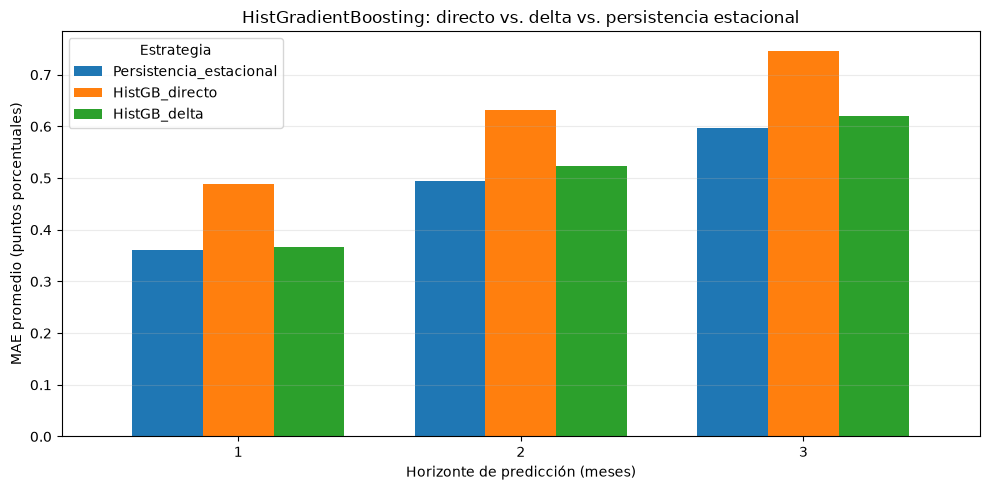

In [12]:
import matplotlib.pyplot as plt

# ======================================================
# COMPARACIÓN VISUAL HISTGRADIENTBOOSTING
# ======================================================

columnas_grafico = [
    "Persistencia_estacional",
    "HistGB_directo",
    "HistGB_delta",
]

ax = comparacion_hgb[columnas_grafico].plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
)

ax.set_title(
    "HistGradientBoosting: directo vs. delta vs. persistencia estacional"
)

ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE promedio (puntos porcentuales)")

ax.set_xticklabels(
    comparacion_hgb.index,
    rotation=0,
)

ax.legend(title="Estrategia")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### Consolidacion de los 8 modelos

In [13]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# EXPERIMENTO E1.4
# COMPARACIÓN INTEGRAL DE LOS OCHO ENFOQUES
# ======================================================

columnas = [
    "horizonte",
    "fold",
    "estrategia",
    "observaciones",
    "mae_pp",
]

# ======================================================
# 1. RECUPERAR LOS DOS BASELINES
# ======================================================

baselines = (
    detalle_baselines
    .rename(columns={"modelo": "estrategia"})
    [columnas]
    .copy()
)

# ======================================================
# 2. RECUPERAR LOS SEIS MODELOS SUPERVISADOS
# ======================================================

# Excluimos el baseline repetido en cada experimento.
ridge = detalle_e1.loc[
    detalle_e1["estrategia"] != "Persistencia_estacional",
    columnas,
].copy()

random_forest = detalle_rf.loc[
    detalle_rf["estrategia"] != "Persistencia_estacional",
    columnas,
].copy()

histgb = detalle_hgb.loc[
    detalle_hgb["estrategia"] != "Persistencia_estacional",
    columnas,
].copy()

# ======================================================
# 3. CONSOLIDAR LAS EVALUACIONES
# ======================================================

detalle_e1_completo = pd.concat(
    [baselines, ridge, random_forest, histgb],
    ignore_index=True,
)

# 8 estrategias x 3 horizontes x 5 folds.
assert len(detalle_e1_completo) == 120

assert detalle_e1_completo["estrategia"].nunique() == 8

assert not detalle_e1_completo.duplicated(
    ["horizonte", "fold", "estrategia"]
).any()

assert (
    detalle_e1_completo.groupby(
        ["horizonte", "estrategia"]
    )["fold"].nunique() == 5
).all()

# Todos deben usar los mismos tamaños de validación.
assert (
    detalle_e1_completo.groupby(
        ["horizonte", "fold"]
    )["observaciones"].nunique() == 1
).all()

# ======================================================
# 4. CALCULAR EL MAE PROMEDIO
# ======================================================

resumen_e1_completo = (
    detalle_e1_completo
    .groupby(["horizonte", "estrategia"])
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count"),
    )
    .reset_index()
)

# ======================================================
# 5. INCORPORAR EL BASELINE DE REFERENCIA
# ======================================================

referencias = (
    resumen_e1_completo.loc[
        resumen_e1_completo["estrategia"]
        == "Persistencia_estacional",
        ["horizonte", "mae_medio"],
    ]
    .rename(columns={"mae_medio": "mae_baseline"})
)

resumen_e1_completo = resumen_e1_completo.merge(
    referencias,
    on="horizonte",
    validate="many_to_one",
)

# ======================================================
# 6. CALCULAR MEJORA FRENTE AL BASELINE
# ======================================================

resumen_e1_completo["mejora_vs_baseline_pct"] = (
    (
        resumen_e1_completo["mae_baseline"]
        - resumen_e1_completo["mae_medio"]
    )
    / resumen_e1_completo["mae_baseline"]
    * 100
)

# ======================================================
# 7. ORDENAR Y ASIGNAR POSICIONES
# ======================================================

resumen_e1_completo = (
    resumen_e1_completo
    .sort_values(["horizonte", "mae_medio"])
    .reset_index(drop=True)
)

resumen_e1_completo["posicion"] = (
    resumen_e1_completo.groupby("horizonte").cumcount() + 1
)

# ======================================================
# 8. MOSTRAR RESULTADOS
# ======================================================

print("=== COMPARACIÓN DE LAS OCHO ESTRATEGIAS ===")

display(
    resumen_e1_completo[
        [
            "horizonte",
            "posicion",
            "estrategia",
            "mae_medio",
            "mae_std",
            "mejora_vs_baseline_pct",
        ]
    ].round(4)
)

# ======================================================
# 9. MEJOR ESTRATEGIA POR HORIZONTE
# ======================================================

mejores_e1 = resumen_e1_completo.loc[
    resumen_e1_completo["posicion"] == 1
]

print("\n=== MEJOR ESTRATEGIA POR HORIZONTE ===")

display(
    mejores_e1[
        ["horizonte", "estrategia", "mae_medio"]
    ].round(4)
)

print("\n120 EVALUACIONES CONSOLIDADAS")
print("COMPARACIÓN E1: VALIDADA")

=== COMPARACIÓN DE LAS OCHO ESTRATEGIAS ===


,horizonte,posicion,estrategia,mae_medio,mae_std,mejora_vs_baseline_pct
0,1,1,RandomForest_delta,0.3527,0.0630,2.5115
1,1,2,Persistencia_estacional,0.3618,0.0754,0.0000
2,1,3,HistGB_delta,0.3659,0.0777,-1.1226
3,1,4,Persistencia,0.3702,0.0789,-2.3205
4,1,5,Ridge_delta,0.3848,0.0879,-6.3668
5,1,6,Ridge_directo,0.3857,0.0881,-6.6083
6,1,7,RandomForest_directo,0.4016,0.0771,-10.9875
7,1,8,HistGB_directo,0.4877,0.1623,-34.7929
8,2,1,Persistencia_estacional,0.4948,0.0913,0.0000
9,2,2,Persistencia,0.5025,0.0949,-1.5585



=== MEJOR ESTRATEGIA POR HORIZONTE ===


,horizonte,estrategia,mae_medio
0,1,RandomForest_delta,0.3527
8,2,Persistencia_estacional,0.4948
16,3,Persistencia_estacional,0.5963



120 EVALUACIONES CONSOLIDADAS
COMPARACIÓN E1: VALIDADA


### Comprobar la consistencia temporal

In [14]:
# ======================================================
# EXPERIMENTO E1.4
# CONSISTENCIA TEMPORAL DE LOS MODELOS DELTA
# ======================================================

tabla_folds_completa = detalle_e1_completo.pivot(
    index=["horizonte", "fold"],
    columns="estrategia",
    values="mae_pp",
)

modelos = [
    "Ridge",
    "RandomForest",
    "HistGB",
]

resultados_consistencia = []

for h in (1, 2, 3):

    datos_h = tabla_folds_completa.loc[h]

    baseline = datos_h["Persistencia_estacional"]

    for modelo in modelos:

        directo = datos_h[f"{modelo}_directo"]
        delta = datos_h[f"{modelo}_delta"]

        resultados_consistencia.append({
            "horizonte": h,
            "modelo": modelo,
            "mejora_vs_directo_folds": int(
                (delta < directo).sum()
            ),
            "mejora_vs_estacional_folds": int(
                (delta < baseline).sum()
            ),
            "diferencia_mae_vs_baseline": (
                delta.mean() - baseline.mean()
            ),
        })

consistencia_e1 = pd.DataFrame(resultados_consistencia)

print("=== CONSISTENCIA TEMPORAL DE LOS MODELOS DELTA ===")

display(consistencia_e1.round(4))

=== CONSISTENCIA TEMPORAL DE LOS MODELOS DELTA ===


,horizonte,modelo,mejora_vs_directo_folds,mejora_vs_estacional_folds,diferencia_mae_vs_baseline
0,1,Ridge,5,0,0.0230
1,1,RandomForest,5,4,-0.0091
2,1,HistGB,5,3,0.0041
3,2,Ridge,5,1,0.0289
4,2,RandomForest,4,4,0.0165
5,2,HistGB,4,0,0.0292
6,3,Ridge,5,1,0.0427
7,3,RandomForest,4,3,0.0294
8,3,HistGB,4,2,0.0240


## Analisis de Errores predictivos

### Tabla de predicciones

In [15]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# EXPERIMENTO E2.1
# CONSOLIDACIÓN DE PREDICCIONES INDIVIDUALES
# ======================================================

claves = ["horizonte", "fold", "banco", "fecha"]

contexto = [
    "fecha_objetivo",
    "morosidad_actual",
    "y_real",
    "pred_estacional",
]


# ======================================================
# 1. VALIDAR LA ALINEACIÓN DE LOS EXPERIMENTOS
# ======================================================

def validar_alineacion(referencia, candidato, nombre):

    assert len(referencia) == len(candidato)

    assert not referencia.duplicated(claves).any()
    assert not candidato.duplicated(claves).any()

    ref = referencia.sort_values(claves).reset_index(drop=True)
    otro = candidato.sort_values(claves).reset_index(drop=True)

    pd.testing.assert_frame_equal(
        ref[claves],
        otro[claves],
        check_dtype=False,
    )

    assert (
        pd.to_datetime(ref["fecha_objetivo"])
        .equals(pd.to_datetime(otro["fecha_objetivo"]))
    )

    for columna in [
        "morosidad_actual",
        "y_real",
        "pred_estacional",
    ]:
        np.testing.assert_allclose(
            ref[columna].to_numpy(dtype=float),
            otro[columna].to_numpy(dtype=float),
            rtol=0,
            atol=1e-10,
        )

    print(f"Alineación validada: {nombre}")


validar_alineacion(
    predicciones_e1,
    predicciones_rf,
    "Random Forest",
)

validar_alineacion(
    predicciones_e1,
    predicciones_hgb,
    "HistGradientBoosting",
)


# ======================================================
# 2. CONSTRUIR TABLA ANCHA
# ======================================================

predicciones_completas = (
    predicciones_e1[
        claves + contexto + ["pred_directo", "pred_delta"]
    ]
    .rename(columns={
        "morosidad_actual": "Persistencia",
        "pred_estacional": "Persistencia_estacional",
        "pred_directo": "Ridge_directo",
        "pred_delta": "Ridge_delta",
    })
    .copy()
)

rf = predicciones_rf[
    claves + ["pred_rf_directo", "pred_rf_delta"]
].rename(columns={
    "pred_rf_directo": "RandomForest_directo",
    "pred_rf_delta": "RandomForest_delta",
})

hgb = predicciones_hgb[
    claves + ["pred_hgb_directo", "pred_hgb_delta"]
].rename(columns={
    "pred_hgb_directo": "HistGB_directo",
    "pred_hgb_delta": "HistGB_delta",
})

predicciones_completas = predicciones_completas.merge(
    rf,
    on=claves,
    how="inner",
    validate="one_to_one",
)

predicciones_completas = predicciones_completas.merge(
    hgb,
    on=claves,
    how="inner",
    validate="one_to_one",
)


# ======================================================
# 3. VALIDAR LAS OCHO ESTRATEGIAS
# ======================================================

estrategias = [
    "Persistencia",
    "Persistencia_estacional",
    "Ridge_directo",
    "Ridge_delta",
    "RandomForest_directo",
    "RandomForest_delta",
    "HistGB_directo",
    "HistGB_delta",
]

assert len(predicciones_completas) == len(predicciones_e1)
assert len(predicciones_completas) == 3795

assert np.isfinite(
    predicciones_completas[estrategias].to_numpy(dtype=float)
).all()

print("\nPredicciones consolidadas:")
print(predicciones_completas.shape)

display(predicciones_completas.head())


# ======================================================
# 4. TRANSFORMAR A FORMATO LARGO
# ======================================================

errores_e2 = predicciones_completas.melt(
    id_vars=claves + ["fecha_objetivo", "y_real"],
    value_vars=estrategias,
    var_name="estrategia",
    value_name="y_pred",
)

# Error con signo: positivo significa subestimación.
errores_e2["error_pp"] = (
    errores_e2["y_real"] - errores_e2["y_pred"]
)

errores_e2["error_abs_pp"] = errores_e2["error_pp"].abs()

errores_e2["error_cuadrado"] = errores_e2["error_pp"] ** 2

assert len(errores_e2) == 3795 * 8


# ======================================================
# 5. COMPROBAR EQUIVALENCIA CON E1
# ======================================================

mae_recalculados = (
    errores_e2
    .groupby(["horizonte", "fold", "estrategia"], as_index=False)
    .agg(
        mae_recalculado=("error_abs_pp", "mean"),
        observaciones=("error_abs_pp", "size"),
    )
)

referencia = detalle_e1_completo[
    ["horizonte", "fold", "estrategia", "mae_pp", "observaciones"]
]

verificacion = mae_recalculados.merge(
    referencia,
    on=["horizonte", "fold", "estrategia"],
    suffixes=("_nuevo", "_original"),
    validate="one_to_one",
)

assert len(verificacion) == 120

np.testing.assert_allclose(
    verificacion["mae_recalculado"],
    verificacion["mae_pp"],
    rtol=0,
    atol=1e-10,
)

assert (
    verificacion["observaciones_nuevo"]
    == verificacion["observaciones_original"]
).all()

print("\n120 evaluaciones E1 reproducidas correctamente.")
print("30.360 errores individuales disponibles.")

Alineación validada: Random Forest
Alineación validada: HistGradientBoosting

Predicciones consolidadas:
(3795, 14)


,horizonte,fold,banco,fecha,fecha_objetivo,Persistencia,y_real,Persistencia_estacional,Ridge_directo,Ridge_delta,RandomForest_directo,RandomForest_delta,HistGB_directo,HistGB_delta
0,1,2021,BANCO ATLANTIDA S.A.,2021-01-01,2021-02-01,8.254634,6.294446,8.445269,8.760705,8.758396,8.178596,8.270495,8.686259,8.617192
1,1,2021,BANCO COMERCIAL DE MANABI,2021-01-01,2021-02-01,7.094435,8.198678,7.285070,7.614399,7.604603,7.551904,7.398582,8.116763,7.810201
2,1,2021,BP AMAZONAS,2021-01-01,2021-02-01,2.534511,2.640828,2.725146,2.931725,2.929240,2.826044,2.739596,2.974253,2.875044
3,1,2021,BP AUSTRO,2021-01-01,2021-02-01,3.956731,3.717254,4.147366,3.902561,3.894162,3.813010,4.042322,3.660995,4.016199
4,1,2021,"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODES...",2021-01-01,2021-02-01,7.462652,7.516523,7.653287,7.547858,7.543276,7.801037,7.614117,8.076317,7.767825



120 evaluaciones E1 reproducidas correctamente.
30.360 errores individuales disponibles.


### analisis temporal de random forest delta a un mes

In [16]:
# ======================================================
# EXPERIMENTO E2.2
# ANÁLISIS PAREADO: RANDOM FOREST DELTA, HORIZONTE 1
# ======================================================

rf_h1 = predicciones_completas.loc[
    predicciones_completas["horizonte"] == 1
].copy()

# ======================================================
# 1. CALCULAR ERRORES INDIVIDUALES
# ======================================================

rf_h1["error_rf"] = (
    rf_h1["y_real"] - rf_h1["RandomForest_delta"]
).abs()

rf_h1["error_estacional"] = (
    rf_h1["y_real"] - rf_h1["Persistencia_estacional"]
).abs()

rf_h1["ventaja_rf_pp"] = (
    rf_h1["error_estacional"] - rf_h1["error_rf"]
)

rf_h1["rf_mejora"] = rf_h1["ventaja_rf_pp"] > 0


# ======================================================
# 2. RESUMEN POR AÑO DE VALIDACIÓN
# ======================================================

analisis_anual_rf = (
    rf_h1
    .groupby("fold")
    .agg(
        observaciones=("error_rf", "size"),
        mae_rf=("error_rf", "mean"),
        mae_estacional=("error_estacional", "mean"),
        ventaja_media_pp=("ventaja_rf_pp", "mean"),
        proporcion_mejoras=("rf_mejora", "mean"),
    )
)

analisis_anual_rf["mejora_pct"] = (
    analisis_anual_rf["ventaja_media_pp"]
    / analisis_anual_rf["mae_estacional"]
    * 100
)

analisis_anual_rf["observaciones_mejoradas_pct"] = (
    analisis_anual_rf["proporcion_mejoras"] * 100
)

print("=== RANDOM FOREST DELTA: ANÁLISIS POR AÑO ===")

display(
    analisis_anual_rf[
        [
            "observaciones",
            "mae_rf",
            "mae_estacional",
            "ventaja_media_pp",
            "mejora_pct",
            "observaciones_mejoradas_pct",
        ]
    ].round(4)
)


# ======================================================
# 3. RESUMEN POR BANCO
# ======================================================

analisis_bancos_rf = (
    rf_h1
    .groupby("banco")
    .agg(
        observaciones=("error_rf", "size"),
        folds=("fold", "nunique"),
        mae_rf=("error_rf", "mean"),
        mae_estacional=("error_estacional", "mean"),
        ventaja_media_pp=("ventaja_rf_pp", "mean"),
        proporcion_mejoras=("rf_mejora", "mean"),
    )
)

analisis_bancos_rf["mejora_pct"] = (
    analisis_bancos_rf["ventaja_media_pp"]
    / analisis_bancos_rf["mae_estacional"]
    * 100
)

analisis_bancos_rf = analisis_bancos_rf.sort_values(
    "mejora_pct",
    ascending=False,
)

print("\n=== BANCOS CON MAYOR MEJORA ===")

display(analisis_bancos_rf.head(8).round(4))

print("\n=== BANCOS CON MENOR MEJORA ===")

display(analisis_bancos_rf.tail(8).round(4))


# ======================================================
# 4. COMPROBAR EL BALANCE GLOBAL
# ======================================================

bancos_mejorados = (
    analisis_bancos_rf["ventaja_media_pp"] > 0
).sum()

print(
    f"\nBancos donde RF delta mejora al baseline: "
    f"{bancos_mejorados}/{len(analisis_bancos_rf)}"
)

print(
    f"Folds donde RF delta mejora al baseline: "
    f"{(analisis_anual_rf['ventaja_media_pp'] > 0).sum()}/5"
)

print(
    "\nVentaja media agregada por observación:",
    round(rf_h1["ventaja_rf_pp"].mean(), 6),
    "pp",
)

=== RANDOM FOREST DELTA: ANÁLISIS POR AÑO ===


,observaciones,mae_rf,mae_estacional,ventaja_media_pp,mejora_pct,observaciones_mejoradas_pct
fold,,,,,,
2021,276,0.3764,0.3153,-0.0612,-19.3992,44.9275
2022,276,0.3817,0.3866,0.0049,1.2691,47.1014
2023,276,0.3624,0.4044,0.0420,10.3892,55.4348
2024,276,0.4005,0.4461,0.0456,10.2305,55.7971
2025,184,0.2426,0.2566,0.0140,5.4667,51.0870



=== BANCOS CON MAYOR MEJORA ===


,observaciones,folds,mae_rf,mae_estacional,ventaja_media_pp,proporcion_mejoras,mejora_pct
banco,,,,,,,
BP INTERNACIONAL,56,5,0.0776,0.1010,0.0234,0.5893,23.1887
BP BOLIVARIANO,56,5,0.0947,0.1208,0.0261,0.5536,21.6110
BP MACHALA,56,5,0.1438,0.1754,0.0316,0.5893,18.0309
BP LITORAL,56,5,0.8176,0.9576,0.1400,0.6607,14.6213
BP GUAYAQUIL,56,5,0.1216,0.1413,0.0197,0.5000,13.9116
BANCO COMERCIAL DE MANABI,56,5,0.8876,1.0245,0.1369,0.5714,13.3629
BP AMAZONAS,56,5,0.3943,0.4509,0.0566,0.5536,12.5426
BP GENERAL RUMINAHUI,56,5,0.2310,0.2540,0.0230,0.5179,9.0449



=== BANCOS CON MENOR MEJORA ===


,observaciones,folds,mae_rf,mae_estacional,ventaja_media_pp,proporcion_mejoras,mejora_pct
banco,,,,,,,
BP DINERS,56,5,0.1597,0.1592,-0.0005,0.3750,-0.3320
"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODESARROLLO",56,5,0.3618,0.3539,-0.0079,0.5357,-2.2203
BP VISIONFUND ECUADOR S.A.,56,5,0.2646,0.2551,-0.0095,0.6071,-3.7178
BP LOJA,56,5,0.2094,0.2007,-0.0088,0.5000,-4.3737
BP DELBANK,56,5,0.5740,0.5389,-0.0351,0.3929,-6.5113
BP SOLIDARIO,56,5,0.2845,0.2626,-0.0220,0.4821,-8.3684
BP CAPITAL,56,5,1.5001,1.2670,-0.2331,0.4286,-18.3984
BP CITIBANK,56,5,0.0721,0.0561,-0.0160,0.1607,-28.4720



Bancos donde RF delta mejora al baseline: 15/23
Folds donde RF delta mejora al baseline: 4/5

Ventaja media agregada por observación: 0.008734 pp


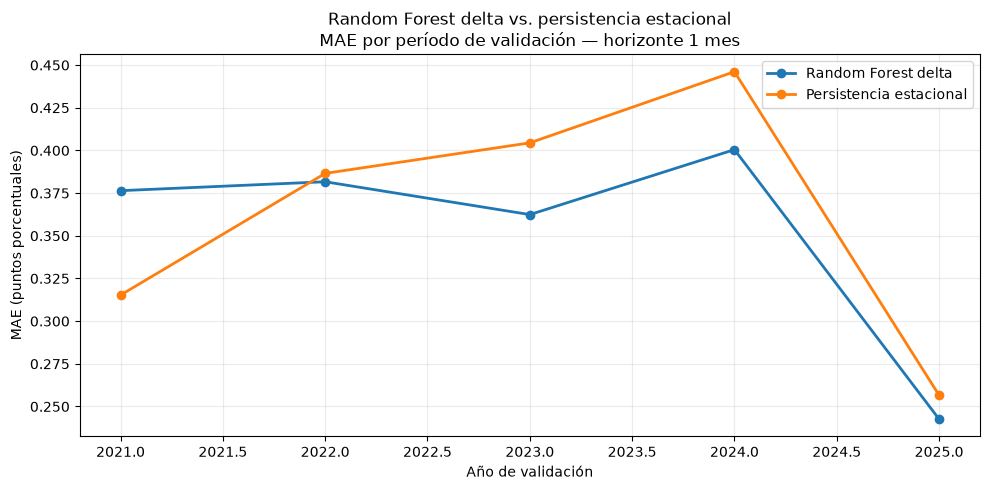

In [17]:
import matplotlib.pyplot as plt

# ======================================================
# EVOLUCIÓN TEMPORAL DEL MAE
# ======================================================

ax = analisis_anual_rf[
    ["mae_rf", "mae_estacional"]
].plot(
    kind="line",
    marker="o",
    linewidth=2,
    figsize=(10, 5),
)

ax.set_title(
    "Random Forest delta vs. persistencia estacional\n"
    "MAE por período de validación — horizonte 1 mes"
)

ax.set_xlabel("Año de validación")
ax.set_ylabel("MAE (puntos porcentuales)")

ax.legend(
    ["Random Forest delta", "Persistencia estacional"]
)

ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Cambios bruscos y errores extremos

In [18]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# E2.3 - PREPARAR ERRORES Y VARIACIONES
# ======================================================

columnas = [
    "horizonte",
    "fold",
    "banco",
    "fecha",
    "fecha_objetivo",
    "Persistencia",
    "y_real",
    "Persistencia_estacional",
    "RandomForest_delta",
]

datos_e23 = predicciones_completas[columnas].copy()

# ======================================================
# 1. CALCULAR LA VARIACIÓN REAL
# ======================================================

datos_e23["delta_real_pp"] = (
    datos_e23["y_real"]
    - datos_e23["Persistencia"]
)

datos_e23["abs_delta_real_pp"] = (
    datos_e23["delta_real_pp"].abs()
)

# Variación pronosticada por Random Forest.
datos_e23["delta_pred_rf_pp"] = (
    datos_e23["RandomForest_delta"]
    - datos_e23["Persistencia"]
)

# ======================================================
# 2. CALCULAR ERRORES INDIVIDUALES
# ======================================================

datos_e23["error_rf_pp"] = (
    datos_e23["y_real"]
    - datos_e23["RandomForest_delta"]
).abs()

datos_e23["error_estacional_pp"] = (
    datos_e23["y_real"]
    - datos_e23["Persistencia_estacional"]
).abs()

# Positivo: Random Forest mejora al baseline.
datos_e23["ventaja_rf_pp"] = (
    datos_e23["error_estacional_pp"]
    - datos_e23["error_rf_pp"]
)

# ======================================================
# 3. CLASIFICAR CAMBIOS REALES
# ======================================================

UMBRAL_CAMBIO = 0.10

datos_e23["direccion"] = np.select(
    [
        datos_e23["delta_real_pp"] > UMBRAL_CAMBIO,
        datos_e23["delta_real_pp"] < -UMBRAL_CAMBIO,
    ],
    [
        "Aumento",
        "Disminucion",
    ],
    default="Estabilidad",
)

# ======================================================
# 4. RESUMIR POR HORIZONTE Y DIRECCIÓN
# ======================================================

resumen_direccion = (
    datos_e23
    .groupby(
        ["horizonte", "direccion"],
        as_index=False,
    )
    .agg(
        observaciones=("error_rf_pp", "size"),
        cambio_medio_pp=("delta_real_pp", "mean"),
        mae_rf=("error_rf_pp", "mean"),
        mae_estacional=("error_estacional_pp", "mean"),
        ventaja_media_pp=("ventaja_rf_pp", "mean"),
    )
)

resumen_direccion["mejora_pct"] = (
    100
    * resumen_direccion["ventaja_media_pp"]
    / resumen_direccion["mae_estacional"].replace(0, np.nan)
)

print("=== ERRORES SEGÚN LA DIRECCIÓN DEL CAMBIO ===")

display(resumen_direccion.round(4))

# ======================================================
# 5. COMPROBACIONES
# ======================================================

assert len(datos_e23) == 3795

assert (
    resumen_direccion
    .groupby("horizonte")["observaciones"]
    .sum()
    .to_dict()
    == {1: 1288, 2: 1265, 3: 1242}
)

assert np.isfinite(
    datos_e23[
        [
            "delta_real_pp",
            "error_rf_pp",
            "error_estacional_pp",
        ]
    ].to_numpy()
).all()

print("\nANÁLISIS POR DIRECCIÓN: VALIDADO")

=== ERRORES SEGÚN LA DIRECCIÓN DEL CAMBIO ===


,horizonte,direccion,observaciones,cambio_medio_pp,mae_rf,mae_estacional,ventaja_media_pp,mejora_pct
0,1,Aumento,425,0.5428,0.4717,0.5067,0.0351,6.9178
1,1,Disminucion,368,-0.6446,0.5840,0.5828,-0.0012,-0.2053
2,1,Estabilidad,495,0.0072,0.0991,0.0927,-0.0065,-6.9950
3,2,Aumento,474,0.6736,0.6197,0.6480,0.0283,4.3643
4,2,Disminucion,423,-0.7527,0.8077,0.6927,-0.1150,-16.6065
5,2,Estabilidad,368,0.0024,0.0849,0.1119,0.0270,24.1484
6,3,Aumento,497,0.7675,0.6664,0.7638,0.0974,12.7551
7,3,Disminucion,440,-0.8509,1.0138,0.8025,-0.2113,-26.3267
8,3,Estabilidad,305,0.0046,0.0953,0.0903,-0.0050,-5.5231



ANÁLISIS POR DIRECCIÓN: VALIDADO


In [19]:
# ======================================================
# E2.3 - MAGNITUD DE LOS CAMBIOS DE MOROSIDAD
# ======================================================

# 1. Calcular umbrales por horizonte.
datos_e23["p75_pp"] = (
    datos_e23
    .groupby("horizonte")["abs_delta_real_pp"]
    .transform(lambda x: x.quantile(0.75))
)

datos_e23["p90_pp"] = (
    datos_e23
    .groupby("horizonte")["abs_delta_real_pp"]
    .transform(lambda x: x.quantile(0.90))
)

# ======================================================
# 2. CLASIFICAR SEGÚN MAGNITUD
# ======================================================

datos_e23["magnitud"] = np.select(
    [
        datos_e23["abs_delta_real_pp"] > datos_e23["p90_pp"],
        datos_e23["abs_delta_real_pp"] > datos_e23["p75_pp"],
    ],
    [
        "Extremo (>P90)",
        "Alto (P75-P90)",
    ],
    default="Habitual (<=P75)",
)

# ======================================================
# 3. MOSTRAR UMBRALES
# ======================================================

umbrales_e23 = (
    datos_e23
    .groupby("horizonte")
    .agg(
        p75_pp=("p75_pp", "first"),
        p90_pp=("p90_pp", "first"),
    )
)

print("=== UMBRALES DE CAMBIOS POR HORIZONTE ===")

display(umbrales_e23.round(4))

# ======================================================
# 4. EVALUAR LOS MODELOS SEGÚN MAGNITUD
# ======================================================

resumen_magnitud = (
    datos_e23
    .groupby(
        ["horizonte", "magnitud"],
        as_index=False,
    )
    .agg(
        observaciones=("error_rf_pp", "size"),
        cambio_abs_medio_pp=("abs_delta_real_pp", "mean"),
        mae_rf=("error_rf_pp", "mean"),
        mae_estacional=("error_estacional_pp", "mean"),
        ventaja_media_pp=("ventaja_rf_pp", "mean"),
    )
)

resumen_magnitud["mejora_pct"] = (
    100
    * resumen_magnitud["ventaja_media_pp"]
    / resumen_magnitud["mae_estacional"].replace(0, np.nan)
)

print("\n=== RENDIMIENTO SEGÚN MAGNITUD DEL CAMBIO ===")

display(
    resumen_magnitud
    .sort_values(["horizonte", "cambio_abs_medio_pp"])
    .round(4)
)

assert (
    resumen_magnitud
    .groupby("horizonte")["observaciones"]
    .sum()
    .to_dict()
    == {1: 1288, 2: 1265, 3: 1242}
)

print("\nANÁLISIS DE MAGNITUD: VALIDADO")

=== UMBRALES DE CAMBIOS POR HORIZONTE ===


,p75_pp,p90_pp
horizonte,,
1,0.4059,0.9232
2,0.5981,1.2297
3,0.6737,1.5466



=== RENDIMIENTO SEGÚN MAGNITUD DEL CAMBIO ===


,horizonte,magnitud,observaciones,cambio_abs_medio_pp,mae_rf,mae_estacional,ventaja_media_pp,mejora_pct
2,1,Habitual (<=P75),966,0.1251,0.1575,0.1495,-0.0080,-5.3806
0,1,Alto (P75-P90),193,0.5975,0.5686,0.5102,-0.0584,-11.4532
1,1,Extremo (>P90),129,1.9462,1.5701,1.8049,0.2348,13.0115
5,2,Habitual (<=P75),949,0.1864,0.2137,0.2102,-0.0035,-1.6611
3,2,Alto (P75-P90),189,0.8325,0.8471,0.7310,-0.1161,-15.8854
4,2,Extremo (>P90),127,2.5004,2.3914,2.3910,-0.0004,-0.0162
8,3,Habitual (<=P75),931,0.2250,0.2462,0.2347,-0.0114,-4.8770
6,3,Alto (P75-P90),186,0.9997,1.0023,0.9460,-0.0563,-5.9537
7,3,Extremo (>P90),125,2.9803,3.1259,2.9264,-0.1995,-6.8155



ANÁLISIS DE MAGNITUD: VALIDADO


In [20]:
# ======================================================
# E2.3 - ANÁLISIS DE ERRORES EXTREMOS
# HORIZONTE 1 MES
# ======================================================

h1_e23 = datos_e23.loc[
    datos_e23["horizonte"] == 1
].copy()

# Error más grande entre las dos estrategias,
# para seleccionar observaciones sin favorecer
# exclusivamente a uno de los modelos.
h1_e23["max_error_pp"] = h1_e23[
    ["error_rf_pp", "error_estacional_pp"]
].max(axis=1)

columnas_casos = [
    "fold",
    "banco",
    "fecha",
    "Persistencia",
    "y_real",
    "delta_real_pp",
    "RandomForest_delta",
    "Persistencia_estacional",
    "error_rf_pp",
    "error_estacional_pp",
    "ventaja_rf_pp",
]

# ======================================================
# 1. MAYORES ERRORES ABSOLUTOS
# ======================================================

casos_extremos = (
    h1_e23
    .nlargest(12, "max_error_pp")
    [columnas_casos]
)

print("=== 12 CASOS CON MAYORES ERRORES ===")

display(casos_extremos.round(4))


# ======================================================
# 2. CASOS DONDE RANDOM FOREST EMPEORA MÁS
# ======================================================

peores_casos_rf = (
    h1_e23
    .nsmallest(10, "ventaja_rf_pp")
    [columnas_casos]
)

print("\n=== 10 MAYORES DETERIOROS DE RANDOM FOREST ===")

display(peores_casos_rf.round(4))


# ======================================================
# 3. CASOS DONDE RANDOM FOREST MEJORA MÁS
# ======================================================

mejores_casos_rf = (
    h1_e23
    .nlargest(10, "ventaja_rf_pp")
    [columnas_casos]
)

print("\n=== 10 MAYORES MEJORAS DE RANDOM FOREST ===")

display(mejores_casos_rf.round(4))

=== 12 CASOS CON MAYORES ERRORES ===


/tmp/ipykernel_52599/1139076942.py:43: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(casos_extremos.round(4))


,fold,banco,fecha,Persistencia,y_real,delta_real_pp,RandomForest_delta,Persistencia_estacional,error_rf_pp,error_estacional_pp,ventaja_rf_pp
507,2022,BANCO COMERCIAL DE MANABI,2022-11-01,14.7833,3.2863,-11.4970,10.8581,14.3290,7.5717,11.0427,3.4709
1041,2024,BP CAPITAL,2024-10-01,14.5265,4.9525,-9.5740,14.6312,14.5569,9.6787,9.6044,-0.0743
742,2023,BP CAPITAL,2023-09-01,10.3332,19.5079,9.1747,10.4380,10.3777,9.0699,9.1302,0.0604
765,2023,BP CAPITAL,2023-10-01,19.5079,12.2369,-7.2710,17.1042,19.5340,4.8673,7.2971,2.4298
874,2024,BANCO ATLANTIDA S.A.,2024-03-01,22.1981,16.9712,-5.2269,22.9341,22.2255,5.9629,5.2543,-0.7086
530,2022,BANCO COMERCIAL DE MANABI,2022-12-01,3.2863,9.2207,5.9344,3.5054,3.6306,5.7153,5.5901,-0.1252
553,2023,BANCO COMERCIAL DE MANABI,2023-01-01,9.2207,4.0577,-5.1630,6.0549,9.3832,1.9972,5.3255,3.3283
461,2022,BANCO COMERCIAL DE MANABI,2022-09-01,9.7789,13.2970,3.5182,9.0070,9.8190,4.2900,3.4780,-0.8120
934,2024,BP LITORAL,2024-05-01,12.0636,8.0061,-4.0574,11.0720,11.8461,3.0658,3.8400,0.7741
926,2024,BP CAPITAL,2024-05-01,16.8070,12.7723,-4.0347,15.5886,16.5895,2.8163,3.8173,1.0010



=== 10 MAYORES DETERIOROS DE RANDOM FOREST ===


/tmp/ipykernel_52599/1139076942.py:58: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(peores_casos_rf.round(4))


,fold,banco,fecha,Persistencia,y_real,delta_real_pp,RandomForest_delta,Persistencia_estacional,error_rf_pp,error_estacional_pp,ventaja_rf_pp
213,2021,BP CAPITAL,2021-10-01,6.3685,5.8111,-0.5574,8.1832,6.3938,2.3721,0.5826,-1.7895
190,2021,BP CAPITAL,2021-09-01,6.8543,6.3685,-0.4857,8.6640,6.8963,2.2955,0.5278,-1.7677
75,2021,BP CAPITAL,2021-04-01,9.5579,8.7981,-0.7598,11.3113,9.5843,2.5132,0.7862,-1.7270
52,2021,BP CAPITAL,2021-03-01,10.6783,9.5579,-1.1204,12.2028,10.6902,2.6449,1.1322,-1.5126
167,2021,BP CAPITAL,2021-08-01,7.2149,6.8543,-0.3607,8.6429,7.1459,1.7886,0.2916,-1.4970
29,2021,BP CAPITAL,2021-02-01,12.0917,10.6783,-1.4134,13.4019,11.9748,2.7236,1.2965,-1.4271
121,2021,BP CAPITAL,2021-06-01,7.9550,8.1224,0.1674,9.5757,8.0113,1.4534,0.1111,-1.3423
144,2021,BP CAPITAL,2021-07-01,8.1224,7.2149,-0.9074,9.3948,8.1412,2.1799,0.9263,-1.2536
6,2021,BP CAPITAL,2021-01-01,13.3856,12.0917,-1.2939,14.8054,13.5762,2.7136,1.4845,-1.2291
259,2021,BP CAPITAL,2021-12-01,5.1028,4.7167,-0.3861,6.6324,5.4549,1.9157,0.7382,-1.1775



=== 10 MAYORES MEJORAS DE RANDOM FOREST ===


/tmp/ipykernel_52599/1139076942.py:73: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mejores_casos_rf.round(4))


,fold,banco,fecha,Persistencia,y_real,delta_real_pp,RandomForest_delta,Persistencia_estacional,error_rf_pp,error_estacional_pp,ventaja_rf_pp
507,2022,BANCO COMERCIAL DE MANABI,2022-11-01,14.7833,3.2863,-11.4970,10.8581,14.3290,7.5717,11.0427,3.4709
553,2023,BANCO COMERCIAL DE MANABI,2023-01-01,9.2207,4.0577,-5.1630,6.0549,9.3832,1.9972,5.3255,3.3283
765,2023,BP CAPITAL,2023-10-01,19.5079,12.2369,-7.2710,17.1042,19.5340,4.8673,7.2971,2.4298
1196,2025,BANCO ATLANTIDA S.A.,2025-05-01,12.5354,10.3051,-2.2303,10.9843,12.3204,0.6793,2.0153,1.3361
957,2024,BP LITORAL,2024-06-01,8.0061,9.4338,1.4277,9.3292,8.0612,0.1046,1.3727,1.2680
576,2023,BANCO COMERCIAL DE MANABI,2023-02-01,4.0577,5.1400,1.0823,5.1028,3.9603,0.0372,1.1797,1.1425
926,2024,BP CAPITAL,2024-05-01,16.8070,12.7723,-4.0347,15.5886,16.5895,2.8163,3.8173,1.0010
231,2021,BANCO COMERCIAL DE MANABI,2021-11-01,6.8678,5.2967,-1.5711,5.4431,6.3780,0.1463,1.0812,0.9349
1064,2024,BP CAPITAL,2024-11-01,4.9525,3.2732,-1.6793,3.6078,4.5258,0.3346,1.2526,0.9180
543,2022,BP LITORAL,2022-12-01,4.8828,8.3085,3.4256,6.1402,5.2271,2.1683,3.0813,0.9131


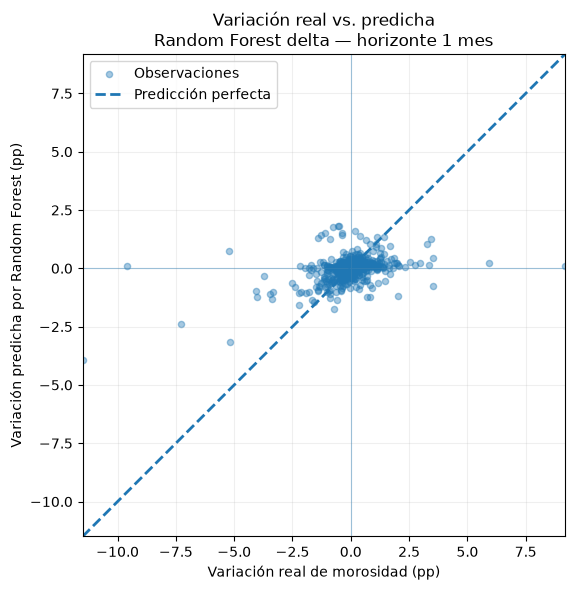

In [21]:
import matplotlib.pyplot as plt

# ======================================================
# E2.3 - CAMBIOS REALES VS CAMBIOS PREDICHOS
# ======================================================

x = h1_e23["delta_real_pp"]
y = h1_e23["delta_pred_rf_pp"]

lim_inf = min(x.min(), y.min())
lim_sup = max(x.max(), y.max())

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    x,
    y,
    alpha=0.4,
    s=20,
    label="Observaciones",
)

# Recta de predicción perfecta.
ax.plot(
    [lim_inf, lim_sup],
    [lim_inf, lim_sup],
    linestyle="--",
    linewidth=2,
    label="Predicción perfecta",
)

ax.axhline(0, linewidth=0.8, alpha=0.4)
ax.axvline(0, linewidth=0.8, alpha=0.4)

ax.set_xlabel("Variación real de morosidad (pp)")
ax.set_ylabel("Variación predicha por Random Forest (pp)")

ax.set_title(
    "Variación real vs. predicha\n"
    "Random Forest delta — horizonte 1 mes"
)

ax.set_xlim(lim_inf, lim_sup)
ax.set_ylim(lim_inf, lim_sup)

ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Los resultados sugieren que Random Forest entrenado sobre variaciones futuras de morosidad presenta ventajas predictivas frente a la persistencia estacional para el horizonte de un mes, particularmente en observaciones con cambios extremos. Sin embargo, esta mejora no se mantiene para todos los horizontes ni para todos los tipos de movimiento. El modelo muestra un desempeño relativamente favorable durante aumentos de morosidad, pero presenta mayores errores durante disminuciones, especialmente a dos y tres meses. El análisis individual identifica además dificultades para anticipar cambios extraordinarios y cierta concentración de errores en instituciones específicas. En consecuencia, resulta necesario complementar las métricas promedio con análisis de sesgo, detección de deterioros y estabilidad temporal antes de seleccionar una estrategia definitiva.

## Sesgo y anticipacion de variaciones

In [22]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# E2.4.1 - PREPARACIÓN Y ANÁLISIS DE SESGO
# ======================================================

columnas_e24 = [
    "horizonte",
    "fold",
    "banco",
    "fecha",
    "Persistencia",
    "y_real",
    "RandomForest_delta",
    "Persistencia_estacional",
]

datos_e24 = predicciones_completas[columnas_e24].copy()

assert len(datos_e24) == 3795
assert not datos_e24.duplicated(
    ["horizonte", "fold", "banco", "fecha"]
).any()

# ======================================================
# 1. VARIACIONES REALES Y PREDICHAS
# ======================================================

datos_e24["delta_real"] = (
    datos_e24["y_real"]
    - datos_e24["Persistencia"]
)

datos_e24["delta_rf"] = (
    datos_e24["RandomForest_delta"]
    - datos_e24["Persistencia"]
)

datos_e24["delta_estacional"] = (
    datos_e24["Persistencia_estacional"]
    - datos_e24["Persistencia"]
)

# ======================================================
# 2. ERRORES CON SIGNO
# ======================================================

datos_e24["error_rf"] = (
    datos_e24["y_real"]
    - datos_e24["RandomForest_delta"]
)

datos_e24["error_estacional"] = (
    datos_e24["y_real"]
    - datos_e24["Persistencia_estacional"]
)

datos_e24["abs_error_rf"] = datos_e24["error_rf"].abs()
datos_e24["abs_error_estacional"] = (
    datos_e24["error_estacional"].abs()
)

assert np.isfinite(
    datos_e24[
        [
            "delta_real",
            "delta_rf",
            "delta_estacional",
            "error_rf",
            "error_estacional",
        ]
    ].to_numpy(dtype=float)
).all()

# ======================================================
# 3. SESGO GLOBAL POR HORIZONTE
# ======================================================

sesgo_global = (
    datos_e24
    .groupby("horizonte")
    .agg(
        observaciones=("error_rf", "size"),
        cambio_real_medio=("delta_real", "mean"),
        cambio_rf_medio=("delta_rf", "mean"),
        cambio_estacional_medio=("delta_estacional", "mean"),
        sesgo_rf=("error_rf", "mean"),
        sesgo_estacional=("error_estacional", "mean"),
        mae_rf=("abs_error_rf", "mean"),
        mae_estacional=("abs_error_estacional", "mean"),
    )
    .reset_index()
)

print("=== SESGO GLOBAL POR HORIZONTE ===")
display(sesgo_global.round(4))

# ======================================================
# 4. SESGO SEGÚN DIRECCIÓN REAL DEL CAMBIO
# ======================================================

UMBRAL_DIRECCION = 0.10

datos_e24["direccion_real"] = np.select(
    [
        datos_e24["delta_real"] > UMBRAL_DIRECCION,
        datos_e24["delta_real"] < -UMBRAL_DIRECCION,
    ],
    [
        "Aumento",
        "Disminucion",
    ],
    default="Estabilidad",
)

sesgo_direccion = (
    datos_e24
    .groupby(["horizonte", "direccion_real"])
    .agg(
        observaciones=("error_rf", "size"),
        cambio_real_medio=("delta_real", "mean"),
        cambio_rf_medio=("delta_rf", "mean"),
        sesgo_rf=("error_rf", "mean"),
        sesgo_estacional=("error_estacional", "mean"),
        mae_rf=("abs_error_rf", "mean"),
        mae_estacional=("abs_error_estacional", "mean"),
    )
    .reset_index()
)

print("\n=== SESGO SEGÚN LA DIRECCIÓN DEL CAMBIO ===")
display(sesgo_direccion.round(4))

print("\nANÁLISIS DE SESGO: COMPLETADO")

=== SESGO GLOBAL POR HORIZONTE ===


,horizonte,observaciones,cambio_real_medio,cambio_rf_medio,cambio_estacional_medio,sesgo_rf,sesgo_estacional,mae_rf,mae_estacional
0,1,1288,-0.0023,0.0239,-0.0075,-0.0262,0.0052,0.3606,0.3693
1,2,1265,0.0014,0.0470,-0.0118,-0.0456,0.0132,0.5270,0.5070
2,3,1242,0.0068,0.1355,-0.0162,-0.1287,0.0230,0.6492,0.6121



=== SESGO SEGÚN LA DIRECCIÓN DEL CAMBIO ===


,horizonte,direccion_real,observaciones,cambio_real_medio,cambio_rf_medio,sesgo_rf,sesgo_estacional,mae_rf,mae_estacional
0,1,Aumento,425,0.5428,0.1078,0.4350,0.4919,0.4717,0.5067
1,1,Disminucion,368,-0.6446,-0.1112,-0.5335,-0.5447,0.5840,0.5828
2,1,Estabilidad,495,0.0072,0.0523,-0.0451,-0.0038,0.0991,0.0927
3,2,Aumento,474,0.6736,0.0946,0.5791,0.6190,0.6197,0.6480
4,2,Disminucion,423,-0.7527,0.0086,-0.7613,-0.6579,0.8077,0.6927
5,2,Estabilidad,368,0.0024,0.0298,-0.0275,0.0044,0.0849,0.1119
6,3,Aumento,497,0.7675,0.1736,0.5939,0.7483,0.6664,0.7638
7,3,Disminucion,440,-0.8509,0.1542,-1.0051,-0.7917,1.0138,0.8025
8,3,Estabilidad,305,0.0046,0.0463,-0.0417,0.0166,0.0953,0.0903



ANÁLISIS DE SESGO: COMPLETADO


### Prediccion de la direccion correcta de morosidad

In [23]:
from sklearn.metrics import confusion_matrix, recall_score

# ======================================================
# E2.4.2 - CAPACIDAD PARA PREDECIR LA DIRECCIÓN
# ======================================================

CLASES = ["Disminucion", "Estabilidad", "Aumento"]


def clasificar_variacion(delta, umbral=0.10):
    """Clasifica el cambio de morosidad en tres categorías."""

    return pd.Series(
        np.select(
            [
                delta > umbral,
                delta < -umbral,
            ],
            [
                "Aumento",
                "Disminucion",
            ],
            default="Estabilidad",
        ),
        index=delta.index,
    )


# ======================================================
# 1. CLASIFICAR VARIACIONES
# ======================================================

datos_e24["clase_real"] = clasificar_variacion(
    datos_e24["delta_real"],
    UMBRAL_DIRECCION,
)

datos_e24["clase_rf"] = clasificar_variacion(
    datos_e24["delta_rf"],
    UMBRAL_DIRECCION,
)

datos_e24["clase_estacional"] = clasificar_variacion(
    datos_e24["delta_estacional"],
    UMBRAL_DIRECCION,
)

# ======================================================
# 2. CALCULAR MÉTRICAS
# ======================================================

resultados_direccion = []

for h, grupo in datos_e24.groupby("horizonte"):

    y_real = grupo["clase_real"]

    for nombre, columna in [
        ("RandomForest_delta", "clase_rf"),
        ("Persistencia_estacional", "clase_estacional"),
    ]:

        y_pred = grupo[columna]

        exactitud = (y_real == y_pred).mean()

        recalls = recall_score(
            y_real,
            y_pred,
            labels=CLASES,
            average=None,
            zero_division=0,
        )

        resultados_direccion.append({
            "horizonte": h,
            "estrategia": nombre,
            "observaciones": len(grupo),
            "exactitud": exactitud,
            "recall_disminucion": recalls[0],
            "recall_estabilidad": recalls[1],
            "recall_aumento": recalls[2],
            "recall_macro": recalls.mean(),
        })

direccion_resultados = pd.DataFrame(resultados_direccion)

print("=== CAPACIDAD DIRECCIONAL ===")

display(direccion_resultados.round(4))

# ======================================================
# 3. MATRIZ DE CONFUSIÓN PARA HORIZONTE 1
# ======================================================

datos_h1 = datos_e24.loc[
    datos_e24["horizonte"] == 1
]

for nombre, columna in [
    ("Random Forest delta", "clase_rf"),
    ("Persistencia estacional", "clase_estacional"),
]:

    matriz = confusion_matrix(
        datos_h1["clase_real"],
        datos_h1[columna],
        labels=CLASES,
    )

    matriz_df = pd.DataFrame(
        matriz,
        index=[f"Real: {c}" for c in CLASES],
        columns=[f"Predicho: {c}" for c in CLASES],
    )

    print(f"\n=== MATRIZ DE CONFUSIÓN: {nombre} ===")
    display(matriz_df)

assert len(direccion_resultados) == 6

print("\nEVALUACIÓN DIRECCIONAL: COMPLETADA")

=== CAPACIDAD DIRECCIONAL ===


,horizonte,estrategia,observaciones,exactitud,recall_disminucion,recall_estabilidad,recall_aumento,recall_macro
0,1,RandomForest_delta,1288,0.5148,0.3668,0.6970,0.4306,0.4981
1,1,Persistencia_estacional,1288,0.4612,0.3668,0.7232,0.2376,0.4426
2,2,RandomForest_delta,1265,0.4332,0.2648,0.8451,0.2637,0.4579
3,2,Persistencia_estacional,1265,0.3905,0.3664,0.7120,0.1624,0.4136
4,3,RandomForest_delta,1242,0.3865,0.2250,0.8000,0.2757,0.4336
5,3,Persistencia_estacional,1242,0.3309,0.2295,0.8066,0.1288,0.3883



=== MATRIZ DE CONFUSIÓN: Random Forest delta ===


,Predicho: Disminucion,Predicho: Estabilidad,Predicho: Aumento
Real: Disminucion,135,143,90
Real: Estabilidad,45,345,105
Real: Aumento,45,197,183



=== MATRIZ DE CONFUSIÓN: Persistencia estacional ===


,Predicho: Disminucion,Predicho: Estabilidad,Predicho: Aumento
Real: Disminucion,135,198,35
Real: Estabilidad,66,358,71
Real: Aumento,38,286,101



EVALUACIÓN DIRECCIONAL: COMPLETADA


### Anticipacion de aumentos importantes

In [24]:
# ======================================================
# E2.4.3 - DETECCIÓN DE AUMENTOS IMPORTANTES
# ======================================================

UMBRALES_ALERTA = [0.50, 1.00]


def evaluar_alertas(delta_real, delta_pred, umbral):
    """Calcula métricas binarias para aumentos de morosidad."""

    real = np.asarray(delta_real) >= umbral
    pred = np.asarray(delta_pred) >= umbral

    tp = int(np.sum(real & pred))
    tn = int(np.sum(~real & ~pred))
    fp = int(np.sum(~real & pred))
    fn = int(np.sum(real & ~pred))

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    f1 = (
        2 * tp / (2 * tp + fp + fn)
        if (2 * tp + fp + fn) > 0
        else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    return {
        "eventos_reales": tp + fn,
        "alertas_emitidas": tp + fp,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fpr": fpr,
    }


# ======================================================
# 1. EVALUAR LOS DOS UMBRALES
# ======================================================

resultados_alertas = []

for h, grupo in datos_e24.groupby("horizonte"):

    for umbral in UMBRALES_ALERTA:

        for nombre, columna in [
            ("RandomForest_delta", "delta_rf"),
            ("Persistencia_estacional", "delta_estacional"),
        ]:

            metricas = evaluar_alertas(
                grupo["delta_real"],
                grupo[columna],
                umbral,
            )

            resultados_alertas.append({
                "horizonte": h,
                "umbral_pp": umbral,
                "estrategia": nombre,
                **metricas,
            })

alertas_e24 = pd.DataFrame(resultados_alertas)

print("=== DETECCIÓN DE AUMENTOS IMPORTANTES ===")

columnas_mostrar = [
    "horizonte",
    "umbral_pp",
    "estrategia",
    "eventos_reales",
    "alertas_emitidas",
    "TP",
    "FP",
    "FN",
    "precision",
    "recall",
    "f1",
    "fpr",
]

display(alertas_e24[columnas_mostrar].round(4))

assert len(alertas_e24) == 12

print("\nANÁLISIS DE ALERTAS: COMPLETADO")

=== DETECCIÓN DE AUMENTOS IMPORTANTES ===


,horizonte,umbral_pp,estrategia,eventos_reales,alertas_emitidas,TP,FP,FN,precision,recall,f1,fpr
0,1,0.5,RandomForest_delta,134,39,14,25,120,0.3590,0.1045,0.1618,0.0217
1,1,0.5,Persistencia_estacional,134,0,0,0,134,NaN,0.0000,0.0000,0.0000
2,1,1.0,RandomForest_delta,58,18,5,13,53,0.2778,0.0862,0.1316,0.0106
3,1,1.0,Persistencia_estacional,58,0,0,0,58,NaN,0.0000,0.0000,0.0000
4,2,0.5,RandomForest_delta,187,79,35,44,152,0.4430,0.1872,0.2632,0.0408
5,2,0.5,Persistencia_estacional,187,92,39,53,148,0.4239,0.2086,0.2796,0.0492
6,2,1.0,RandomForest_delta,91,36,14,22,77,0.3889,0.1538,0.2205,0.0187
7,2,1.0,Persistencia_estacional,91,0,0,0,91,NaN,0.0000,0.0000,0.0000
8,3,0.5,RandomForest_delta,207,87,42,45,165,0.4828,0.2029,0.2857,0.0435
9,3,0.5,Persistencia_estacional,207,0,0,0,207,NaN,0.0000,0.0000,0.0000



ANÁLISIS DE ALERTAS: COMPLETADO


### Random Forest suaviza las variaciones?

In [25]:
# ======================================================
# E2.4.4 - DISTRIBUCIÓN DE CAMBIOS REALES Y PREDICHOS
# ======================================================

resultados_distribucion = []

for h, grupo in datos_e24.groupby("horizonte"):

    for nombre, columna in [
        ("Real", "delta_real"),
        ("RandomForest_delta", "delta_rf"),
        ("Persistencia_estacional", "delta_estacional"),
    ]:

        valores = grupo[columna]

        resultados_distribucion.append({
            "horizonte": h,
            "serie": nombre,
            "media": valores.mean(),
            "std": valores.std(ddof=0),
            "p01": valores.quantile(0.01),
            "p05": valores.quantile(0.05),
            "mediana": valores.median(),
            "p95": valores.quantile(0.95),
            "p99": valores.quantile(0.99),
            "minimo": valores.min(),
            "maximo": valores.max(),
        })

distribucion_e24 = pd.DataFrame(resultados_distribucion)

print("=== DISTRIBUCIÓN DE VARIACIONES ===")

display(distribucion_e24.round(4))


# ======================================================
# 2. MEDIR LA DISPERSIÓN RELATIVA Y CORRELACIÓN
# ======================================================

diagnostico_dispersion = []

for h, grupo in datos_e24.groupby("horizonte"):

    std_real = grupo["delta_real"].std(ddof=0)
    std_rf = grupo["delta_rf"].std(ddof=0)
    std_est = grupo["delta_estacional"].std(ddof=0)

    diagnostico_dispersion.append({
        "horizonte": h,
        "std_real": std_real,
        "std_rf": std_rf,
        "ratio_std_rf": (
            std_rf / std_real if std_real > 0 else np.nan
        ),
        "ratio_std_estacional": (
            std_est / std_real if std_real > 0 else np.nan
        ),
        "correlacion_rf": grupo["delta_real"].corr(
            grupo["delta_rf"]
        ),
        "correlacion_estacional": grupo["delta_real"].corr(
            grupo["delta_estacional"]
        ),
    })

diagnostico_dispersion = pd.DataFrame(
    diagnostico_dispersion
)

print("\n=== DISPERSIÓN Y CORRELACIÓN ===")
display(diagnostico_dispersion.round(4))

=== DISTRIBUCIÓN DE VARIACIONES ===


,horizonte,serie,media,std,p01,p05,mediana,p95,p99,minimo,maximo
0,1,Real,-0.0023,0.8525,-2.2516,-0.9155,0.0112,0.9354,2.0180,-11.4970,9.1747
1,1,RandomForest_delta,0.0239,0.3526,-1.1793,-0.5426,0.0720,0.3582,1.2593,-3.9253,1.8147
2,1,Persistencia_estacional,-0.0075,0.1758,-0.4899,-0.4267,0.0255,0.3443,0.3531,-0.4899,0.3531
3,2,Real,0.0014,1.0280,-3.2583,-1.1473,0.0034,1.3085,2.9859,-11.2533,9.3472
4,2,RandomForest_delta,0.0470,0.5138,-1.2209,-0.5589,0.0024,0.6034,2.0744,-3.8252,4.3372
5,2,Persistencia_estacional,-0.0118,0.2099,-0.4920,-0.4491,-0.0420,0.5537,0.5848,-0.4920,0.5848
6,3,Real,0.0068,1.2090,-3.6936,-1.4660,0.0112,1.6210,3.3002,-11.8779,8.3234
7,3,RandomForest_delta,0.1355,0.7702,-0.9708,-0.3699,0.0328,0.8328,4.0116,-1.9730,7.5692
8,3,Persistencia_estacional,-0.0162,0.1473,-0.3778,-0.3457,-0.0112,0.3727,0.3859,-0.3778,0.3859



=== DISPERSIÓN Y CORRELACIÓN ===


,horizonte,std_real,std_rf,ratio_std_rf,ratio_std_estacional,correlacion_rf,correlacion_estacional
0,1,0.8525,0.3526,0.4136,0.2062,0.4358,0.2736
1,2,1.0280,0.5138,0.4998,0.2042,0.1595,0.2550
2,3,1.2090,0.7702,0.6370,0.1218,0.0430,0.1823


visualizacion

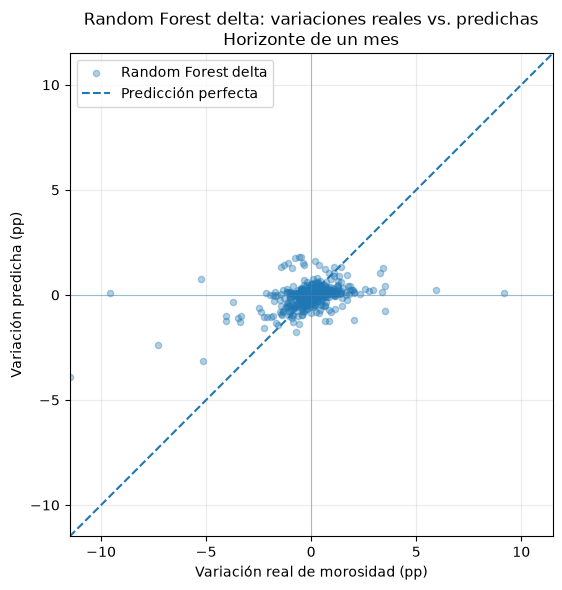

In [26]:
import matplotlib.pyplot as plt

# ======================================================
# E2.4.5 - DISPERSIÓN DE VARIACIONES A UN MES
# ======================================================

h1_e24 = datos_e24.loc[
    datos_e24["horizonte"] == 1
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    h1_e24["delta_real"],
    h1_e24["delta_rf"],
    alpha=0.35,
    s=20,
    label="Random Forest delta",
)

limite = max(
    h1_e24["delta_real"].abs().max(),
    h1_e24["delta_rf"].abs().max(),
)

ax.plot(
    [-limite, limite],
    [-limite, limite],
    "--",
    linewidth=1.5,
    label="Predicción perfecta",
)

ax.axhline(0, linewidth=0.8, alpha=0.4)
ax.axvline(0, linewidth=0.8, alpha=0.4)

ax.set_xlabel("Variación real de morosidad (pp)")
ax.set_ylabel("Variación predicha (pp)")

ax.set_title(
    "Random Forest delta: variaciones reales vs. predichas\n"
    "Horizonte de un mes"
)

ax.set_xlim(-limite, limite)
ax.set_ylim(-limite, limite)
ax.set_aspect("equal", adjustable="box")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### inffluencia de bnaco capital

In [27]:
# ======================================================
# E2.4.6 - CONTRIBUCIÓN DE BANCOS AL ERROR DE 2021
# ======================================================

datos_2021 = datos_e24.loc[
    (datos_e24["horizonte"] == 1)
    & (datos_e24["fold"] == 2021)
].copy()

datos_2021["deterioro_rf_pp"] = (
    datos_2021["abs_error_rf"]
    - datos_2021["abs_error_estacional"]
)

# ======================================================
# 1. CONTRIBUCIÓN POR BANCO
# ======================================================

contribucion_bancos = (
    datos_2021
    .groupby("banco")
    .agg(
        observaciones=("deterioro_rf_pp", "size"),
        deterioro_medio_pp=("deterioro_rf_pp", "mean"),
        deterioro_acumulado_pp=("deterioro_rf_pp", "sum"),
    )
    .sort_values(
        "deterioro_acumulado_pp",
        ascending=False,
    )
)

print("=== BANCOS QUE MÁS EMPEORARON EL MAE EN 2021 ===")

display(contribucion_bancos.head(10).round(4))


# ======================================================
# 2. MAE ORIGINAL DEL AÑO
# ======================================================

mae_rf_original = datos_2021["abs_error_rf"].mean()
mae_est_original = datos_2021[
    "abs_error_estacional"
].mean()

# ======================================================
# 3. MAE DIAGNÓSTICO SIN BP CAPITAL
# ======================================================

sin_capital = datos_2021.loc[
    datos_2021["banco"] != "BP CAPITAL"
]

mae_rf_sin_capital = sin_capital["abs_error_rf"].mean()

mae_est_sin_capital = sin_capital[
    "abs_error_estacional"
].mean()

comparacion_capital = pd.DataFrame([
    {
        "escenario": "Todos los bancos",
        "observaciones": len(datos_2021),
        "mae_rf": mae_rf_original,
        "mae_estacional": mae_est_original,
        "diferencia_rf_menos_baseline": (
            mae_rf_original - mae_est_original
        ),
    },
    {
        "escenario": "Sin BP CAPITAL",
        "observaciones": len(sin_capital),
        "mae_rf": mae_rf_sin_capital,
        "mae_estacional": mae_est_sin_capital,
        "diferencia_rf_menos_baseline": (
            mae_rf_sin_capital - mae_est_sin_capital
        ),
    },
])

print("\n=== SENSIBILIDAD DEL RESULTADO DE 2021 ===")
display(comparacion_capital.round(4))

print(
    "\nDeterioro acumulado total:",
    round(datos_2021["deterioro_rf_pp"].sum(), 4),
    "pp",
)

print(
    "Deterioro acumulado BP CAPITAL:",
    round(
        datos_2021.loc[
            datos_2021["banco"] == "BP CAPITAL",
            "deterioro_rf_pp",
        ].sum(),
        4,
    ),
    "pp",
)

=== BANCOS QUE MÁS EMPEORARON EL MAE EN 2021 ===


,observaciones,deterioro_medio_pp,deterioro_acumulado_pp
banco,,,
BP CAPITAL,12,1.3049,15.6589
BP LITORAL,12,0.1336,1.6037
BANCO ATLANTIDA S.A.,12,0.1048,1.2578
BP DELBANK,12,0.1036,1.2433
BP SOLIDARIO,12,0.0623,0.7480
BP VISIONFUND ECUADOR S.A.,12,0.0598,0.7178
"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODESARROLLO",12,0.0423,0.5077
BP LOJA,12,0.0325,0.3897
BP CITIBANK,12,0.0160,0.1919



=== SENSIBILIDAD DEL RESULTADO DE 2021 ===


,escenario,observaciones,mae_rf,mae_estacional,diferencia_rf_menos_baseline
0,Todos los bancos,276,0.3764,0.3153,0.0612
1,Sin BP CAPITAL,264,0.3014,0.2967,0.0046



Deterioro acumulado total: 16.8802 pp
Deterioro acumulado BP CAPITAL: 15.6589 pp


## Auditoria de Variables Predictoras

### calidad de variables

In [28]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# EXPERIMENTO E3.1
# AUDITORÍA DE CARACTERÍSTICAS
# ======================================================

configuracion = datasets[1]

datos = configuracion["desarrollo"]

predictoras = list(configuracion["predictoras"])
numericas = list(configuracion["numericas"])

print("=== CONFIGURACIÓN ACTUAL ===")

print("Predictores totales:", len(predictoras))
print("Predictores numéricos:", len(numericas))
print("Observaciones desarrollo:", len(datos))

assert len(predictoras) == 22
assert len(numericas) == 21
assert "banco" in predictoras
assert len(set(predictoras)) == len(predictoras)

# ======================================================
# 1. INVENTARIO DE VARIABLES
# ======================================================

inventario = []

for columna in predictoras:

    serie = datos[columna]

    if columna in numericas:
        valores = pd.to_numeric(
            serie, errors="coerce"
        )

        infinitos = int(
            np.isinf(
                valores.to_numpy(dtype=float)
            ).sum()
        )
    else:
        infinitos = 0

    inventario.append({
        "variable": columna,
        "tipo": str(serie.dtype),
        "categoria": (
            "Numerica"
            if columna in numericas
            else "Categorica"
        ),
        "faltantes": int(serie.isna().sum()),
        "faltantes_pct": serie.isna().mean() * 100,
        "infinitos": infinitos,
        "valores_unicos": serie.nunique(dropna=True),
    })

inventario_features = pd.DataFrame(inventario)

print("\n=== INVENTARIO DE PREDICTORES ===")

display(inventario_features.round(2))


# ======================================================
# 2. IDENTIFICAR VARIABLES CON PROBLEMAS
# ======================================================

problemas_features = inventario_features.loc[
    (inventario_features["faltantes"] > 0)
    | (inventario_features["infinitos"] > 0)
    | (inventario_features["valores_unicos"] <= 1)
]

print("\n=== VARIABLES QUE REQUIEREN REVISIÓN ===")

display(problemas_features.round(2))


# ======================================================
# 3. COMPROBAR AUSENCIA DE TARGETS
# ======================================================

sospechosas = [
    columna
    for columna in predictoras
    if (
        columna.startswith("target_")
        or columna.startswith("fecha_objetivo")
        or columna in {"fecha_objetivo", "fecha"}
    )
]

assert not sospechosas, (
    f"Posibles variables con fuga de información: {sospechosas}"
)

print("\nAUDITORÍA INICIAL COMPLETADA")

=== CONFIGURACIÓN ACTUAL ===
Predictores totales: 22
Predictores numéricos: 21
Observaciones desarrollo: 5666

=== INVENTARIO DE PREDICTORES ===


,variable,tipo,categoria,faltantes,faltantes_pct,infinitos,valores_unicos
0,morosidad_pp,float64,Numerica,0,0.00,0,5615
1,morosidad_lag_1_pp,float64,Numerica,23,0.41,0,5593
2,morosidad_lag_2_pp,float64,Numerica,45,0.79,0,5570
3,morosidad_lag_3_pp,float64,Numerica,68,1.20,0,5547
4,morosidad_lag_6_pp,float64,Numerica,137,2.42,0,5479
5,morosidad_lag_12_pp,float64,Numerica,275,4.85,0,5346
6,delta_morosidad_1m_pp,float64,Numerica,23,0.41,0,5587
7,delta_morosidad_3m_pp,float64,Numerica,68,1.20,0,5564
8,morosidad_media_3m_pp,float64,Numerica,46,0.81,0,5599
9,morosidad_media_6m_pp,float64,Numerica,115,2.03,0,5537



=== VARIABLES QUE REQUIEREN REVISIÓN ===


,variable,tipo,categoria,faltantes,faltantes_pct,infinitos,valores_unicos
1,morosidad_lag_1_pp,float64,Numerica,23,0.41,0,5593
2,morosidad_lag_2_pp,float64,Numerica,45,0.79,0,5570
3,morosidad_lag_3_pp,float64,Numerica,68,1.20,0,5547
4,morosidad_lag_6_pp,float64,Numerica,137,2.42,0,5479
5,morosidad_lag_12_pp,float64,Numerica,275,4.85,0,5346
6,delta_morosidad_1m_pp,float64,Numerica,23,0.41,0,5587
7,delta_morosidad_3m_pp,float64,Numerica,68,1.20,0,5564
8,morosidad_media_3m_pp,float64,Numerica,46,0.81,0,5599
9,morosidad_media_6m_pp,float64,Numerica,115,2.03,0,5537
10,morosidad_std_3m_pp,float64,Numerica,46,0.81,0,5604



AUDITORÍA INICIAL COMPLETADA


### Importancia de caracteristicas con Random Forest

In [29]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo

# ======================================================
# EXPERIMENTO E3.2
# PERMUTATION IMPORTANCE - RANDOM FOREST DELTA
# ======================================================

HORIZONTE = 1
ANIO_FOLD = 2024

config = datasets[HORIZONTE]
datos = config["desarrollo"]

target = config["target"]
fecha_target = config["fecha_target"]

numericas = config["numericas"]
predictoras = config["predictoras"]


# ======================================================
# 1. RECUPERAR EL FOLD TEMPORAL
# ======================================================

fold = next(
    f for f in folds_cv[HORIZONTE]
    if f["fold"] == ANIO_FOLD
)

train = datos.loc[fold["train_idx"]].copy()
val = datos.loc[fold["val_idx"]].copy()

assert train[fecha_target].max() < val["fecha"].min()

# ======================================================
# 2. PREPARAR LOS PREDICTORES
# ======================================================

X_train = train[predictoras].replace(
    [np.inf, -np.inf], np.nan
)

X_val = val[predictoras].replace(
    [np.inf, -np.inf], np.nan
)

# Objetivo: variación futura de morosidad.
y_train_delta = (
    train[target] - train["morosidad_pp"]
)

y_val_delta = (
    val[target] - val["morosidad_pp"]
)

# ======================================================
# 3. ENTRENAR EL MODELO
# ======================================================

modelo_rf = construir_modelo(
    "RandomForest",
    numericas,
)

modelo_rf.fit(
    X_train,
    y_train_delta,
)

# ======================================================
# 4. VERIFICAR EL ERROR ORIGINAL
# ======================================================

delta_predicha = modelo_rf.predict(X_val)

morosidad_predicha = (
    val["morosidad_pp"].to_numpy()
    + delta_predicha
)

mae_original = mean_absolute_error(
    val[target],
    morosidad_predicha,
)

print(
    f"MAE original, fold {ANIO_FOLD}: "
    f"{mae_original:.6f} pp"
)

# El MAE debe coincidir con el experimento E1.2.
assert round(mae_original, 4) == 0.4005


# ======================================================
# 5. CALCULAR IMPORTANCIA POR PERMUTACIÓN
# ======================================================

importancias = permutation_importance(
    estimator=modelo_rf,
    X=X_val,
    y=y_val_delta,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)

# ======================================================
# 6. CONSTRUIR TABLA DE IMPORTANCIAS
# ======================================================

importancia_features = pd.DataFrame({
    "variable": X_val.columns,
    "importancia_media_pp": importancias.importances_mean,
    "importancia_std": importancias.importances_std,
})

importancia_features = (
    importancia_features
    .sort_values(
        "importancia_media_pp",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\n=== IMPORTANCIA DE CARACTERÍSTICAS ===")

display(importancia_features.round(5))

print("\nEXPERIMENTO DE IMPORTANCIA COMPLETADO")

MAE original, fold 2024: 0.400483 pp

=== IMPORTANCIA DE CARACTERÍSTICAS ===


,variable,importancia_media_pp,importancia_std
0,mes_cos_t1,0.08820,0.01296
1,delta_morosidad_1m_pp,0.03876,0.00813
2,morosidad_std_3m_pp,0.01809,0.00551
3,morosidad_pp,0.01354,0.00387
4,morosidad_std_6m_pp,0.01022,0.00337
5,morosidad_lag_6_pp,0.00769,0.00284
6,delta_morosidad_3m_pp,0.00753,0.00257
7,morosidad_lag_2_pp,0.00664,0.00219
8,roa,0.00655,0.00139
9,banco,0.00515,0.00134



EXPERIMENTO DE IMPORTANCIA COMPLETADO


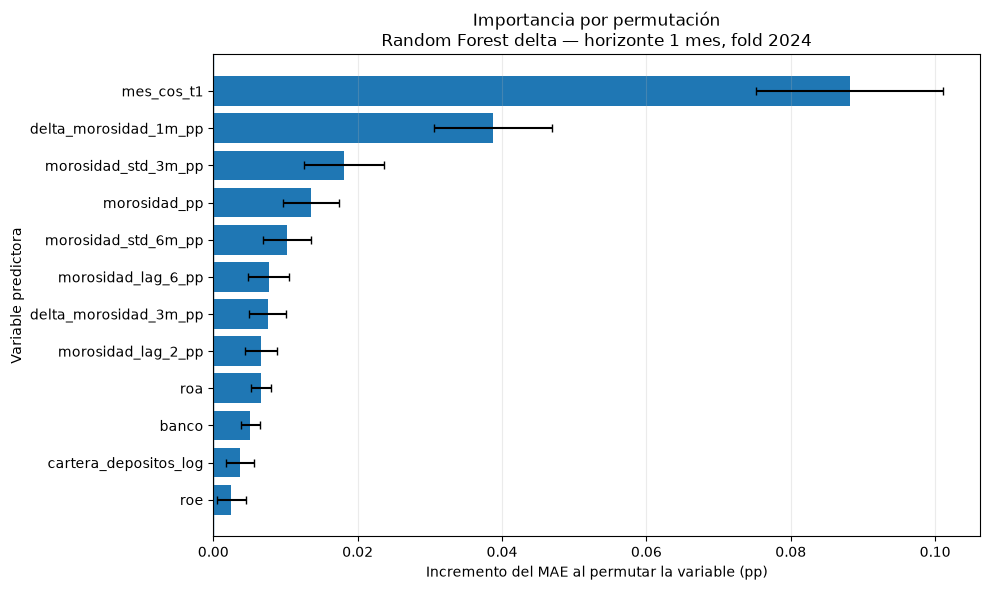

In [30]:
import matplotlib.pyplot as plt

# ======================================================
# E3.2 - VISUALIZAR LAS 12 VARIABLES PRINCIPALES
# ======================================================

top_features = (
    importancia_features
    .head(12)
    .sort_values("importancia_media_pp")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_features["variable"],
    top_features["importancia_media_pp"],
    xerr=top_features["importancia_std"],
    capsize=3,
)

ax.axvline(0, linewidth=1)

ax.set_title(
    "Importancia por permutación\n"
    "Random Forest delta — horizonte 1 mes, fold 2024"
)

ax.set_xlabel(
    "Incremento del MAE al permutar la variable (pp)"
)

ax.set_ylabel("Variable predictora")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## Ablacion de familias de caracteristicas

### Definir grupos de variables

In [31]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# E3.3 - DEFINICIÓN DE GRUPOS DE CARACTERÍSTICAS
# ======================================================

HORIZONTE_ABLACION = 1

config = datasets[HORIZONTE_ABLACION]

predictoras_originales = list(config["predictoras"])
numericas_originales = list(config["numericas"])

grupos_features = {
    "nivel_rezagos": [
        "morosidad_pp",
        "morosidad_lag_1_pp",
        "morosidad_lag_2_pp",
        "morosidad_lag_3_pp",
        "morosidad_lag_6_pp",
        "morosidad_lag_12_pp",
    ],
    "dinamica": [
        "delta_morosidad_1m_pp",
        "delta_morosidad_3m_pp",
        "morosidad_media_3m_pp",
        "morosidad_media_6m_pp",
        "morosidad_std_3m_pp",
        "morosidad_std_6m_pp",
    ],
    "financieras": [
        "solvencia",
        "roa",
        "roe",
        "liquidez_log",
        "cartera_depositos_log",
        "crecimiento_log_cartera_1m",
        "crecimiento_log_cartera_3m",
    ],
    "estacionalidad": [
        "mes_sin_t1",
        "mes_cos_t1",
    ],
    "institucion": ["banco"],
}

# ======================================================
# 1. VALIDAR QUE LOS GRUPOS SEAN EXCLUSIVOS Y COMPLETOS
# ======================================================

todas = [
    variable
    for columnas in grupos_features.values()
    for variable in columnas
]

assert len(todas) == len(set(todas))
assert set(todas) == set(predictoras_originales)
assert len(todas) == 22

print("=== FAMILIAS DE VARIABLES ===")

display(pd.DataFrame([
    {
        "grupo": grupo,
        "cantidad": len(columnas),
        "variables": ", ".join(columnas),
    }
    for grupo, columnas in grupos_features.items()
]))

# ======================================================
# 2. CONSTRUIR LOS ESCENARIOS DE ABLACIÓN
# ======================================================

escenarios_ablacion = {
    "Completo": predictoras_originales,
}

for grupo in [
    "nivel_rezagos",
    "dinamica",
    "financieras",
    "estacionalidad",
]:
    eliminar = set(grupos_features[grupo])

    escenarios_ablacion[f"Sin_{grupo}"] = [
        variable
        for variable in predictoras_originales
        if variable not in eliminar
    ]

# ======================================================
# 3. VALIDAR CADA ESCENARIO
# ======================================================

for escenario, columnas in escenarios_ablacion.items():
    assert "banco" in columnas
    assert set(columnas).issubset(predictoras_originales)
    assert len(columnas) == len(set(columnas))

print("\n=== ESCENARIOS EXPERIMENTALES ===")

display(pd.DataFrame([
    {
        "escenario": nombre,
        "predictores": len(columnas),
        "numericas": len(columnas) - 1,
    }
    for nombre, columnas in escenarios_ablacion.items()
]))

assert len(escenarios_ablacion) == 5

print("\nDiseño experimental validado.")

=== FAMILIAS DE VARIABLES ===


,grupo,cantidad,variables
0,nivel_rezagos,6,"morosidad_pp, morosidad_lag_1_pp, morosidad_la..."
1,dinamica,6,"delta_morosidad_1m_pp, delta_morosidad_3m_pp, ..."
2,financieras,7,"solvencia, roa, roe, liquidez_log, cartera_dep..."
3,estacionalidad,2,"mes_sin_t1, mes_cos_t1"
4,institucion,1,banco



=== ESCENARIOS EXPERIMENTALES ===


,escenario,predictores,numericas
0,Completo,22,21
1,Sin_nivel_rezagos,16,15
2,Sin_dinamica,16,15
3,Sin_financieras,15,14
4,Sin_estacionalidad,20,19



Diseño experimental validado.


### Validacion cruzada con ablacion

In [32]:
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo

# ======================================================
# E3.3 - ENTRENAMIENTO DE LAS CINCO CONFIGURACIONES
# ======================================================

datos = config["desarrollo"]
target = config["target"]
fecha_target = config["fecha_target"]

resultados_ablacion = []

for escenario, predictoras in escenarios_ablacion.items():

    numericas = [
        variable
        for variable in predictoras
        if variable != "banco"
    ]

    print(f"\n{'=' * 55}")
    print(f"ESCENARIO: {escenario}")
    print(f"PREDICTORES: {len(predictoras)}")
    print(f"{'=' * 55}")

    for fold in folds_cv[HORIZONTE_ABLACION]:

        anio = fold["fold"]

        train = datos.loc[fold["train_idx"]].copy()
        val = datos.loc[fold["val_idx"]].copy()

        # ==========================================
        # 1. VALIDACIÓN TEMPORAL
        # ==========================================

        assert train[fecha_target].max() < val["fecha"].min()

        # ==========================================
        # 2. VARIABLES PREDICTORAS
        # ==========================================

        X_train = train[predictoras].replace(
            [np.inf, -np.inf],
            np.nan,
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf],
            np.nan,
        )

        # ==========================================
        # 3. OBJETIVO DELTA
        # ==========================================

        y_train_delta = (
            train[target] - train["morosidad_pp"]
        )

        y_val_real = val[target].to_numpy(dtype=float)

        assert y_train_delta.notna().all()
        assert np.isfinite(y_val_real).all()

        # ==========================================
        # 4. MODELO NUEVO PARA CADA FOLD
        # ==========================================

        modelo = construir_modelo(
            "RandomForest",
            numericas,
        )

        modelo.fit(
            X_train,
            y_train_delta,
        )

        # ==========================================
        # 5. RECONSTRUCCIÓN DEL NIVEL FUTURO
        # ==========================================

        delta_predicha = modelo.predict(X_val)

        morosidad_predicha = (
            val["morosidad_pp"].to_numpy(dtype=float)
            + delta_predicha
        )

        mae = mean_absolute_error(
            y_val_real,
            morosidad_predicha,
        )

        # ==========================================
        # 6. REGISTRAR EVALUACIÓN
        # ==========================================

        resultados_ablacion.append({
            "horizonte": HORIZONTE_ABLACION,
            "escenario": escenario,
            "fold": anio,
            "observaciones": len(val),
            "n_predictores": len(predictoras),
            "mae_pp": mae,
        })

        print(
            f"Fold {anio} | MAE: {mae:.4f} pp",
            flush=True,
        )


# ======================================================
# 7. RESULTADOS
# ======================================================

detalle_ablacion = pd.DataFrame(
    resultados_ablacion
)

assert len(detalle_ablacion) == 25

assert not detalle_ablacion.duplicated(
    ["horizonte", "escenario", "fold"]
).any()

# ======================================================
# 8. REPRODUCIR EL EXPERIMENTO ORIGINAL
# ======================================================

referencia_rf = (
    detalle_rf.loc[
        (detalle_rf["horizonte"] == 1)
        & (detalle_rf["estrategia"] == "RandomForest_delta"),
        ["fold", "mae_pp"],
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

completo_actual = (
    detalle_ablacion.loc[
        detalle_ablacion["escenario"] == "Completo",
        ["fold", "mae_pp"],
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

assert referencia_rf["fold"].equals(
    completo_actual["fold"]
)

np.testing.assert_allclose(
    completo_actual["mae_pp"].to_numpy(),
    referencia_rf["mae_pp"].to_numpy(),
    rtol=0,
    atol=1e-9,
)

print("\n25 ENTRENAMIENTOS COMPLETADOS")
print("MODELO COMPLETO: REPRODUCCIÓN VALIDADA")


ESCENARIO: Completo
PREDICTORES: 22
Fold 2021 | MAE: 0.3764 pp
Fold 2022 | MAE: 0.3817 pp
Fold 2023 | MAE: 0.3624 pp
Fold 2024 | MAE: 0.4005 pp
Fold 2025 | MAE: 0.2426 pp

ESCENARIO: Sin_nivel_rezagos
PREDICTORES: 16
Fold 2021 | MAE: 0.3748 pp
Fold 2022 | MAE: 0.3784 pp
Fold 2023 | MAE: 0.3599 pp
Fold 2024 | MAE: 0.4078 pp
Fold 2025 | MAE: 0.2528 pp

ESCENARIO: Sin_dinamica
PREDICTORES: 16
Fold 2021 | MAE: 0.4146 pp
Fold 2022 | MAE: 0.3849 pp
Fold 2023 | MAE: 0.3831 pp
Fold 2024 | MAE: 0.4311 pp
Fold 2025 | MAE: 0.2455 pp

ESCENARIO: Sin_financieras
PREDICTORES: 15
Fold 2021 | MAE: 0.3258 pp
Fold 2022 | MAE: 0.3913 pp
Fold 2023 | MAE: 0.3731 pp
Fold 2024 | MAE: 0.4145 pp
Fold 2025 | MAE: 0.2404 pp

ESCENARIO: Sin_estacionalidad
PREDICTORES: 20
Fold 2021 | MAE: 0.4004 pp
Fold 2022 | MAE: 0.4087 pp
Fold 2023 | MAE: 0.3986 pp
Fold 2024 | MAE: 0.4393 pp
Fold 2025 | MAE: 0.2341 pp

25 ENTRENAMIENTOS COMPLETADOS
MODELO COMPLETO: REPRODUCCIÓN VALIDADA


### Rendimiento modelos con ablacion

In [33]:
# ======================================================
# E3.3 - COMPARACIÓN DE LOS ESCENARIOS
# ======================================================

resumen_ablacion = (
    detalle_ablacion
    .groupby("escenario")
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count"),
        predictores=("n_predictores", "first"),
    )
    .reset_index()
)

# ======================================================
# 1. REFERENCIA DEL MODELO COMPLETO
# ======================================================

mae_completo = float(
    resumen_ablacion.loc[
        resumen_ablacion["escenario"] == "Completo",
        "mae_medio",
    ].iloc[0]
)

# MAE medio del baseline estacional a un mes.
mae_estacional = float(
    detalle_baselines.loc[
        (detalle_baselines["horizonte"] == 1)
        & (
            detalle_baselines["modelo"]
            == "Persistencia_estacional"
        ),
        "mae_pp",
    ].mean()
)

# ======================================================
# 2. DIFERENCIAS FRENTE AL MODELO COMPLETO
# ======================================================

resumen_ablacion["diferencia_vs_completo_pp"] = (
    resumen_ablacion["mae_medio"] - mae_completo
)

resumen_ablacion["mejora_vs_completo_pct"] = (
    (mae_completo - resumen_ablacion["mae_medio"])
    / mae_completo
    * 100
)

# ======================================================
# 3. DIFERENCIAS FRENTE AL BASELINE
# ======================================================

resumen_ablacion["mejora_vs_estacional_pct"] = (
    (mae_estacional - resumen_ablacion["mae_medio"])
    / mae_estacional
    * 100
)

resumen_ablacion = (
    resumen_ablacion
    .sort_values("mae_medio")
    .reset_index(drop=True)
)

print("=== COMPARACIÓN GENERAL DE ABLACIONES ===")

display(resumen_ablacion.round(4))

print(f"\nMAE modelo completo: {mae_completo:.4f} pp")
print(f"MAE baseline estacional: {mae_estacional:.4f} pp")


# ======================================================
# 4. COMPARACIÓN POR FOLD
# ======================================================

tabla_folds_ablacion = detalle_ablacion.pivot(
    index="fold",
    columns="escenario",
    values="mae_pp",
)

print("\n=== MAE DE CADA ESCENARIO POR FOLD ===")

display(tabla_folds_ablacion.round(4))


# ======================================================
# 5. CONSISTENCIA DE LAS MEJORAS
# ======================================================

consistencia_ablacion = pd.DataFrame([
    {
        "escenario": escenario,
        "folds_mejora_vs_completo": int(
            (
                tabla_folds_ablacion[escenario]
                < tabla_folds_ablacion["Completo"]
            ).sum()
        ),
        "diferencia_media_pp": float(
            (
                tabla_folds_ablacion[escenario]
                - tabla_folds_ablacion["Completo"]
            ).mean()
        ),
    }
    for escenario in escenarios_ablacion
    if escenario != "Completo"
])

print("\n=== CONSISTENCIA TEMPORAL DE LAS ABLACIONES ===")

display(
    consistencia_ablacion
    .sort_values("diferencia_media_pp")
    .round(4)
)

=== COMPARACIÓN GENERAL DE ABLACIONES ===


,escenario,mae_medio,mae_std,folds,predictores,diferencia_vs_completo_pp,mejora_vs_completo_pct,mejora_vs_estacional_pct
0,Sin_financieras,0.3490,0.0689,5,15,-0.0037,1.0451,3.5303
1,Completo,0.3527,0.0630,5,22,0.0000,0.0000,2.5115
2,Sin_nivel_rezagos,0.3547,0.0596,5,16,0.0020,-0.5735,1.9524
3,Sin_dinamica,0.3719,0.0735,5,16,0.0191,-5.4247,-2.7770
4,Sin_estacionalidad,0.3762,0.0811,5,20,0.0235,-6.6657,-3.9868



MAE modelo completo: 0.3527 pp
MAE baseline estacional: 0.3618 pp

=== MAE DE CADA ESCENARIO POR FOLD ===


escenario,Completo,Sin_dinamica,Sin_estacionalidad,Sin_financieras,Sin_nivel_rezagos
fold,,,,,
2021,0.3764,0.4146,0.4004,0.3258,0.3748
2022,0.3817,0.3849,0.4087,0.3913,0.3784
2023,0.3624,0.3831,0.3986,0.3731,0.3599
2024,0.4005,0.4311,0.4393,0.4145,0.4078
2025,0.2426,0.2455,0.2341,0.2404,0.2528



=== CONSISTENCIA TEMPORAL DE LAS ABLACIONES ===


,escenario,folds_mejora_vs_completo,diferencia_media_pp
2,Sin_financieras,2,-0.0037
0,Sin_nivel_rezagos,3,0.0020
1,Sin_dinamica,0,0.0191
3,Sin_estacionalidad,1,0.0235


### visualizacion

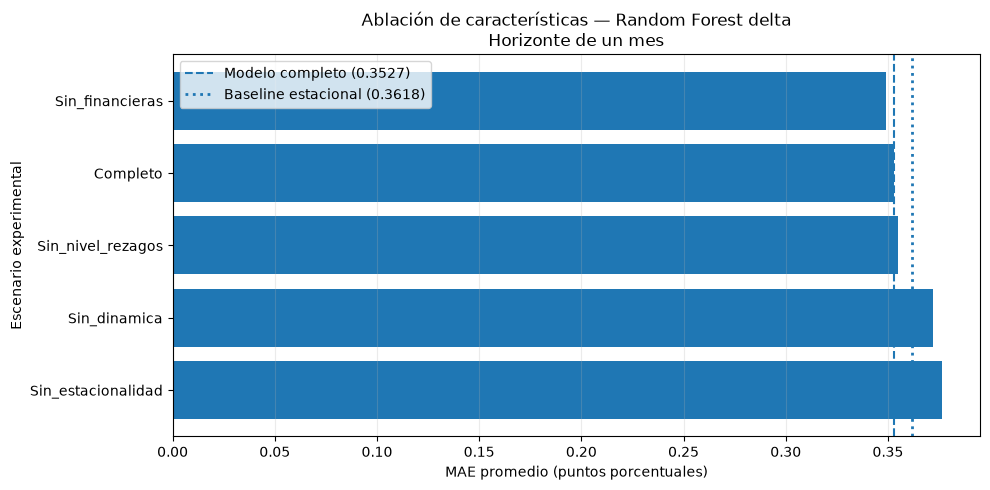

In [34]:
import matplotlib.pyplot as plt

# ======================================================
# E3.3 - VISUALIZACIÓN DE LA ABLACIÓN
# ======================================================

grafico = resumen_ablacion.sort_values(
    "mae_medio",
    ascending=False,
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    grafico["escenario"],
    grafico["mae_medio"],
)

ax.axvline(
    mae_completo,
    linestyle="--",
    linewidth=1.5,
    label=f"Modelo completo ({mae_completo:.4f})",
)

ax.axvline(
    mae_estacional,
    linestyle=":",
    linewidth=2,
    label=f"Baseline estacional ({mae_estacional:.4f})",
)

ax.set_xlabel("MAE promedio (puntos porcentuales)")
ax.set_ylabel("Escenario experimental")

ax.set_title(
    "Ablación de características — Random Forest delta\n"
    "Horizonte de un mes"
)

ax.grid(axis="x", alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

## Contribucion institucional para la ablacion

### Reeentrenar las configuraciones de 2021

In [35]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo

# ======================================================
# EXPERIMENTO E3.3.1
# EFECTO DE RETIRAR VARIABLES FINANCIERAS EN 2021
# ======================================================

HORIZONTE = 1
ANIO = 2021

config = datasets[HORIZONTE]

datos = config["desarrollo"]
target = config["target"]
fecha_target = config["fecha_target"]

fold = next(
    f for f in folds_cv[HORIZONTE]
    if f["fold"] == ANIO
)

train = datos.loc[fold["train_idx"]].copy()
val = datos.loc[fold["val_idx"]].copy()

assert train[fecha_target].max() < val["fecha"].min()

# ======================================================
# 1. RESULTADOS INDIVIDUALES
# ======================================================

predicciones_ab2021 = val[
    ["banco", "fecha", "morosidad_pp", target]
].copy()

predicciones_ab2021 = predicciones_ab2021.rename(
    columns={target: "y_real"}
)

# ======================================================
# 2. ENTRENAR LAS DOS CONFIGURACIONES
# ======================================================

for escenario in ["Completo", "Sin_financieras"]:

    predictoras = escenarios_ablacion[escenario]

    numericas = [
        c for c in predictoras
        if c != "banco"
    ]

    X_train = train[predictoras].replace(
        [np.inf, -np.inf], np.nan
    )

    X_val = val[predictoras].replace(
        [np.inf, -np.inf], np.nan
    )

    y_train_delta = (
        train[target] - train["morosidad_pp"]
    )

    modelo = construir_modelo(
        "RandomForest",
        numericas,
    )

    modelo.fit(X_train, y_train_delta)

    delta_predicha = modelo.predict(X_val)

    predicciones_ab2021[f"pred_{escenario}"] = (
        val["morosidad_pp"].to_numpy(dtype=float)
        + delta_predicha
    )

    predicciones_ab2021[f"error_{escenario}"] = (
        predicciones_ab2021["y_real"]
        - predicciones_ab2021[f"pred_{escenario}"]
    ).abs()

# ======================================================
# 3. VENTAJAS INDIVIDUALES
# ======================================================

# Positivo: retirar financieras mejora el MAE.
predicciones_ab2021["ventaja_sin_financieras"] = (
    predicciones_ab2021["error_Completo"]
    - predicciones_ab2021["error_Sin_financieras"]
)

# ======================================================
# 4. VALIDAR CONTRA LA ABLACIÓN ANTERIOR
# ======================================================

for escenario in ["Completo", "Sin_financieras"]:

    mae_actual = predicciones_ab2021[
        f"error_{escenario}"
    ].mean()

    referencia = detalle_ablacion.loc[
        (detalle_ablacion["escenario"] == escenario)
        & (detalle_ablacion["fold"] == ANIO),
        "mae_pp",
    ].iloc[0]

    np.testing.assert_allclose(
        mae_actual,
        referencia,
        rtol=0,
        atol=1e-9,
    )

    print(f"{escenario}: MAE = {mae_actual:.6f} pp")

print("\nREPRODUCCIÓN DE ABLACIÓN 2021: VALIDADA")

Completo: MAE = 0.376432 pp
Sin_financieras: MAE = 0.325850 pp

REPRODUCCIÓN DE ABLACIÓN 2021: VALIDADA


### Que bancos explican la mejora?

In [36]:
# ======================================================
# E3.3.1 - DESCOMPOSICIÓN POR BANCO
# ======================================================

# ======================================================
# 1. RESUMEN INSTITUCIONAL
# ======================================================

ablacion_por_banco = (
    predicciones_ab2021
    .groupby("banco")
    .agg(
        observaciones=("y_real", "size"),
        mae_completo=("error_Completo", "mean"),
        mae_sin_financieras=("error_Sin_financieras", "mean"),
        ventaja_media_pp=("ventaja_sin_financieras", "mean"),
        ventaja_acumulada_pp=("ventaja_sin_financieras", "sum"),
    )
    .sort_values(
        "ventaja_acumulada_pp",
        ascending=False,
    )
)

print("=== BANCOS QUE MÁS SE BENEFICIAN DE RETIRAR FINANCIERAS ===")

display(ablacion_por_banco.head(10).round(4))

print("\n=== BANCOS QUE MÁS EMPEORAN ===")

display(ablacion_por_banco.tail(10).round(4))


# ======================================================
# 2. COMPARACIÓN CON Y SIN BP CAPITAL
# ======================================================

escenarios = {
    "Todos los bancos": predicciones_ab2021,
    "Solo BP CAPITAL": predicciones_ab2021.loc[
        predicciones_ab2021["banco"] == "BP CAPITAL"
    ],
    "Sin BP CAPITAL": predicciones_ab2021.loc[
        predicciones_ab2021["banco"] != "BP CAPITAL"
    ],
}

resultados_sensibilidad = []

for nombre, grupo in escenarios.items():

    resultados_sensibilidad.append({
        "escenario": nombre,
        "observaciones": len(grupo),
        "mae_completo": grupo["error_Completo"].mean(),
        "mae_sin_financieras": grupo["error_Sin_financieras"].mean(),
        "ventaja_media_pp": grupo[
            "ventaja_sin_financieras"
        ].mean(),
        "ventaja_acumulada_pp": grupo[
            "ventaja_sin_financieras"
        ].sum(),
    })

sensibilidad_financieras = pd.DataFrame(
    resultados_sensibilidad
)

print("\n=== INFLUENCIA DE BP CAPITAL EN LA ABLACIÓN ===")

display(sensibilidad_financieras.round(4))

# ======================================================
# 3. CONTRIBUCIÓN DE BP CAPITAL
# ======================================================

ventaja_total = (
    predicciones_ab2021["ventaja_sin_financieras"].sum()
)

ventaja_capital = (
    predicciones_ab2021.loc[
        predicciones_ab2021["banco"] == "BP CAPITAL",
        "ventaja_sin_financieras",
    ].sum()
)

print("\nVentaja acumulada total:", round(ventaja_total, 4))
print("Ventaja acumulada BP CAPITAL:", round(ventaja_capital, 4))

if abs(ventaja_total) > 1e-12:
    print(
        "Contribución neta BP CAPITAL (%):",
        round(100 * ventaja_capital / ventaja_total, 2),
    )

print("\nANÁLISIS INSTITUCIONAL COMPLETADO")

=== BANCOS QUE MÁS SE BENEFICIAN DE RETIRAR FINANCIERAS ===


,observaciones,mae_completo,mae_sin_financieras,ventaja_media_pp,ventaja_acumulada_pp
banco,,,,,
BP CAPITAL,12,2.0282,0.8062,1.2220,14.6646
BP DELBANK,12,0.9913,0.9429,0.0485,0.5820
BP AUSTRO,12,0.2156,0.2045,0.0112,0.1339
BP CITIBANK,12,0.0763,0.0662,0.0101,0.1211
BP COOPNACIONAL,12,0.1076,0.1002,0.0074,0.0892
BP BOLIVARIANO,12,0.0785,0.0713,0.0072,0.0858
BP VISIONFUND ECUADOR S.A.,12,0.3779,0.3725,0.0054,0.0649
"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODESARROLLO",12,0.3891,0.3841,0.0051,0.0607
BP LOJA,12,0.2374,0.2334,0.0041,0.0486



=== BANCOS QUE MÁS EMPEORAN ===


,observaciones,mae_completo,mae_sin_financieras,ventaja_media_pp,ventaja_acumulada_pp
banco,,,,,
BP PICHINCHA,12,0.1976,0.1975,0.0001,0.0017
BP INTERNACIONAL,12,0.0617,0.0664,-0.0046,-0.0555
BP PACIFICO,12,0.3736,0.3791,-0.0055,-0.0659
BP SOLIDARIO,12,0.3402,0.3494,-0.0091,-0.1093
BP AMAZONAS,12,0.2950,0.3077,-0.0127,-0.1524
BANCO COMERCIAL DE MANABI,12,0.5392,0.5544,-0.0152,-0.1823
BP PROCREDIT,12,0.2516,0.2722,-0.0206,-0.2474
BP DINERS,12,0.1274,0.1561,-0.0288,-0.3453
BANCO ATLANTIDA S.A.,12,0.6792,0.7147,-0.0355,-0.4256



=== INFLUENCIA DE BP CAPITAL EN LA ABLACIÓN ===


,escenario,observaciones,mae_completo,mae_sin_financieras,ventaja_media_pp,ventaja_acumulada_pp
0,Todos los bancos,276,0.3764,0.3258,0.0506,13.9607
1,Solo BP CAPITAL,12,2.0282,0.8062,1.2220,14.6646
2,Sin BP CAPITAL,264,0.3014,0.3040,-0.0027,-0.7039



Ventaja acumulada total: 13.9607
Ventaja acumulada BP CAPITAL: 14.6646
Contribución neta BP CAPITAL (%): 105.04

ANÁLISIS INSTITUCIONAL COMPLETADO


## ablacion multihorizonte

### escenarios para cada horizonte

In [37]:
import numpy as np
import pandas as pd
from IPython.display import display


# ======================================================
# E3.3.2 - ESCENARIOS DE ABLACIÓN MULTIHORIZONTE
# ======================================================

def construir_escenarios_horizonte(h, configuracion):
    """Define las mismas familias para cada horizonte."""

    predictoras = list(configuracion["predictoras"])

    grupos = {
        "nivel_rezagos": [
            "morosidad_pp",
            "morosidad_lag_1_pp",
            "morosidad_lag_2_pp",
            "morosidad_lag_3_pp",
            "morosidad_lag_6_pp",
            "morosidad_lag_12_pp",
        ],
        "dinamica": [
            "delta_morosidad_1m_pp",
            "delta_morosidad_3m_pp",
            "morosidad_media_3m_pp",
            "morosidad_media_6m_pp",
            "morosidad_std_3m_pp",
            "morosidad_std_6m_pp",
        ],
        "financieras": [
            "solvencia",
            "roa",
            "roe",
            "liquidez_log",
            "cartera_depositos_log",
            "crecimiento_log_cartera_1m",
            "crecimiento_log_cartera_3m",
        ],
        "estacionalidad": [
            f"mes_sin_t{h}",
            f"mes_cos_t{h}",
        ],
        "institucion": ["banco"],
    }

    # Validar grupos sin variables repetidas.
    todas = [
        variable
        for variables in grupos.values()
        for variable in variables
    ]

    assert len(todas) == len(set(todas))
    assert set(todas) == set(predictoras)
    assert len(predictoras) == 22

    # Conservar siempre el orden original.
    escenarios = {
        "Completo": predictoras.copy()
    }

    for nombre in [
        "nivel_rezagos",
        "dinamica",
        "financieras",
        "estacionalidad",
    ]:
        eliminar = set(grupos[nombre])

        escenarios[f"Sin_{nombre}"] = [
            variable
            for variable in predictoras
            if variable not in eliminar
        ]

    return escenarios


# ======================================================
# 1. GENERAR CONFIGURACIONES
# ======================================================

escenarios_multihorizonte = {}

for h in (2, 3):
    escenarios_multihorizonte[h] = (
        construir_escenarios_horizonte(
            h,
            datasets[h],
        )
    )

# ======================================================
# 2. INSPECCIONAR ESCENARIOS
# ======================================================

filas_config = []

for h, escenarios in escenarios_multihorizonte.items():
    for nombre, columnas in escenarios.items():

        filas_config.append({
            "horizonte": h,
            "escenario": nombre,
            "predictores": len(columnas),
            "numericas": len(columnas) - 1,
            "estacionalidad": [
                c for c in columnas
                if c.startswith(("mes_sin_", "mes_cos_"))
            ],
        })

tabla_config = pd.DataFrame(filas_config)

print("=== CONFIGURACIÓN DE ABLACIONES ===")
display(tabla_config)

assert len(tabla_config) == 10
assert set(tabla_config["horizonte"]) == {2, 3}

print("\nCONFIGURACIONES VALIDADAS")

=== CONFIGURACIÓN DE ABLACIONES ===


,horizonte,escenario,predictores,numericas,estacionalidad
0,2,Completo,22,21,"[mes_sin_t2, mes_cos_t2]"
1,2,Sin_nivel_rezagos,16,15,"[mes_sin_t2, mes_cos_t2]"
2,2,Sin_dinamica,16,15,"[mes_sin_t2, mes_cos_t2]"
3,2,Sin_financieras,15,14,"[mes_sin_t2, mes_cos_t2]"
4,2,Sin_estacionalidad,20,19,[]
5,3,Completo,22,21,"[mes_sin_t3, mes_cos_t3]"
6,3,Sin_nivel_rezagos,16,15,"[mes_sin_t3, mes_cos_t3]"
7,3,Sin_dinamica,16,15,"[mes_sin_t3, mes_cos_t3]"
8,3,Sin_financieras,15,14,"[mes_sin_t3, mes_cos_t3]"
9,3,Sin_estacionalidad,20,19,[]



CONFIGURACIONES VALIDADAS


### entrenamiento para los horizontes

In [38]:
from sklearn.metrics import mean_absolute_error
from src.modeling.models import construir_modelo


# ======================================================
# E3.3.2 - EJECUTAR ABLACIONES MULTIHORIZONTE
# ======================================================

resultados_h23 = []
predicciones_h23 = []


for h in (2, 3):

    configuracion = datasets[h]

    datos = configuracion["desarrollo"]
    target = configuracion["target"]
    fecha_target = configuracion["fecha_target"]

    numericas_originales = set(
        configuracion["numericas"]
    )

    escenarios = escenarios_multihorizonte[h]

    print(f"\n{'=' * 60}")
    print(f"HORIZONTE: {h} MESES")
    print(f"{'=' * 60}")

    for nombre, predictoras in escenarios.items():

        numericas = [
            variable
            for variable in predictoras
            if variable in numericas_originales
        ]

        print(f"\nESCENARIO: {nombre}")

        for fold in folds_cv[h]:

            anio = fold["fold"]

            train = datos.loc[
                fold["train_idx"]
            ].copy()

            val = datos.loc[
                fold["val_idx"]
            ].copy()

            # ==========================================
            # 1. INTEGRIDAD TEMPORAL
            # ==========================================

            assert train[fecha_target].max() < val["fecha"].min()
            assert not train.empty
            assert not val.empty

            # ==========================================
            # 2. PREPARAR PREDICTORES
            # ==========================================

            X_train = train[predictoras].replace(
                [np.inf, -np.inf],
                np.nan,
            )

            X_val = val[predictoras].replace(
                [np.inf, -np.inf],
                np.nan,
            )

            # ==========================================
            # 3. VARIABLE OBJETIVO DELTA
            # ==========================================

            y_train_delta = (
                train[target]
                - train["morosidad_pp"]
            )

            y_real = val[target].to_numpy(
                dtype=float
            )

            assert np.isfinite(
                y_train_delta.to_numpy(dtype=float)
            ).all()

            assert np.isfinite(y_real).all()

            # ==========================================
            # 4. MODELO INDEPENDIENTE
            # ==========================================

            modelo = construir_modelo(
                "RandomForest",
                numericas,
            )

            modelo.fit(
                X_train,
                y_train_delta,
            )

            # ==========================================
            # 5. RECONSTRUIR MOROSIDAD FUTURA
            # ==========================================

            delta_predicha = modelo.predict(X_val)

            morosidad_predicha = (
                val["morosidad_pp"].to_numpy(dtype=float)
                + delta_predicha
            )

            assert np.isfinite(
                morosidad_predicha
            ).all()

            # ==========================================
            # 6. CALCULAR MAE
            # ==========================================

            mae = mean_absolute_error(
                y_real,
                morosidad_predicha,
            )

            resultados_h23.append({
                "horizonte": h,
                "escenario": nombre,
                "fold": anio,
                "observaciones": len(val),
                "n_predictores": len(predictoras),
                "mae_pp": mae,
            })

            # ==========================================
            # 7. CONSERVAR PREDICCIONES
            # ==========================================

            predicciones_h23.append(
                pd.DataFrame({
                    "horizonte": h,
                    "fold": anio,
                    "escenario": nombre,
                    "banco": val["banco"].to_numpy(),
                    "fecha": val["fecha"].to_numpy(),
                    "y_real": y_real,
                    "y_pred": morosidad_predicha,
                    "error_abs_pp": np.abs(
                        y_real - morosidad_predicha
                    ),
                })
            )

            print(
                f"  Fold {anio} | MAE: {mae:.4f} pp",
                flush=True,
            )


# ======================================================
# 8. CONSOLIDAR RESULTADOS
# ======================================================

detalle_ablacion_h23 = pd.DataFrame(
    resultados_h23
)

predicciones_ablacion_h23 = pd.concat(
    predicciones_h23,
    ignore_index=True,
)

assert len(detalle_ablacion_h23) == 50

assert not detalle_ablacion_h23.duplicated(
    ["horizonte", "escenario", "fold"]
).any()

assert len(predicciones_ablacion_h23) == 12535

assert not predicciones_ablacion_h23.duplicated(
    ["horizonte", "escenario", "banco", "fecha"]
).any()


# ======================================================
# 9. COMPARAR CON RANDOM FOREST DELTA ORIGINAL
# ======================================================

for h in (2, 3):

    obtenido = (
        detalle_ablacion_h23.loc[
            (detalle_ablacion_h23["horizonte"] == h)
            & (
                detalle_ablacion_h23["escenario"]
                == "Completo"
            ),
            ["fold", "mae_pp"],
        ]
        .sort_values("fold")
        .reset_index(drop=True)
    )

    referencia = (
        detalle_rf.loc[
            (detalle_rf["horizonte"] == h)
            & (
                detalle_rf["estrategia"]
                == "RandomForest_delta"
            ),
            ["fold", "mae_pp"],
        ]
        .sort_values("fold")
        .reset_index(drop=True)
    )

    assert obtenido["fold"].equals(
        referencia["fold"]
    )

    assert len(obtenido) == 5

    np.testing.assert_allclose(
        obtenido["mae_pp"].to_numpy(),
        referencia["mae_pp"].to_numpy(),
        rtol=0,
        atol=1e-9,
    )

    print(
        f"\nHorizonte {h}: "
        "modelo completo reproducido correctamente."
    )

print("\n50 ENTRENAMIENTOS COMPLETADOS")
print("REPRODUCCIÓN ACADÉMICA: VALIDADA")


HORIZONTE: 2 MESES

ESCENARIO: Completo
  Fold 2021 | MAE: 0.6385 pp
  Fold 2022 | MAE: 0.5193 pp
  Fold 2023 | MAE: 0.4645 pp
  Fold 2024 | MAE: 0.5953 pp
  Fold 2025 | MAE: 0.3389 pp

ESCENARIO: Sin_nivel_rezagos
  Fold 2021 | MAE: 0.6559 pp
  Fold 2022 | MAE: 0.5312 pp
  Fold 2023 | MAE: 0.4835 pp
  Fold 2024 | MAE: 0.6079 pp
  Fold 2025 | MAE: 0.3456 pp

ESCENARIO: Sin_dinamica
  Fold 2021 | MAE: 0.7245 pp
  Fold 2022 | MAE: 0.5400 pp
  Fold 2023 | MAE: 0.4640 pp
  Fold 2024 | MAE: 0.6326 pp
  Fold 2025 | MAE: 0.3440 pp

ESCENARIO: Sin_financieras
  Fold 2021 | MAE: 0.4627 pp
  Fold 2022 | MAE: 0.5469 pp
  Fold 2023 | MAE: 0.5116 pp
  Fold 2024 | MAE: 0.5935 pp
  Fold 2025 | MAE: 0.3414 pp

ESCENARIO: Sin_estacionalidad
  Fold 2021 | MAE: 0.6504 pp
  Fold 2022 | MAE: 0.5261 pp
  Fold 2023 | MAE: 0.5000 pp
  Fold 2024 | MAE: 0.6262 pp
  Fold 2025 | MAE: 0.3290 pp

HORIZONTE: 3 MESES

ESCENARIO: Completo
  Fold 2021 | MAE: 0.8268 pp
  Fold 2022 | MAE: 0.6236 pp
  Fold 2023 | MAE: 0.

### Consolidar los horizontes

In [39]:
# ======================================================
# E3.3.2 - COMPARACIÓN MULTIHORIZONTE
# ======================================================

# 1. Unir evaluaciones nuevas y anteriores.
detalle_ablacion_multi = pd.concat(
    [
        detalle_ablacion,
        detalle_ablacion_h23,
    ],
    ignore_index=True,
)

assert len(detalle_ablacion_multi) == 75

assert not detalle_ablacion_multi.duplicated(
    ["horizonte", "escenario", "fold"]
).any()

# ======================================================
# 2. RESUMEN DE MAE
# ======================================================

resumen_ablacion_multi = (
    detalle_ablacion_multi
    .groupby(["horizonte", "escenario"], as_index=False)
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count"),
        predictores=("n_predictores", "first"),
    )
)

assert len(resumen_ablacion_multi) == 15
assert (resumen_ablacion_multi["folds"] == 5).all()

# ======================================================
# 3. REFERENCIA DEL MODELO COMPLETO
# ======================================================

referencia_completa = (
    resumen_ablacion_multi.loc[
        resumen_ablacion_multi["escenario"] == "Completo",
        ["horizonte", "mae_medio"],
    ]
    .rename(columns={
        "mae_medio": "mae_completo"
    })
)

# ======================================================
# 4. REFERENCIA ESTACIONAL
# ======================================================

referencia_estacional = (
    detalle_baselines.loc[
        detalle_baselines["modelo"]
        == "Persistencia_estacional"
    ]
    .groupby("horizonte", as_index=False)
    .agg(
        mae_estacional=("mae_pp", "mean")
    )
)

# ======================================================
# 5. INCORPORAR REFERENCIAS
# ======================================================

resumen_ablacion_multi = (
    resumen_ablacion_multi
    .merge(
        referencia_completa,
        on="horizonte",
        validate="many_to_one",
    )
    .merge(
        referencia_estacional,
        on="horizonte",
        validate="many_to_one",
    )
)

# ======================================================
# 6. CALCULAR DIFERENCIAS
# ======================================================

resumen_ablacion_multi["diferencia_vs_completo_pp"] = (
    resumen_ablacion_multi["mae_medio"]
    - resumen_ablacion_multi["mae_completo"]
)

resumen_ablacion_multi["mejora_vs_completo_pct"] = (
    (
        resumen_ablacion_multi["mae_completo"]
        - resumen_ablacion_multi["mae_medio"]
    )
    / resumen_ablacion_multi["mae_completo"]
    * 100
)

resumen_ablacion_multi["mejora_vs_estacional_pct"] = (
    (
        resumen_ablacion_multi["mae_estacional"]
        - resumen_ablacion_multi["mae_medio"]
    )
    / resumen_ablacion_multi["mae_estacional"]
    * 100
)

resumen_ablacion_multi = (
    resumen_ablacion_multi
    .sort_values(["horizonte", "mae_medio"])
    .reset_index(drop=True)
)

# ======================================================
# 7. MOSTRAR TABLA
# ======================================================

print("=== ABLACIÓN MULTIHORIZONTE ===")

display(
    resumen_ablacion_multi[
        [
            "horizonte",
            "escenario",
            "predictores",
            "mae_medio",
            "mae_std",
            "diferencia_vs_completo_pp",
            "mejora_vs_completo_pct",
            "mejora_vs_estacional_pct",
        ]
    ].round(4)
)

# ======================================================
# 8. MEJOR ESCENARIO POR HORIZONTE
# ======================================================

mejores_ablaciones = (
    resumen_ablacion_multi
    .sort_values(["horizonte", "mae_medio"])
    .drop_duplicates("horizonte")
)

print("\n=== MEJOR ABLACIÓN POR HORIZONTE ===")

display(
    mejores_ablaciones[
        [
            "horizonte",
            "escenario",
            "mae_medio",
            "mejora_vs_estacional_pct",
        ]
    ].round(4)
)

=== ABLACIÓN MULTIHORIZONTE ===


,horizonte,escenario,predictores,mae_medio,mae_std,diferencia_vs_completo_pp,mejora_vs_completo_pct,mejora_vs_estacional_pct
0,1,Sin_financieras,15,0.3490,0.0689,-0.0037,1.0451,3.5303
1,1,Completo,22,0.3527,0.0630,0.0000,0.0000,2.5115
2,1,Sin_nivel_rezagos,16,0.3547,0.0596,0.0020,-0.5735,1.9524
3,1,Sin_dinamica,16,0.3719,0.0735,0.0191,-5.4247,-2.7770
4,1,Sin_estacionalidad,20,0.3762,0.0811,0.0235,-6.6657,-3.9868
5,2,Sin_financieras,15,0.4912,0.0965,-0.0201,3.9287,0.7229
6,2,Completo,22,0.5113,0.1175,0.0000,0.0000,-3.3369
7,2,Sin_nivel_rezagos,16,0.5248,0.1204,0.0135,-2.6460,-6.0711
8,2,Sin_estacionalidad,20,0.5263,0.1275,0.0150,-2.9398,-6.3748
9,2,Sin_dinamica,16,0.5410,0.1473,0.0297,-5.8135,-9.3444



=== MEJOR ABLACIÓN POR HORIZONTE ===


,horizonte,escenario,mae_medio,mejora_vs_estacional_pct
0,1,Sin_financieras,0.3490,3.5303
5,2,Sin_financieras,0.4912,0.7229
10,3,Sin_financieras,0.5868,1.5927


### Consistencia temporal

In [40]:
# ======================================================
# E3.3.2 - CONSISTENCIA TEMPORAL
# ======================================================

tabla_folds_multi = detalle_ablacion_multi.pivot(
    index=["horizonte", "fold"],
    columns="escenario",
    values="mae_pp",
)

consistencia_multi = []

for h in (1, 2, 3):

    datos_h = tabla_folds_multi.loc[h]

    referencia = datos_h["Completo"]

    for escenario in datos_h.columns:

        if escenario == "Completo":
            continue

        errores = datos_h[escenario]

        diferencias = errores - referencia

        consistencia_multi.append({
            "horizonte": h,
            "escenario": escenario,
            "folds_mejora": int(
                (diferencias < 0).sum()
            ),
            "folds_empeora": int(
                (diferencias > 0).sum()
            ),
            "diferencia_media_pp": diferencias.mean(),
            "diferencia_min_pp": diferencias.min(),
            "diferencia_max_pp": diferencias.max(),
        })

consistencia_ablacion_multi = pd.DataFrame(
    consistencia_multi
)

print("=== CONSISTENCIA TEMPORAL MULTIHORIZONTE ===")

display(
    consistencia_ablacion_multi
    .sort_values(
        ["horizonte", "diferencia_media_pp"]
    )
    .round(4)
)

print("\n=== TABLA DE MAE POR FOLD ===")

display(tabla_folds_multi.round(4))

=== CONSISTENCIA TEMPORAL MULTIHORIZONTE ===


,horizonte,escenario,folds_mejora,folds_empeora,diferencia_media_pp,diferencia_min_pp,diferencia_max_pp
2,1,Sin_financieras,2,3,-0.0037,-0.0506,0.0140
3,1,Sin_nivel_rezagos,3,2,0.0020,-0.0032,0.0102
0,1,Sin_dinamica,0,5,0.0191,0.0029,0.0382
1,1,Sin_estacionalidad,1,4,0.0235,-0.0085,0.0388
6,2,Sin_financieras,2,3,-0.0201,-0.1757,0.0471
7,2,Sin_nivel_rezagos,0,5,0.0135,0.0067,0.0190
5,2,Sin_estacionalidad,1,4,0.0150,-0.0099,0.0355
4,2,Sin_dinamica,1,4,0.0297,-0.0005,0.0861
10,3,Sin_financieras,2,3,-0.0389,-0.2912,0.0560
11,3,Sin_nivel_rezagos,1,4,0.0053,-0.0020,0.0186



=== TABLA DE MAE POR FOLD ===


escenario       Completo  Sin_dinamica  Sin_estacionalidad  Sin_financieras  \
horizonte fold                                                                
1         2021    0.3764        0.4146              0.4004           0.3258   
          2022    0.3817        0.3849              0.4087           0.3913   
          2023    0.3624        0.3831              0.3986           0.3731   
          2024    0.4005        0.4311              0.4393           0.4145   
          2025    0.2426        0.2455              0.2341           0.2404   
2         2021    0.6385        0.7245              0.6504           0.4627   
          2022    0.5193        0.5400              0.5261           0.5469   
          2023    0.4645        0.4640              0.5000           0.5116   
          2024    0.5953        0.6326              0.6262           0.5935   
          2025    0.3389        0.3440              0.3290           0.3414   
3         2021    0.8268        0.8394              0.8450           0.5356   
          2022    0.6236        0.6358              0.6396           0.6780   
          2023    0.5486        0.6052              0.5798           0.6046   
          2024    0.7157        0.7534              0.7221           0.6844   
          2025    0.4136        0.3959              0.4117           0.4312   

escenario       Sin_nivel_rezagos  
horizonte fold                     
1         2021             0.3748  
          2022             0.3784  
          2023             0.3599  
          2024             0.4078  
          2025             0.2528  
2         2021             0.6559  
          2022             0.5312  
          2023             0.4835  
          2024             0.6079  
          2025             0.3456  
3         2021             0.8276  
          2022             0.6421  
          2023             0.5566  
          2024             0.7137  
          2025             0.4146

### Visualizacion comparativa

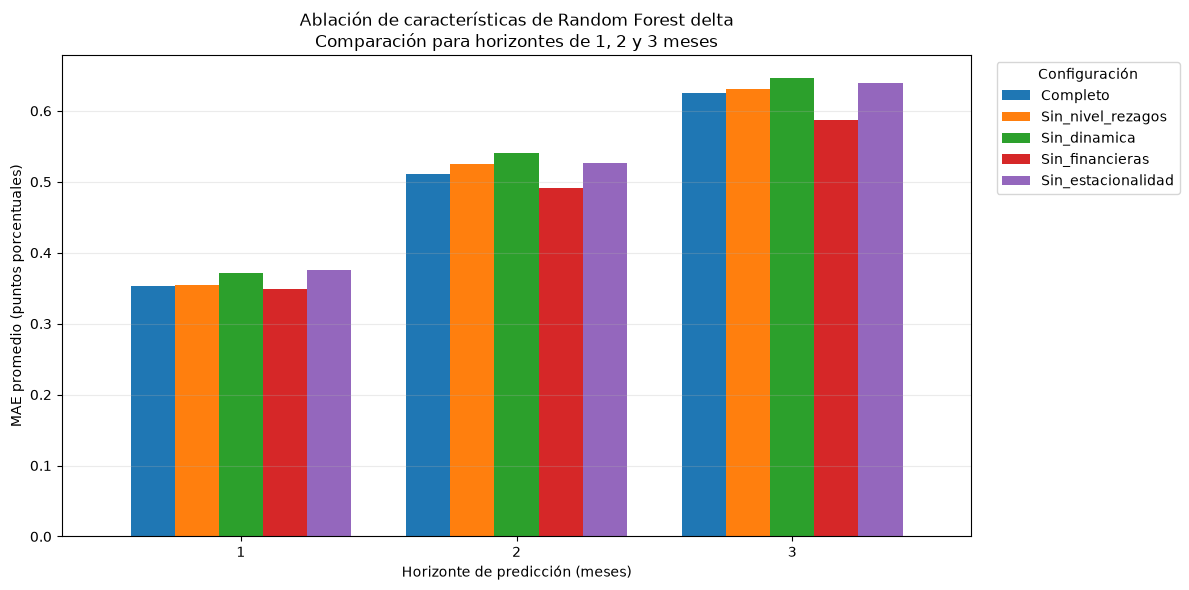

In [41]:
import matplotlib.pyplot as plt

# ======================================================
# E3.3.2 - GRÁFICO DE ABLACIONES
# ======================================================

tabla_grafico = resumen_ablacion_multi.pivot(
    index="horizonte",
    columns="escenario",
    values="mae_medio",
)

orden = [
    "Completo",
    "Sin_nivel_rezagos",
    "Sin_dinamica",
    "Sin_financieras",
    "Sin_estacionalidad",
]

ax = tabla_grafico[orden].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
)

ax.set_title(
    "Ablación de características de Random Forest delta\n"
    "Comparación para horizontes de 1, 2 y 3 meses"
)

ax.set_xlabel("Horizonte de predicción (meses)")
ax.set_ylabel("MAE promedio (puntos porcentuales)")

ax.set_xticklabels(
    tabla_grafico.index,
    rotation=0,
)

ax.legend(
    title="Configuración",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


## Construccion de nuevas caracteristicas dinamicas

In [42]:
import numpy as np
import pandas as pd
from IPython.display import display


# ======================================================
# E3.4.1 - INGENIERÍA DE CARACTERÍSTICAS
# ======================================================

def agregar_features_dinamicas(datos):
    """Construye características usando información de t y anterior."""

    requeridas = {
        "morosidad_pp",
        "morosidad_lag_1_pp",
        "morosidad_lag_2_pp",
        "morosidad_media_3m_pp",
        "morosidad_std_3m_pp",
        "morosidad_std_6m_pp",
    }

    faltantes = requeridas - set(datos.columns)

    if faltantes:
        raise ValueError(
            f"Faltan columnas: {sorted(faltantes)}"
        )

    resultado = datos.copy(deep=True)

    # 1. Aceleración mensual.
    resultado["aceleracion_morosidad_1m_pp"] = (
        resultado["morosidad_pp"]
        - 2 * resultado["morosidad_lag_1_pp"]
        + resultado["morosidad_lag_2_pp"]
    )

    # 2. Brecha respecto a la media móvil.
    resultado["brecha_morosidad_media_3m_pp"] = (
        resultado["morosidad_pp"]
        - resultado["morosidad_media_3m_pp"]
    )

    # 3. Diferencial de volatilidad.
    resultado["diferencial_volatilidad_3_6m_pp"] = (
        resultado["morosidad_std_3m_pp"]
        - resultado["morosidad_std_6m_pp"]
    )

    return resultado


# ======================================================
# 1. CONSTRUIR DATASET EXPERIMENTAL
# ======================================================

HORIZONTE_E34 = 1

datos_originales = datasets[
    HORIZONTE_E34
]["desarrollo"]

datos_e34 = agregar_features_dinamicas(
    datos_originales
)

features_nuevas = [
    "aceleracion_morosidad_1m_pp",
    "brecha_morosidad_media_3m_pp",
    "diferencial_volatilidad_3_6m_pp",
]

# ======================================================
# 2. VALIDAR INTEGRIDAD
# ======================================================

assert len(datos_e34) == len(datos_originales)

assert datos_e34.shape[1] == datos_originales.shape[1] + 3

assert not datos_e34.duplicated(
    ["banco", "fecha"]
).any()

# Los datos originales deben permanecer intactos.
pd.testing.assert_frame_equal(
    datos_originales,
    datasets[HORIZONTE_E34]["desarrollo"],
)

assert not np.isinf(
    datos_e34[features_nuevas].to_numpy(dtype=float)
).any()

# ======================================================
# 3. ANALIZAR FALTANTES
# ======================================================

auditoria_e34 = pd.DataFrame({
    "faltantes": datos_e34[
        features_nuevas
    ].isna().sum(),
    "faltantes_pct": (
        datos_e34[features_nuevas].isna().mean() * 100
    ),
    "media": datos_e34[features_nuevas].mean(),
    "std": datos_e34[features_nuevas].std(),
})

print("=== AUDITORÍA DE NUEVAS VARIABLES ===")

display(auditoria_e34.round(4))

print("\n=== EJEMPLOS DE OBSERVACIONES ===")

display(
    datos_e34[
        ["banco", "fecha"] + features_nuevas
    ].dropna().head(10)
)

print("\nNUEVAS CARACTERÍSTICAS CONSTRUIDAS CORRECTAMENTE")

=== AUDITORÍA DE NUEVAS VARIABLES ===


,faltantes,faltantes_pct,media,std
aceleracion_morosidad_1m_pp,46,0.8119,-0.0020,1.7063
brecha_morosidad_media_3m_pp,46,0.8119,-0.0169,0.7878
diferencial_volatilidad_3_6m_pp,115,2.0297,-0.1714,0.5640



=== EJEMPLOS DE OBSERVACIONES ===


,banco,fecha,aceleracion_morosidad_1m_pp,brecha_morosidad_media_3m_pp,diferencial_volatilidad_3_6m_pp
90,BANCO COMERCIAL DE MANABI,2003-06-01,1.965093,1.440525,0.176308
91,BP AMAZONAS,2003-06-01,0.390182,-0.949480,-0.180575
92,BP AUSTRO,2003-06-01,-0.504714,-0.186860,-3.419512
93,BP BOLIVARIANO,2003-06-01,-1.116910,-0.377544,0.020767
94,BP CAPITAL,2003-06-01,-1.161968,-1.472335,0.186855
95,BP CITIBANK,2003-06-01,1.486915,1.820822,-0.182474
96,BP COOPNACIONAL,2003-06-01,-0.092593,-0.068958,0.012416
97,BP GENERAL RUMINAHUI,2003-06-01,-3.222728,-0.197250,-0.117117
98,BP GUAYAQUIL,2003-06-01,0.411531,1.055865,-0.156845
99,BP INTERNACIONAL,2003-06-01,-0.481273,-0.224995,-0.253289



NUEVAS CARACTERÍSTICAS CONSTRUIDAS CORRECTAMENTE


### Comprobar los modelos con las nuevas caracteristicas

In [43]:
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo


# ======================================================
# E3.4.2 - DISEÑO DE ESCENARIOS
# ======================================================

config = datasets[HORIZONTE_E34]

predictoras_base = list(config["predictoras"])
numericas_base = list(config["numericas"])

escenarios_e34 = {
    "Referencia": [],
    "Mas_aceleracion": [
        "aceleracion_morosidad_1m_pp"
    ],
    "Mas_brecha": [
        "brecha_morosidad_media_3m_pp"
    ],
    "Mas_volatilidad": [
        "diferencial_volatilidad_3_6m_pp"
    ],
    "Mas_todas": features_nuevas,
}

target = config["target"]
fecha_target = config["fecha_target"]

resultados_e34 = []


# ======================================================
# 1. EJECUTAR LOS CINCO ESCENARIOS
# ======================================================

for escenario, adicionales in escenarios_e34.items():

    predictoras = predictoras_base + adicionales
    numericas = numericas_base + adicionales

    print(f"\n{'=' * 55}")
    print(f"ESCENARIO: {escenario}")
    print(f"PREDICTORES: {len(predictoras)}")
    print(f"{'=' * 55}")

    for fold in folds_cv[HORIZONTE_E34]:

        anio = fold["fold"]

        train = datos_e34.loc[
            fold["train_idx"]
        ].copy()

        val = datos_e34.loc[
            fold["val_idx"]
        ].copy()

        # ==========================================
        # 2. VERIFICAR INTEGRIDAD TEMPORAL
        # ==========================================

        assert train[fecha_target].max() < val["fecha"].min()

        # ==========================================
        # 3. PREPARAR DATOS
        # ==========================================

        X_train = train[predictoras].replace(
            [np.inf, -np.inf],
            np.nan,
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf],
            np.nan,
        )

        y_train_delta = (
            train[target]
            - train["morosidad_pp"]
        )

        y_real = val[target].to_numpy(
            dtype=float
        )

        # ==========================================
        # 4. ENTRENAR RANDOM FOREST
        # ==========================================

        modelo = construir_modelo(
            "RandomForest",
            numericas,
        )

        modelo.fit(
            X_train,
            y_train_delta,
        )

        # ==========================================
        # 5. RECONSTRUIR LA MOROSIDAD
        # ==========================================

        delta_predicha = modelo.predict(X_val)

        y_pred = (
            val["morosidad_pp"].to_numpy(dtype=float)
            + delta_predicha
        )

        assert np.isfinite(y_pred).all()

        # ==========================================
        # 6. EVALUAR
        # ==========================================

        mae = mean_absolute_error(
            y_real,
            y_pred,
        )

        resultados_e34.append({
            "horizonte": HORIZONTE_E34,
            "escenario": escenario,
            "fold": anio,
            "n_predictores": len(predictoras),
            "observaciones": len(val),
            "mae_pp": mae,
        })

        print(
            f"Fold {anio} | MAE: {mae:.4f} pp",
            flush=True,
        )


# ======================================================
# 7. CONSOLIDAR RESULTADOS
# ======================================================

detalle_e34 = pd.DataFrame(
    resultados_e34
)

assert len(detalle_e34) == 25

assert not detalle_e34.duplicated(
    ["horizonte", "escenario", "fold"]
).any()


# ======================================================
# 8. VERIFICAR REPRODUCIBILIDAD
# ======================================================

referencia_nueva = (
    detalle_e34.loc[
        detalle_e34["escenario"] == "Referencia",
        ["fold", "mae_pp"],
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

referencia_original = (
    detalle_rf.loc[
        (detalle_rf["horizonte"] == 1)
        & (
            detalle_rf["estrategia"]
            == "RandomForest_delta"
        ),
        ["fold", "mae_pp"],
    ]
    .sort_values("fold")
    .reset_index(drop=True)
)

assert referencia_nueva["fold"].equals(
    referencia_original["fold"]
)

np.testing.assert_allclose(
    referencia_nueva["mae_pp"].to_numpy(),
    referencia_original["mae_pp"].to_numpy(),
    rtol=0,
    atol=1e-9,
)

print("\n25 ENTRENAMIENTOS COMPLETADOS")
print("MODELO DE REFERENCIA REPRODUCIDO CORRECTAMENTE")


ESCENARIO: Referencia
PREDICTORES: 22
Fold 2021 | MAE: 0.3764 pp
Fold 2022 | MAE: 0.3817 pp
Fold 2023 | MAE: 0.3624 pp
Fold 2024 | MAE: 0.4005 pp
Fold 2025 | MAE: 0.2426 pp

ESCENARIO: Mas_aceleracion
PREDICTORES: 23
Fold 2021 | MAE: 0.3720 pp
Fold 2022 | MAE: 0.3809 pp
Fold 2023 | MAE: 0.3589 pp
Fold 2024 | MAE: 0.3984 pp
Fold 2025 | MAE: 0.2463 pp

ESCENARIO: Mas_brecha
PREDICTORES: 23
Fold 2021 | MAE: 0.3547 pp
Fold 2022 | MAE: 0.3801 pp
Fold 2023 | MAE: 0.3837 pp
Fold 2024 | MAE: 0.3878 pp
Fold 2025 | MAE: 0.2543 pp

ESCENARIO: Mas_volatilidad
PREDICTORES: 23
Fold 2021 | MAE: 0.3774 pp
Fold 2022 | MAE: 0.3781 pp
Fold 2023 | MAE: 0.3597 pp
Fold 2024 | MAE: 0.4031 pp
Fold 2025 | MAE: 0.2406 pp

ESCENARIO: Mas_todas
PREDICTORES: 25
Fold 2021 | MAE: 0.3558 pp
Fold 2022 | MAE: 0.3802 pp
Fold 2023 | MAE: 0.3842 pp
Fold 2024 | MAE: 0.3911 pp
Fold 2025 | MAE: 0.2515 pp

25 ENTRENAMIENTOS COMPLETADOS
MODELO DE REFERENCIA REPRODUCIDO CORRECTAMENTE


### Analisis de resultados

In [44]:
# ======================================================
# E3.4.2 - COMPARACIÓN DE NUEVAS CARACTERÍSTICAS
# ======================================================

resumen_e34 = (
    detalle_e34
    .groupby("escenario")
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        folds=("fold", "count"),
        predictores=("n_predictores", "first"),
    )
    .reset_index()
)

# ======================================================
# 1. MODELO DE REFERENCIA
# ======================================================

mae_referencia = float(
    resumen_e34.loc[
        resumen_e34["escenario"] == "Referencia",
        "mae_medio",
    ].iloc[0]
)

# Baseline estacional.
mae_estacional = float(
    detalle_baselines.loc[
        (detalle_baselines["horizonte"] == 1)
        & (
            detalle_baselines["modelo"]
            == "Persistencia_estacional"
        ),
        "mae_pp",
    ].mean()
)

# Mejor ablación anterior, sin financieras.
mae_sin_financieras = float(
    resumen_ablacion_multi.loc[
        (resumen_ablacion_multi["horizonte"] == 1)
        & (
            resumen_ablacion_multi["escenario"]
            == "Sin_financieras"
        ),
        "mae_medio",
    ].iloc[0]
)

# ======================================================
# 2. COMPARACIONES
# ======================================================

resumen_e34["diferencia_vs_referencia_pp"] = (
    resumen_e34["mae_medio"] - mae_referencia
)

resumen_e34["mejora_vs_referencia_pct"] = (
    100
    * (
        mae_referencia
        - resumen_e34["mae_medio"]
    )
    / mae_referencia
)

resumen_e34["mejora_vs_estacional_pct"] = (
    100
    * (
        mae_estacional
        - resumen_e34["mae_medio"]
    )
    / mae_estacional
)

resumen_e34 = (
    resumen_e34
    .sort_values("mae_medio")
    .reset_index(drop=True)
)

print("=== RESULTADOS DE INGENIERÍA DE CARACTERÍSTICAS ===")

display(resumen_e34.round(4))

print("\nREFERENCIAS")

print(f"Random Forest completo: {mae_referencia:.4f} pp")
print(f"Persistencia estacional: {mae_estacional:.4f} pp")
print(f"RF sin financieras: {mae_sin_financieras:.4f} pp")


# ======================================================
# 3. RESULTADOS POR FOLD
# ======================================================

tabla_folds_e34 = detalle_e34.pivot(
    index="fold",
    columns="escenario",
    values="mae_pp",
)

print("\n=== MAE POR FOLD ===")

display(tabla_folds_e34.round(4))


# ======================================================
# 4. CONSISTENCIA TEMPORAL
# ======================================================

consistencia_e34 = []

for escenario in escenarios_e34:

    if escenario == "Referencia":
        continue

    diferencias = (
        tabla_folds_e34[escenario]
        - tabla_folds_e34["Referencia"]
    )

    consistencia_e34.append({
        "escenario": escenario,
        "folds_mejora": int(
            (diferencias < 0).sum()
        ),
        "folds_empeora": int(
            (diferencias > 0).sum()
        ),
        "diferencia_media_pp": diferencias.mean(),
        "diferencia_min_pp": diferencias.min(),
        "diferencia_max_pp": diferencias.max(),
    })

consistencia_e34 = pd.DataFrame(
    consistencia_e34
)

print("\n=== CONSISTENCIA TEMPORAL ===")

display(
    consistencia_e34
    .sort_values("diferencia_media_pp")
    .round(4)
)

=== RESULTADOS DE INGENIERÍA DE CARACTERÍSTICAS ===


,escenario,mae_medio,mae_std,folds,predictores,diferencia_vs_referencia_pp,mejora_vs_referencia_pct,mejora_vs_estacional_pct
0,Mas_aceleracion,0.3513,0.0605,5,23,-0.0014,0.3966,2.8982
1,Mas_volatilidad,0.3518,0.0641,5,23,-0.0009,0.2659,2.7708
2,Mas_brecha,0.3521,0.0562,5,23,-0.0006,0.1670,2.6743
3,Mas_todas,0.3526,0.0580,5,25,-0.0001,0.0419,2.5523
4,Referencia,0.3527,0.0630,5,22,0.0000,0.0000,2.5115



REFERENCIAS
Random Forest completo: 0.3527 pp
Persistencia estacional: 0.3618 pp
RF sin financieras: 0.3490 pp

=== MAE POR FOLD ===


escenario,Mas_aceleracion,Mas_brecha,Mas_todas,Mas_volatilidad,Referencia
fold,,,,,
2021,0.3720,0.3547,0.3558,0.3774,0.3764
2022,0.3809,0.3801,0.3802,0.3781,0.3817
2023,0.3589,0.3837,0.3842,0.3597,0.3624
2024,0.3984,0.3878,0.3911,0.4031,0.4005
2025,0.2463,0.2543,0.2515,0.2406,0.2426



=== CONSISTENCIA TEMPORAL ===


,escenario,folds_mejora,folds_empeora,diferencia_media_pp,diferencia_min_pp,diferencia_max_pp
0,Mas_aceleracion,4,1,-0.0014,-0.0044,0.0037
2,Mas_volatilidad,3,2,-0.0009,-0.0035,0.0027
1,Mas_brecha,3,2,-0.0006,-0.0217,0.0213
3,Mas_todas,3,2,-0.0001,-0.0207,0.0218


## Extender la aceleracion a 2 y 3 meses

In [45]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo


# ======================================================
# E3.4.3 - ACELERACIÓN PARA HORIZONTES 2 Y 3
# ======================================================

FEATURE_ACELERACION = "aceleracion_morosidad_1m_pp"

resultados_aceleracion_h23 = []


for h in (2, 3):

    config = datasets[h]

    datos = config["desarrollo"].copy()

    # ==========================================
    # 1. CONSTRUIR ACELERACIÓN
    # ==========================================

    datos[FEATURE_ACELERACION] = (
        datos["morosidad_pp"]
        - 2 * datos["morosidad_lag_1_pp"]
        + datos["morosidad_lag_2_pp"]
    )

    assert not np.isinf(
        datos[FEATURE_ACELERACION].to_numpy(dtype=float)
    ).any()

    predictoras = (
        list(config["predictoras"])
        + [FEATURE_ACELERACION]
    )

    numericas = (
        list(config["numericas"])
        + [FEATURE_ACELERACION]
    )

    assert len(predictoras) == 23
    assert len(numericas) == 22

    target = config["target"]
    fecha_target = config["fecha_target"]

    print(f"\n{'=' * 55}")
    print(f"HORIZONTE: {h} MESES")
    print(f"{'=' * 55}")

    # ==========================================
    # 2. VALIDACIÓN TEMPORAL
    # ==========================================

    for fold in folds_cv[h]:

        anio = fold["fold"]

        train = datos.loc[fold["train_idx"]].copy()
        val = datos.loc[fold["val_idx"]].copy()

        assert train[fecha_target].max() < val["fecha"].min()

        # ==========================================
        # 3. PREPARAR VARIABLES
        # ==========================================

        X_train = train[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        X_val = val[predictoras].replace(
            [np.inf, -np.inf], np.nan
        )

        y_train_delta = (
            train[target] - train["morosidad_pp"]
        )

        y_real = val[target].to_numpy(dtype=float)

        assert np.isfinite(
            y_train_delta.to_numpy(dtype=float)
        ).all()

        assert np.isfinite(y_real).all()

        # ==========================================
        # 4. ENTRENAR RANDOM FOREST
        # ==========================================

        modelo = construir_modelo(
            "RandomForest",
            numericas,
        )

        modelo.fit(X_train, y_train_delta)

        # ==========================================
        # 5. PRONOSTICAR
        # ==========================================

        delta_pred = modelo.predict(X_val)

        y_pred = (
            val["morosidad_pp"].to_numpy(dtype=float)
            + delta_pred
        )

        mae = mean_absolute_error(y_real, y_pred)

        # ==========================================
        # 6. REGISTRAR RESULTADOS
        # ==========================================

        resultados_aceleracion_h23.append({
            "horizonte": h,
            "fold": anio,
            "escenario": "Mas_aceleracion",
            "observaciones": len(val),
            "mae_pp": mae,
        })

        print(
            f"Fold {anio} | MAE: {mae:.4f} pp",
            flush=True,
        )


detalle_aceleracion_h23 = pd.DataFrame(
    resultados_aceleracion_h23
)

assert len(detalle_aceleracion_h23) == 10

assert not detalle_aceleracion_h23.duplicated(
    ["horizonte", "fold", "escenario"]
).any()

print("\n10 ENTRENAMIENTOS COMPLETADOS")

display(detalle_aceleracion_h23.round(4))


HORIZONTE: 2 MESES
Fold 2021 | MAE: 0.6437 pp
Fold 2022 | MAE: 0.5218 pp
Fold 2023 | MAE: 0.4610 pp
Fold 2024 | MAE: 0.5965 pp
Fold 2025 | MAE: 0.3387 pp

HORIZONTE: 3 MESES
Fold 2021 | MAE: 0.8281 pp
Fold 2022 | MAE: 0.6222 pp
Fold 2023 | MAE: 0.5487 pp
Fold 2024 | MAE: 0.7112 pp
Fold 2025 | MAE: 0.4142 pp

10 ENTRENAMIENTOS COMPLETADOS


,horizonte,fold,escenario,observaciones,mae_pp
0,2,2021,Mas_aceleracion,276,0.6437
1,2,2022,Mas_aceleracion,276,0.5218
2,2,2023,Mas_aceleracion,276,0.4610
3,2,2024,Mas_aceleracion,276,0.5965
4,2,2025,Mas_aceleracion,161,0.3387
5,3,2021,Mas_aceleracion,276,0.8281
6,3,2022,Mas_aceleracion,276,0.6222
7,3,2023,Mas_aceleracion,276,0.5487
8,3,2024,Mas_aceleracion,276,0.7112
9,3,2025,Mas_aceleracion,138,0.4142


## Optimizacion de hiperparametros de random forest

### Optimizacion y definicion de hiperparametros

In [46]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

from src.modeling.models import construir_modelo


# ======================================================
# E4 - CONFIGURACIONES DE HIPERPARÁMETROS
# ======================================================

configuraciones_e4 = {
    "Regularizado": {
        "n_estimators": 150,
        "max_depth": 6,
        "min_samples_leaf": 10,
        "max_features": 0.7,
    },
    "Intermedio": {
        "n_estimators": 150,
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": 0.7,
    },
    "Flexible": {
        "n_estimators": 150,
        "max_depth": 14,
        "min_samples_leaf": 3,
        "max_features": 0.7,
    },
    "Profundo": {
        "n_estimators": 150,
        "max_depth": 16,
        "min_samples_leaf": 3,
        "max_features": 1.0,
    },
}


# ======================================================
# 1. RECUPERAR EL MODELO ORIGINAL
# ======================================================

referencia_e4 = (
    detalle_rf.loc[
        detalle_rf["estrategia"] == "RandomForest_delta",
        ["horizonte", "fold", "observaciones", "mae_pp"],
    ]
    .copy()
)

referencia_e4["configuracion"] = "Original"

assert len(referencia_e4) == 15


# ======================================================
# 2. FUNCIÓN PARA CONFIGURAR EL RANDOM FOREST
# ======================================================

def construir_rf_optimizado(numericas, parametros):

    modelo = construir_modelo(
        "RandomForest",
        numericas,
    )

    # Encontrar el nombre real del estimador en el pipeline.
    pasos_rf = [
        nombre
        for nombre, estimador in modelo.named_steps.items()
        if isinstance(estimador, RandomForestRegressor)
    ]

    assert len(pasos_rf) == 1

    nombre_estimador = pasos_rf[0]

    parametros_pipeline = {
        f"{nombre_estimador}__{clave}": valor
        for clave, valor in parametros.items()
    }

    modelo.set_params(**parametros_pipeline)

    return modelo


# ======================================================
# 3. VALIDAR CONFIGURACIÓN ORIGINAL
# ======================================================

modelo_original = construir_modelo(
    "RandomForest",
    datasets[1]["numericas"],
)

estimador_original = next(
    estimador
    for estimador in modelo_original.named_steps.values()
    if isinstance(estimador, RandomForestRegressor)
)

assert estimador_original.n_estimators == 100
assert estimador_original.max_depth == 10
assert estimador_original.min_samples_leaf == 5
assert estimador_original.max_features == 1.0
assert estimador_original.random_state == 42


# ======================================================
# 4. EVALUACIÓN TEMPORAL
# ======================================================

resultados_optimizacion = []

for h in (1, 2, 3):

    config = datasets[h]

    datos = config["desarrollo"]

    predictoras = list(config["predictoras"])
    numericas = list(config["numericas"])

    target = config["target"]
    fecha_target = config["fecha_target"]

    print(f"\n{'=' * 55}")
    print(f"HORIZONTE: {h} MESES")
    print(f"{'=' * 55}", flush=True)

    for nombre, parametros in configuraciones_e4.items():

        print(
            f"\nConfiguración: {nombre}",
            flush=True,
        )

        for fold in folds_cv[h]:

            anio = fold["fold"]

            train = datos.loc[
                fold["train_idx"]
            ].copy()

            val = datos.loc[
                fold["val_idx"]
            ].copy()

            # ======================================
            # INTEGRIDAD TEMPORAL
            # ======================================

            assert train[fecha_target].max() < val["fecha"].min()

            # ======================================
            # PREDICTORES
            # ======================================

            X_train = train[predictoras].replace(
                [np.inf, -np.inf],
                np.nan,
            )

            X_val = val[predictoras].replace(
                [np.inf, -np.inf],
                np.nan,
            )

            # ======================================
            # OBJETIVO DELTA
            # ======================================

            y_train = (
                train[target]
                - train["morosidad_pp"]
            )

            y_real = val[target].to_numpy(
                dtype=float
            )

            assert np.isfinite(
                y_train.to_numpy(dtype=float)
            ).all()

            assert np.isfinite(y_real).all()

            # ======================================
            # CONSTRUIR Y ENTRENAR
            # ======================================

            modelo = construir_rf_optimizado(
                numericas,
                parametros,
            )

            modelo.fit(X_train, y_train)

            # ======================================
            # PRONOSTICAR NIVEL FUTURO
            # ======================================

            delta_predicha = modelo.predict(X_val)

            y_pred = (
                val["morosidad_pp"].to_numpy(dtype=float)
                + delta_predicha
            )

            assert np.isfinite(y_pred).all()

            mae = mean_absolute_error(
                y_real,
                y_pred,
            )

            resultados_optimizacion.append({
                "horizonte": h,
                "fold": anio,
                "configuracion": nombre,
                "observaciones": len(val),
                "mae_pp": mae,
            })

            print(
                f"  Fold {anio}: MAE = {mae:.4f} pp",
                flush=True,
            )


# ======================================================
# 5. CONSOLIDAR CON EL MODELO ORIGINAL
# ======================================================

detalle_opt_nuevos = pd.DataFrame(
    resultados_optimizacion
)

detalle_opt_e4 = pd.concat(
    [
        referencia_e4,
        detalle_opt_nuevos,
    ],
    ignore_index=True,
)

assert len(detalle_opt_nuevos) == 60
assert len(detalle_opt_e4) == 75

assert not detalle_opt_e4.duplicated(
    ["horizonte", "fold", "configuracion"]
).any()

assert (
    detalle_opt_e4
    .groupby(["horizonte", "configuracion"])["fold"]
    .nunique()
    .eq(5)
    .all()
)

print("\nOPTIMIZACIÓN E4 COMPLETADA")
print("75 evaluaciones disponibles, 60 entrenamientos nuevos.")


HORIZONTE: 1 MESES

Configuración: Regularizado
  Fold 2021: MAE = 0.3787 pp
  Fold 2022: MAE = 0.3910 pp
  Fold 2023: MAE = 0.3642 pp
  Fold 2024: MAE = 0.4016 pp
  Fold 2025: MAE = 0.2538 pp

Configuración: Intermedio
  Fold 2021: MAE = 0.3920 pp
  Fold 2022: MAE = 0.3773 pp
  Fold 2023: MAE = 0.3542 pp
  Fold 2024: MAE = 0.4022 pp
  Fold 2025: MAE = 0.2372 pp

Configuración: Flexible
  Fold 2021: MAE = 0.3884 pp
  Fold 2022: MAE = 0.3671 pp
  Fold 2023: MAE = 0.3549 pp
  Fold 2024: MAE = 0.4043 pp
  Fold 2025: MAE = 0.2292 pp

Configuración: Profundo
  Fold 2021: MAE = 0.3960 pp
  Fold 2022: MAE = 0.3701 pp
  Fold 2023: MAE = 0.3671 pp
  Fold 2024: MAE = 0.4050 pp
  Fold 2025: MAE = 0.2317 pp

HORIZONTE: 2 MESES

Configuración: Regularizado
  Fold 2021: MAE = 0.6275 pp
  Fold 2022: MAE = 0.5285 pp
  Fold 2023: MAE = 0.4700 pp
  Fold 2024: MAE = 0.5921 pp
  Fold 2025: MAE = 0.3308 pp

Configuración: Intermedio
  Fold 2021: MAE = 0.6165 pp
  Fold 2022: MAE = 0.5123 pp
  Fold 2023: MA

### comparacion de Configuraciones y robustez 

In [47]:
# ======================================================
# E4 - COMPARACIÓN DE HIPERPARÁMETROS
# ======================================================

# ======================================================
# 1. REFERENCIAS POR FOLD
# ======================================================

referencia_original = (
    detalle_opt_e4.loc[
        detalle_opt_e4["configuracion"] == "Original",
        ["horizonte", "fold", "mae_pp"],
    ]
    .rename(columns={
        "mae_pp": "mae_original"
    })
)

referencia_estacional = (
    detalle_baselines.loc[
        detalle_baselines["modelo"]
        == "Persistencia_estacional",
        ["horizonte", "fold", "mae_pp"],
    ]
    .rename(columns={
        "mae_pp": "mae_estacional"
    })
)

# ======================================================
# 2. COMPARACIÓN PAREADA
# ======================================================

comparacion_opt = (
    detalle_opt_e4
    .merge(
        referencia_original,
        on=["horizonte", "fold"],
        validate="many_to_one",
    )
    .merge(
        referencia_estacional,
        on=["horizonte", "fold"],
        validate="many_to_one",
    )
)

comparacion_opt["diferencia_vs_original"] = (
    comparacion_opt["mae_pp"]
    - comparacion_opt["mae_original"]
)

comparacion_opt["diferencia_vs_estacional"] = (
    comparacion_opt["mae_pp"]
    - comparacion_opt["mae_estacional"]
)

comparacion_opt["gana_original"] = (
    comparacion_opt["diferencia_vs_original"] < 0
)

comparacion_opt["gana_estacional"] = (
    comparacion_opt["diferencia_vs_estacional"] < 0
)

# ======================================================
# 3. RESUMEN DE LOS CINCO FOLDS
# ======================================================

resumen_opt_e4 = (
    comparacion_opt
    .groupby(["horizonte", "configuracion"], as_index=False)
    .agg(
        mae_medio=("mae_pp", "mean"),
        mae_std=("mae_pp", "std"),
        mae_original=("mae_original", "mean"),
        mae_estacional=("mae_estacional", "mean"),
        folds_mejora_original=("gana_original", "sum"),
        folds_mejora_estacional=("gana_estacional", "sum"),
        diferencia_media_pp=("diferencia_vs_original", "mean"),
    )
)

resumen_opt_e4["mejora_vs_original_pct"] = (
    100
    * (
        resumen_opt_e4["mae_original"]
        - resumen_opt_e4["mae_medio"]
    )
    / resumen_opt_e4["mae_original"]
)

resumen_opt_e4["mejora_vs_estacional_pct"] = (
    100
    * (
        resumen_opt_e4["mae_estacional"]
        - resumen_opt_e4["mae_medio"]
    )
    / resumen_opt_e4["mae_estacional"]
)

# ======================================================
# 4. SENSIBILIDAD AL AÑO 2021
# ======================================================

mae_2022_2025 = (
    comparacion_opt.loc[
        comparacion_opt["fold"].between(2022, 2025)
    ]
    .groupby(["horizonte", "configuracion"], as_index=False)
    .agg(
        mae_2022_2025=("mae_pp", "mean")
    )
)

resumen_opt_e4 = resumen_opt_e4.merge(
    mae_2022_2025,
    on=["horizonte", "configuracion"],
    validate="one_to_one",
)

resumen_opt_e4 = resumen_opt_e4.sort_values(
    ["horizonte", "mae_medio"]
).reset_index(drop=True)

# ======================================================
# 5. RESULTADOS
# ======================================================

print("=== OPTIMIZACIÓN: RESULTADOS POR HORIZONTE ===")

display(
    resumen_opt_e4[
        [
            "horizonte",
            "configuracion",
            "mae_medio",
            "mae_std",
            "folds_mejora_original",
            "folds_mejora_estacional",
            "mejora_vs_original_pct",
            "mejora_vs_estacional_pct",
            "mae_2022_2025",
        ]
    ].round(4)
)

# ======================================================
# 6. MEJOR CONFIGURACIÓN POR HORIZONTE
# ======================================================

mejores_opt_e4 = (
    resumen_opt_e4
    .sort_values(["horizonte", "mae_medio"])
    .drop_duplicates("horizonte")
)

print("\n=== MENOR MAE DE CADA HORIZONTE ===")

display(
    mejores_opt_e4[
        [
            "horizonte",
            "configuracion",
            "mae_medio",
            "mae_estacional",
            "mejora_vs_estacional_pct",
        ]
    ].round(4)
)

# ======================================================
# 7. DETALLE POR FOLD
# ======================================================

tabla_folds_opt_e4 = detalle_opt_e4.pivot(
    index=["horizonte", "fold"],
    columns="configuracion",
    values="mae_pp",
)

print("\n=== MAE POR FOLD ===")

display(tabla_folds_opt_e4.round(4))

=== OPTIMIZACIÓN: RESULTADOS POR HORIZONTE ===


,horizonte,configuracion,mae_medio,mae_std,folds_mejora_original,folds_mejora_estacional,mejora_vs_original_pct,mejora_vs_estacional_pct,mae_2022_2025
0,1,Flexible,0.3488,0.0695,3,4,1.1203,3.6037,0.3389
1,1,Intermedio,0.3526,0.0670,3,4,0.0471,2.5574,0.3427
2,1,Original,0.3527,0.0630,0,4,0.0000,2.5115,0.3468
3,1,Profundo,0.3540,0.0703,2,4,-0.3532,2.1672,0.3435
4,1,Regularizado,0.3579,0.0598,0,3,-1.4590,1.0892,0.3527
5,2,Intermedio,0.5011,0.1177,4,4,1.9911,-1.2793,0.4723
6,2,Profundo,0.5049,0.1073,2,4,1.2438,-2.0515,0.4805
7,2,Regularizado,0.5098,0.1168,3,4,0.2977,-3.0292,0.4803
8,2,Original,0.5113,0.1175,0,4,0.0000,-3.3369,0.4795
9,2,Flexible,0.5145,0.1269,3,3,-0.6186,-3.9761,0.4792



=== MENOR MAE DE CADA HORIZONTE ===


,horizonte,configuracion,mae_medio,mae_estacional,mejora_vs_estacional_pct
0,1,Flexible,0.3488,0.3618,3.6037
5,2,Intermedio,0.5011,0.4948,-1.2793
10,3,Intermedio,0.6181,0.5963,-3.6535



=== MAE POR FOLD ===


configuracion   Flexible  Intermedio  Original  Profundo  Regularizado
horizonte fold                                                        
1         2021    0.3884      0.3920    0.3764    0.3960        0.3787
          2022    0.3671      0.3773    0.3817    0.3701        0.3910
          2023    0.3549      0.3542    0.3624    0.3671        0.3642
          2024    0.4043      0.4022    0.4005    0.4050        0.4016
          2025    0.2292      0.2372    0.2426    0.2317        0.2538
2         2021    0.6553      0.6165    0.6385    0.6025        0.6275
          2022    0.5129      0.5123    0.5193    0.5068        0.5285
          2023    0.4573      0.4558    0.4645    0.4708        0.4700
          2024    0.6110      0.5958    0.5953    0.6011        0.5921
          2025    0.3357      0.3252    0.3389    0.3434        0.3308
3         2021    0.9325      0.7890    0.8268    0.9212        0.8190
          2022    0.6195      0.6232    0.6236    0.6240        0.6494
          2023    0.5393      0.5417    0.5486    0.5604        0.5509
          2024    0.7232      0.7366    0.7157    0.7353        0.7360
          2025    0.4145      0.3998    0.4136    0.3993        0.4100

In [48]:
from sklearn.metrics import mean_absolute_error

from src.modeling.forecast import (
    entrenar_y_predecir_horizonte,
)


resultados_reproduccion = []

for h in (1, 2, 3):

    config = datasets[h]
    datos = config["desarrollo"]

    fold = next(
        f for f in folds_cv[h]
        if f["fold"] == 2024
    )

    train = datos.loc[fold["train_idx"]]
    val = datos.loc[fold["val_idx"]]

    predicciones = entrenar_y_predecir_horizonte(
        horizonte=h,
        entrenamiento=train,
        validacion=val,
        target=config["target"],
        fecha_target=config["fecha_target"],
        numericas=config["numericas"],
        predictoras=config["predictoras"],
    )

    mae = mean_absolute_error(
        val[config["target"]],
        predicciones,
    )

    resultados_reproduccion.append({
        "horizonte": h,
        "estrategia": (
            "RF flexible" if h == 1
            else "Persistencia estacional"
        ),
        "mae_pp": mae,
    })

    print(f"Horizonte {h}: MAE = {mae:.6f} pp")

Horizonte 1: MAE = 0.404312 pp
Horizonte 2: MAE = 0.604352 pp
Horizonte 3: MAE = 0.683091 pp


In [49]:
import numpy as np
import pandas as pd

from IPython.display import display

from src.modeling.train import (
    evaluar_sistema_final_cv as ejecutar_cv_final,
)

from src.modeling.evaluate import (
    evaluar_sistema_final_cv as comparar_cv_final,
)


# ======================================================
# 1. EJECUTAR SISTEMA HÍBRIDO
# ======================================================

detalle_final, predicciones_final = ejecutar_cv_final(
    datasets,
    folds_cv,
)

resumen_final, comparacion_final = comparar_cv_final(
    detalle_final,
    detalle_baselines,
)

assert len(detalle_final) == 15
assert len(predicciones_final) == 3795
assert len(resumen_final) == 3

print("=== RESULTADOS DEL SISTEMA FINAL ===")

display(resumen_final.round(4))


# ======================================================
# 2. VERIFICAR CONTRA EXPERIMENTOS ORIGINALES
# ======================================================

referencia_h1 = (
    detalle_opt_e4.loc[
        (detalle_opt_e4["horizonte"] == 1)
        & (detalle_opt_e4["configuracion"] == "Flexible"),
        ["horizonte", "fold", "mae_pp"],
    ]
)

referencia_h23 = (
    detalle_baselines.loc[
        detalle_baselines["horizonte"].isin([2, 3])
        & (
            detalle_baselines["modelo"]
            == "Persistencia_estacional"
        ),
        ["horizonte", "fold", "mae_pp"],
    ]
)

referencias = pd.concat(
    [referencia_h1, referencia_h23],
    ignore_index=True,
)

verificacion = detalle_final.merge(
    referencias.rename(columns={
        "mae_pp": "mae_experimento",
    }),
    on=["horizonte", "fold"],
    validate="one_to_one",
)

assert len(verificacion) == 15

np.testing.assert_allclose(
    verificacion["mae_pp"],
    verificacion["mae_experimento"],
    rtol=0,
    atol=1e-9,
)

print("\nREPRODUCCIÓN DE LOS 15 FOLDS: CORRECTA")

=== RESULTADOS DEL SISTEMA FINAL ===


,horizonte,estrategia,mae_medio,mae_std,rmse_medio,sesgo_medio,mae_estacional,folds,folds_ganados,folds_empatados,folds_perdidos,ventaja_media_pp,mejora_vs_estacional_pct
0,1,RandomForest_delta_flexible,0.3488,0.0695,0.7178,-0.0335,0.3618,5,4,0,1,0.013,3.6037
1,2,Persistencia_estacional,0.4948,0.0913,0.9368,0.0056,0.4948,5,0,5,0,0.000,0.0000
2,3,Persistencia_estacional,0.5963,0.1058,1.1184,0.0070,0.5963,5,0,5,0,0.000,0.0000



REPRODUCCIÓN DE LOS 15 FOLDS: CORRECTA


In [50]:
import pandas as pd
from IPython.display import display

auditoria_temporal = []
entrenamiento_final = {}

for h in (1, 2, 3):

    config = datasets[h]

    desarrollo = config["desarrollo"]
    test = config["test"]
    fecha_target = config["fecha_target"]

    # Comparar por mes calendario.
    fechas_target = pd.to_datetime(
        desarrollo[fecha_target]
    ).dt.to_period("M")

    fechas_origen_test = pd.to_datetime(
        test["fecha"]
    ).dt.to_period("M")

    primer_origen_test = fechas_origen_test.min()

    # Solo entrenar con objetivos conocidos
    # antes del primer origen del Test.
    mascara_segura = (
        fechas_target < primer_origen_test
    )

    train_seguro = desarrollo.loc[
        mascara_segura
    ].copy()

    assert not train_seguro.empty

    fechas_seguras = pd.to_datetime(
        train_seguro[fecha_target]
    ).dt.to_period("M")

    assert fechas_seguras.max() < primer_origen_test

    entrenamiento_final[h] = train_seguro

    auditoria_temporal.append({
        "horizonte": h,
        "primer_origen_test": str(primer_origen_test),
        "ultimo_target_desarrollo": str(
            fechas_target.max()
        ),
        "ultimo_target_seguro": str(
            fechas_seguras.max()
        ),
        "filas_desarrollo": len(desarrollo),
        "filas_entrenamiento_seguro": len(train_seguro),
        "filas_excluidas": int((~mascara_segura).sum()),
        "filas_test": len(test),
    })

resumen_auditoria = pd.DataFrame(auditoria_temporal)

display(resumen_auditoria)

,horizonte,primer_origen_test,ultimo_target_desarrollo,ultimo_target_seguro,filas_desarrollo,filas_entrenamiento_seguro,filas_excluidas,filas_test
0,1,2025-09,2025-09,2025-08,5666,5643,23,276
1,2,2025-09,2025-09,2025-08,5644,5621,23,253
2,3,2025-09,2025-09,2025-08,5621,5598,23,230


## Evaluacion final sobre test

In [51]:
import numpy as np
import pandas as pd

from IPython.display import display

# ======================================================
# E6.1 - PREPARAR TEST SIN ETIQUETAS FUTURAS
# ======================================================

entradas_test = {}

for h in (1, 2, 3):

    config = datasets[h]
    test = config["test"].copy()
    train = entrenamiento_final[h]

    target = config["target"]
    fecha_target = config["fecha_target"]

    # Las fechas objetivo pueden conocerse,
    # pero NO sus valores de morosidad.
    columnas_futuras = [
        c for c in test.columns
        if c.startswith("target_")
    ]

    entrada = test.drop(
        columns=columnas_futuras
    )

    assert target not in entrada.columns

    assert set(config["predictoras"]).issubset(
        entrada.columns
    )

    assert not test.duplicated(
        ["banco", "fecha"]
    ).any()

    # Seguridad temporal por mes.
    ultimo_target_train = (
        pd.to_datetime(train[fecha_target])
        .dt.to_period("M")
        .max()
    )

    primer_origen_test = (
        pd.to_datetime(test["fecha"])
        .dt.to_period("M")
        .min()
    )

    assert ultimo_target_train < primer_origen_test

    assert (
        pd.to_datetime(test[fecha_target]).dt.to_period("M")
        > pd.to_datetime(test["fecha"]).dt.to_period("M")
    ).all()

    entradas_test[h] = entrada

    print(
        f"Horizonte {h}: "
        f"{len(train)} entrenamiento, "
        f"{len(entrada)} Test, "
        "sin etiquetas futuras."
    )

print("\nPREPARACIÓN DE TEST VALIDADA")

Horizonte 1: 5643 entrenamiento, 276 Test, sin etiquetas futuras.
Horizonte 2: 5621 entrenamiento, 253 Test, sin etiquetas futuras.
Horizonte 3: 5598 entrenamiento, 230 Test, sin etiquetas futuras.

PREPARACIÓN DE TEST VALIDADA


### Entrenar y evaluar en test

In [52]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from src.modeling.forecast import (
    entrenar_y_predecir_horizonte,
)

from src.modeling.baselines import (
    predecir_persistencia_estacional,
)

# ======================================================
# E6.2 - EVALUACIÓN FINAL SOBRE TEST
# ======================================================

resultados_test = []
predicciones_test = []

for h in (1, 2, 3):

    config = datasets[h]

    train = entrenamiento_final[h]
    test = config["test"]
    entrada = entradas_test[h]

    target = config["target"]
    fecha_target = config["fecha_target"]

    # ==========================================
    # 1. PRONÓSTICO DEL SISTEMA HÍBRIDO
    # ==========================================

    y_pred = entrenar_y_predecir_horizonte(
        horizonte=h,
        entrenamiento=train,
        validacion=entrada,
        target=target,
        fecha_target=fecha_target,
        numericas=config["numericas"],
        predictoras=config["predictoras"],
    )

    # ==========================================
    # 2. BASELINE ESTACIONAL INDEPENDIENTE
    # ==========================================

    y_baseline = predecir_persistencia_estacional(
        train,
        entrada,
        target,
        fecha_target,
    )

    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)

    y_baseline = np.asarray(
        y_baseline, dtype=float
    ).reshape(-1)

    if len(y_pred) != len(test):
        raise ValueError(
            f"Longitud incorrecta de pronósticos: h={h}"
        )

    if len(y_baseline) != len(test):
        raise ValueError(
            f"Longitud incorrecta del baseline: h={h}"
        )

    if not np.isfinite(y_pred).all():
        raise ValueError(
            f"Predicciones no finitas: h={h}"
        )

    if not np.isfinite(y_baseline).all():
        raise ValueError(
            f"Baseline no finito: h={h}"
        )

    # En h=2,3 el híbrido debe reproducir el baseline.
    if h in (2, 3):
        np.testing.assert_allclose(
            y_pred,
            y_baseline,
            rtol=0,
            atol=1e-9,
        )

    # ==========================================
    # 3. REVELAR ETIQUETAS PARA EVALUACIÓN
    # ==========================================

    y_real = test[target].to_numpy(dtype=float)

    assert np.isfinite(y_real).all()

    # ==========================================
    # 4. MÉTRICAS
    # ==========================================

    mae = mean_absolute_error(y_real, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_real, y_pred)
    )

    sesgo = np.mean(y_real - y_pred)

    r2 = r2_score(y_real, y_pred)

    mae_baseline = mean_absolute_error(
        y_real, y_baseline
    )

    mejora = (
        100 * (mae_baseline - mae) / mae_baseline
        if mae_baseline > 0
        else np.nan
    )

    estrategia = (
        "RandomForest_delta_flexible"
        if h == 1
        else "Persistencia_estacional"
    )

    resultados_test.append({
        "horizonte": h,
        "estrategia": estrategia,
        "observaciones": len(test),
        "mae_pp": mae,
        "rmse_pp": rmse,
        "r2": r2,
        "sesgo_pp": sesgo,
        "mae_estacional": mae_baseline,
        "mejora_vs_estacional_pct": mejora,
    })

    # ==========================================
    # 5. PREDICCIONES INDIVIDUALES
    # ==========================================

    predicciones_test.append(
        pd.DataFrame({
            "horizonte": h,
            "banco": test["banco"].to_numpy(),
            "fecha": test["fecha"].to_numpy(),
            "fecha_objetivo": test[
                fecha_target
            ].to_numpy(),
            "y_real": y_real,
            "y_pred": y_pred,
            "y_baseline": y_baseline,
            "error_pp": y_real - y_pred,
            "error_abs_pp": np.abs(y_real - y_pred),
            "error_baseline_abs_pp": np.abs(
                y_real - y_baseline
            ),
        })
    )

    print(f"Horizonte {h}: evaluación completada.")


# ======================================================
# 6. RESULTADOS CONSOLIDADOS
# ======================================================

resumen_test = pd.DataFrame(resultados_test)

predicciones_test = pd.concat(
    predicciones_test,
    ignore_index=True,
)

assert len(resumen_test) == 3

assert len(predicciones_test) == (
    276 + 253 + 230
)

print("\n=== RESULTADOS FINALES SOBRE TEST ===")

display(resumen_test.round(4))

Horizonte 1: evaluación completada.
Horizonte 2: evaluación completada.
Horizonte 3: evaluación completada.

=== RESULTADOS FINALES SOBRE TEST ===


,horizonte,estrategia,observaciones,mae_pp,rmse_pp,r2,sesgo_pp,mae_estacional,mejora_vs_estacional_pct
0,1,RandomForest_delta_flexible,276,0.2839,0.4765,0.9590,-0.0611,0.3092,8.1908
1,2,Persistencia_estacional,253,0.3902,0.6937,0.9111,-0.0543,0.3902,0.0000
2,3,Persistencia_estacional,230,0.4636,0.8031,0.8798,-0.0821,0.4636,0.0000


## Diagnostico final de errores

In [53]:
import numpy as np
import pandas as pd
from IPython.display import display

# ======================================================
# E7.1 - PREPARAR DATOS PARA DIAGNÓSTICO
# ======================================================

diagnostico_test = predicciones_test.copy()

diagnostico_test["fecha"] = pd.to_datetime(
    diagnostico_test["fecha"]
)

diagnostico_test["fecha_objetivo"] = pd.to_datetime(
    diagnostico_test["fecha_objetivo"]
)

# Recuperar morosidad conocida en el mes de origen.
actuales = pd.concat(
    [
        datasets[h]["test"][
            ["banco", "fecha", "morosidad_pp"]
        ].assign(horizonte=h)
        for h in (1, 2, 3)
    ],
    ignore_index=True,
)

actuales["fecha"] = pd.to_datetime(actuales["fecha"])

diagnostico_test = diagnostico_test.merge(
    actuales,
    on=["horizonte", "banco", "fecha"],
    how="left",
    validate="one_to_one",
)

assert len(diagnostico_test) == 759
assert diagnostico_test["morosidad_pp"].notna().all()

# Positivo = nuestro modelo comete menos error.
diagnostico_test["ventaja_error_pp"] = (
    diagnostico_test["error_baseline_abs_pp"]
    - diagnostico_test["error_abs_pp"]
)

diagnostico_test["mes_objetivo"] = (
    diagnostico_test["fecha_objetivo"]
    .dt.to_period("M")
    .astype(str)
)

# ======================================================
# 1. ERRORES POR BANCO
# ======================================================

errores_por_banco = (
    diagnostico_test
    .groupby(["horizonte", "banco"], as_index=False)
    .agg(
        observaciones=("y_real", "size"),
        mae_modelo=("error_abs_pp", "mean"),
        mae_baseline=("error_baseline_abs_pp", "mean"),
        ventaja_total_pp=("ventaja_error_pp", "sum"),
    )
)

errores_por_banco["ventaja_media_pp"] = (
    errores_por_banco["mae_baseline"]
    - errores_por_banco["mae_modelo"]
)

# Nos interesa especialmente el horizonte 1.
bancos_h1 = errores_por_banco.loc[
    errores_por_banco["horizonte"] == 1
]

print("=== HORIZONTE 1: BANCOS CON MAYOR MAE ===")

display(
    bancos_h1
    .sort_values("mae_modelo", ascending=False)
    .head(10)
    .round(4)
)

print("\n=== HORIZONTE 1: MAYOR MEJORA SOBRE BASELINE ===")

display(
    bancos_h1
    .sort_values("ventaja_total_pp", ascending=False)
    .head(10)
    .round(4)
)

print("\n=== HORIZONTE 1: MAYOR DETERIORO FRENTE AL BASELINE ===")

display(
    bancos_h1
    .sort_values("ventaja_total_pp")
    .head(10)
    .round(4)
)

# ======================================================
# 2. ERRORES POR MES OBJETIVO
# ======================================================

errores_por_mes = (
    diagnostico_test
    .groupby(["horizonte", "mes_objetivo"], as_index=False)
    .agg(
        observaciones=("y_real", "size"),
        mae_modelo=("error_abs_pp", "mean"),
        mae_baseline=("error_baseline_abs_pp", "mean"),
    )
)

errores_por_mes["ventaja_pp"] = (
    errores_por_mes["mae_baseline"]
    - errores_por_mes["mae_modelo"]
)

print("\n=== MAE POR MES OBJETIVO ===")

display(
    errores_por_mes
    .sort_values(["horizonte", "mes_objetivo"])
    .round(4)
)

=== HORIZONTE 1: BANCOS CON MAYOR MAE ===


,horizonte,banco,observaciones,mae_modelo,mae_baseline,ventaja_total_pp,ventaja_media_pp
1,1,BANCO COMERCIAL DE MANABI,12,0.8568,1.0012,1.7320,0.1443
9,1,BP DELBANK,12,0.7936,0.8633,0.8362,0.0697
14,1,BP LITORAL,12,0.7698,1.0374,3.2106,0.2676
0,1,BANCO ATLANTIDA S.A.,12,0.7693,0.6003,-2.0273,-0.1689
2,1,BP AMAZONAS,12,0.5909,0.7178,1.5229,0.1269
6,1,BP CAPITAL,12,0.4260,0.4791,0.6378,0.0532
4,1,"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODES...",12,0.2645,0.2298,-0.4175,-0.0348
19,1,BP PROCREDIT,12,0.2410,0.2476,0.0792,0.0066
10,1,BP DINERS,12,0.2238,0.2312,0.0893,0.0074
21,1,BP SOLIDARIO,12,0.1989,0.1910,-0.0954,-0.0080



=== HORIZONTE 1: MAYOR MEJORA SOBRE BASELINE ===


,horizonte,banco,observaciones,mae_modelo,mae_baseline,ventaja_total_pp,ventaja_media_pp
14,1,BP LITORAL,12,0.7698,1.0374,3.2106,0.2676
1,1,BANCO COMERCIAL DE MANABI,12,0.8568,1.0012,1.7320,0.1443
2,1,BP AMAZONAS,12,0.5909,0.7178,1.5229,0.1269
9,1,BP DELBANK,12,0.7936,0.8633,0.8362,0.0697
6,1,BP CAPITAL,12,0.4260,0.4791,0.6378,0.0532
12,1,BP GUAYAQUIL,12,0.0811,0.1242,0.5177,0.0431
16,1,BP MACHALA,12,0.1016,0.1447,0.5176,0.0431
17,1,BP PACIFICO,12,0.1014,0.1374,0.4313,0.0359
20,1,BP PRODUBANCO,12,0.0596,0.0878,0.3384,0.0282
8,1,BP COOPNACIONAL,12,0.0708,0.0979,0.3250,0.0271



=== HORIZONTE 1: MAYOR DETERIORO FRENTE AL BASELINE ===


,horizonte,banco,observaciones,mae_modelo,mae_baseline,ventaja_total_pp,ventaja_media_pp
0,1,BANCO ATLANTIDA S.A.,12,0.7693,0.6003,-2.0273,-0.1689
18,1,BP PICHINCHA,12,0.1434,0.0952,-0.5789,-0.0482
4,1,"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODES...",12,0.2645,0.2298,-0.4175,-0.0348
11,1,BP GENERAL RUMINAHUI,12,0.1375,0.1193,-0.2177,-0.0181
15,1,BP LOJA,12,0.1572,0.1451,-0.1445,-0.0120
5,1,BP BOLIVARIANO,12,0.0900,0.0816,-0.1012,-0.0084
21,1,BP SOLIDARIO,12,0.1989,0.1910,-0.0954,-0.0080
3,1,BP AUSTRO,12,0.1471,0.1412,-0.0706,-0.0059
7,1,BP CITIBANK,12,0.0524,0.0562,0.0458,0.0038
19,1,BP PROCREDIT,12,0.2410,0.2476,0.0792,0.0066



=== MAE POR MES OBJETIVO ===


,horizonte,mes_objetivo,observaciones,mae_modelo,mae_baseline,ventaja_pp
0,1,2025-10,23,0.2221,0.2300,0.0080
1,1,2025-11,23,0.2469,0.2540,0.0070
2,1,2025-12,23,0.4953,0.6463,0.1511
3,1,2026-01,23,0.3052,0.3687,0.0636
4,1,2026-02,23,0.3099,0.3047,-0.0052
5,1,2026-03,23,0.3038,0.3445,0.0407
6,1,2026-04,23,0.2027,0.2811,0.0784
7,1,2026-05,23,0.2607,0.2561,-0.0046
8,1,2026-06,23,0.2810,0.3271,0.0461
9,1,2026-07,23,0.1560,0.1188,-0.0372


### Capacidad para anticipar incrementos importantes

In [54]:
# ======================================================
# E7.2 - ANÁLISIS DE CAMBIOS Y ALERTAS
# ======================================================

datos_h1 = diagnostico_test.loc[
    diagnostico_test["horizonte"] == 1
].copy()

# Cambios respecto a la morosidad conocida.
datos_h1["cambio_real_pp"] = (
    datos_h1["y_real"] - datos_h1["morosidad_pp"]
)

datos_h1["cambio_modelo_pp"] = (
    datos_h1["y_pred"] - datos_h1["morosidad_pp"]
)

datos_h1["cambio_baseline_pp"] = (
    datos_h1["y_baseline"] - datos_h1["morosidad_pp"]
)

# ======================================================
# 1. DIRECCIÓN REAL DE LOS CAMBIOS
# ======================================================

datos_h1["direccion_real"] = np.select(
    [
        datos_h1["cambio_real_pp"] >= 0.10,
        datos_h1["cambio_real_pp"] <= -0.10,
    ],
    [
        "Aumento",
        "Disminucion",
    ],
    default="Estabilidad",
)

analisis_direccion = (
    datos_h1
    .groupby("direccion_real", as_index=False)
    .agg(
        observaciones=("y_real", "size"),
        mae_modelo=("error_abs_pp", "mean"),
        mae_baseline=("error_baseline_abs_pp", "mean"),
    )
)

analisis_direccion["mejora_pct"] = (
    100
    * (
        analisis_direccion["mae_baseline"]
        - analisis_direccion["mae_modelo"]
    )
    / analisis_direccion["mae_baseline"]
)

print("=== RENDIMIENTO SEGÚN EL CAMBIO REAL ===")

display(analisis_direccion.round(4))


# ======================================================
# 2. DETECCIÓN DE AUMENTOS IMPORTANTES
# ======================================================

resultados_alertas = []

for umbral in (0.5, 1.0):

    evento_real = (
        datos_h1["cambio_real_pp"] >= umbral
    )

    for nombre, columna in [
        ("RandomForest", "cambio_modelo_pp"),
        ("Persistencia_estacional", "cambio_baseline_pp"),
    ]:

        alerta = datos_h1[columna] >= umbral

        tp = int((alerta & evento_real).sum())
        fp = int((alerta & ~evento_real).sum())
        fn = int((~alerta & evento_real).sum())

        precision = (
            tp / (tp + fp)
            if tp + fp > 0
            else np.nan
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0
            else np.nan
        )

        resultados_alertas.append({
            "umbral_pp": umbral,
            "modelo": nombre,
            "eventos_reales": int(evento_real.sum()),
            "alertas_emitidas": int(alerta.sum()),
            "verdaderos_positivos": tp,
            "falsos_positivos": fp,
            "falsos_negativos": fn,
            "precision": precision,
            "recall": recall,
        })

alertas_test = pd.DataFrame(resultados_alertas)

print("\n=== DETECCIÓN DE AUMENTOS IMPORTANTES ===")

display(alertas_test.round(4))

=== RENDIMIENTO SEGÚN EL CAMBIO REAL ===


,direccion_real,observaciones,mae_modelo,mae_baseline,mejora_pct
0,Aumento,78,0.3411,0.4118,17.1507
1,Disminucion,80,0.4954,0.5113,3.1069
2,Estabilidad,118,0.1026,0.1044,1.7129



=== DETECCIÓN DE AUMENTOS IMPORTANTES ===


,umbral_pp,modelo,eventos_reales,alertas_emitidas,verdaderos_positivos,falsos_positivos,falsos_negativos,precision,recall
0,0.5,RandomForest,23,8,5,3,18,0.6250,0.2174
1,0.5,Persistencia_estacional,23,0,0,0,23,NaN,0.0000
2,1.0,RandomForest,9,3,1,2,8,0.3333,0.1111
3,1.0,Persistencia_estacional,9,0,0,0,9,NaN,0.0000


### resultados

In [55]:
from pathlib import Path
import numpy as np
import pandas as pd

CARPETA_TABLAS = Path("reports/tables")
CARPETA_FIGURAS = Path("reports/figures")

CARPETA_TABLAS.mkdir(parents=True, exist_ok=True)
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

# Verificaciones de integridad
assert len(predicciones_test) == 759
assert len(resumen_test) == 3

# Resumen de robustez del horizonte 1
bancos_h1 = errores_por_banco.query("horizonte == 1").copy()
meses_h1 = errores_por_mes.query("horizonte == 1").copy()

bancos_mejorados = int(
    (bancos_h1["ventaja_media_pp"] > 0).sum()
)

meses_mejorados = int(
    (meses_h1["ventaja_pp"] > 0).sum()
)

ventaja_total = bancos_h1["ventaja_total_pp"].sum()

principales_tres = (
    bancos_h1.nlargest(3, "ventaja_total_pp")[
        "ventaja_total_pp"
    ].sum()
)

print("=== ROBUSTEZ FINAL ===")
print(f"Bancos con mejora: {bancos_mejorados}/23")
print(f"Meses con mejora: {meses_mejorados}/12")
print(f"Ventaja acumulada: {ventaja_total:.4f} pp")
print(
    "Contribución neta de los tres bancos principales:",
    f"{100 * principales_tres / ventaja_total:.2f}%"
)

# Exportar resultados sin redondear
tablas = {
    "resumen_test.csv": resumen_test,
    "predicciones_test.csv": predicciones_test,
    "errores_por_banco.csv": errores_por_banco,
    "errores_por_mes.csv": errores_por_mes,
    "alertas_test.csv": alertas_test,
    "analisis_direccion_test.csv": analisis_direccion,
}

for nombre, tabla in tablas.items():
    ruta = CARPETA_TABLAS / nombre
    tabla.to_csv(ruta, index=False)
    print(f"Guardado: {ruta}")

print("\nEXPORTACIÓN DE RESULTADOS COMPLETADA")

=== ROBUSTEZ FINAL ===
Bancos con mejora: 15/23
Meses con mejora: 8/12
Ventaja acumulada: 6.9903 pp
Contribución neta de los tres bancos principales: 92.49%
Guardado: reports/tables/resumen_test.csv
Guardado: reports/tables/predicciones_test.csv
Guardado: reports/tables/errores_por_banco.csv
Guardado: reports/tables/errores_por_mes.csv
Guardado: reports/tables/alertas_test.csv
Guardado: reports/tables/analisis_direccion_test.csv

EXPORTACIÓN DE RESULTADOS COMPLETADA


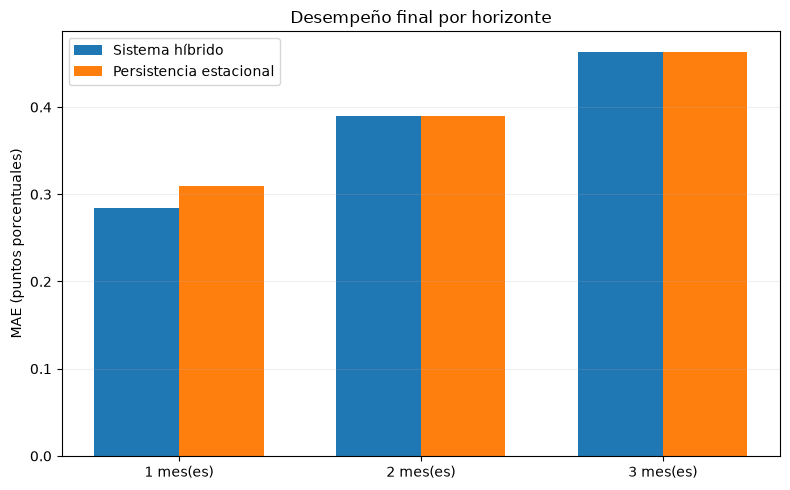

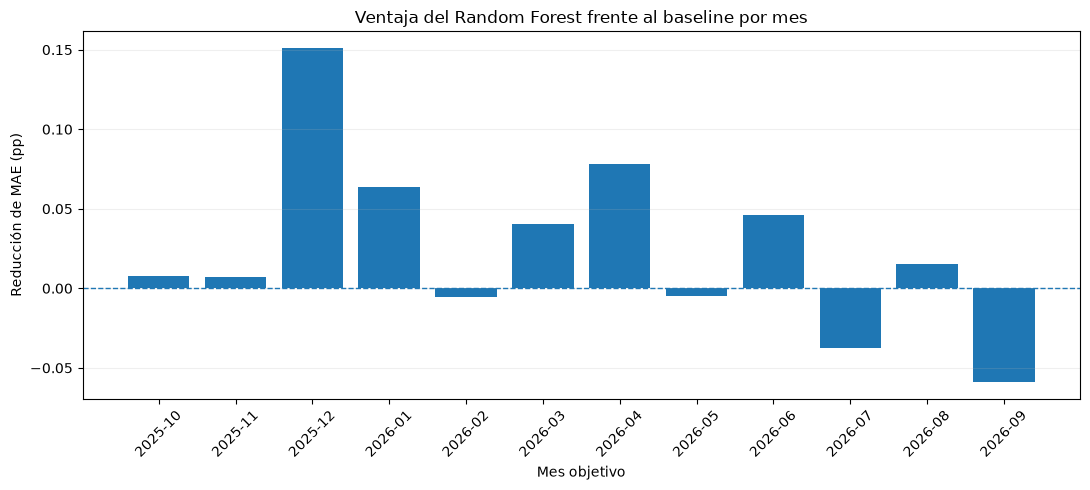

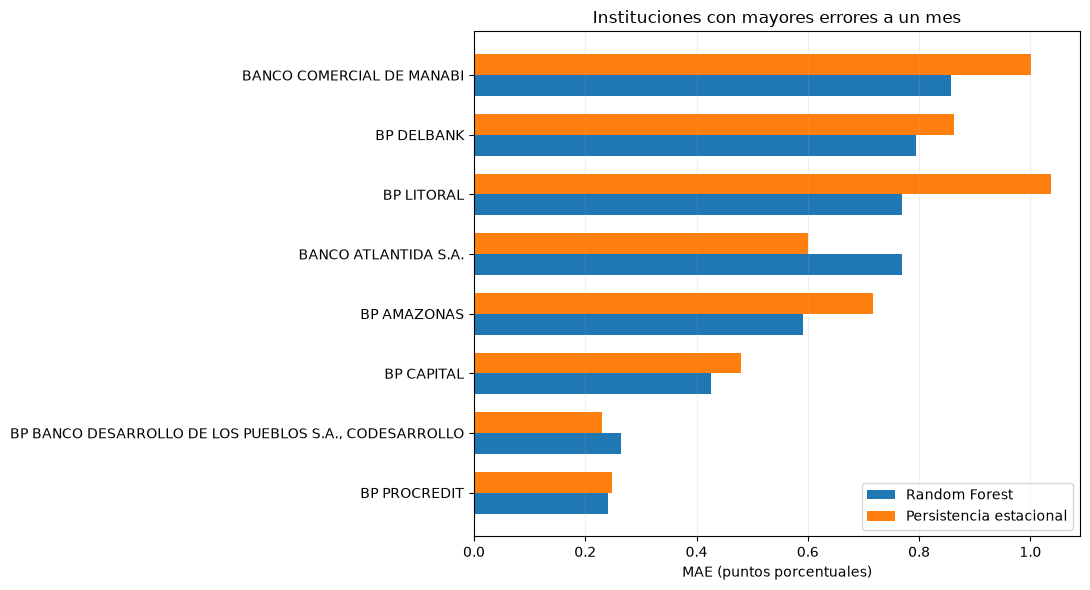

TRES FIGURAS GENERADAS CORRECTAMENTE


In [56]:
import matplotlib.pyplot as plt

# ======================================================
# FIGURA 1. DESEMPEÑO POR HORIZONTE
# ======================================================

datos = resumen_test.sort_values("horizonte")
x = np.arange(len(datos))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - ancho / 2,
    datos["mae_pp"],
    ancho,
    label="Sistema híbrido",
)

ax.bar(
    x + ancho / 2,
    datos["mae_estacional"],
    ancho,
    label="Persistencia estacional",
)

ax.set_xticks(x)
ax.set_xticklabels([
    f"{h} mes(es)" for h in datos["horizonte"]
])
ax.set_ylabel("MAE (puntos porcentuales)")
ax.set_title("Desempeño final por horizonte")
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    CARPETA_FIGURAS / "01_mae_por_horizonte.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ======================================================
# FIGURA 2. VENTAJA MENSUAL A UN MES
# ======================================================

datos = meses_h1.sort_values("mes_objetivo")

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    datos["mes_objetivo"],
    datos["ventaja_pp"],
)

ax.axhline(0, linewidth=1, linestyle="--")

ax.set_title(
    "Ventaja del Random Forest frente al baseline por mes"
)
ax.set_ylabel("Reducción de MAE (pp)")
ax.set_xlabel("Mes objetivo")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    CARPETA_FIGURAS / "02_ventaja_mensual.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ======================================================
# FIGURA 3. BANCOS CON MAYORES ERRORES
# ======================================================

datos = bancos_h1.nlargest(
    8, "mae_modelo"
).sort_values("mae_modelo")

y = np.arange(len(datos))
alto = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    y - alto / 2,
    datos["mae_modelo"],
    alto,
    label="Random Forest",
)

ax.barh(
    y + alto / 2,
    datos["mae_baseline"],
    alto,
    label="Persistencia estacional",
)

ax.set_yticks(y)
ax.set_yticklabels(datos["banco"])
ax.set_xlabel("MAE (puntos porcentuales)")
ax.set_title("Instituciones con mayores errores a un mes")
ax.legend()
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
fig.savefig(
    CARPETA_FIGURAS / "03_errores_por_banco.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("TRES FIGURAS GENERADAS CORRECTAMENTE")

El sistema híbrido desarrollado permite pronosticar la morosidad mensual de instituciones bancarias privadas del Ecuador mediante Random Forest delta para el horizonte de un mes y persistencia estacional para los horizontes de dos y tres meses. En el conjunto de prueba, Random Forest alcanzó un MAE de 0,2839 puntos porcentuales, mejorando un 8,19 % respecto a la persistencia estacional. Sin embargo, su capacidad de detección de incrementos extraordinarios de morosidad fue limitada, por lo que los resultados respaldan su uso como herramienta experimental de pronóstico y no todavía como un mecanismo autónomo de alerta temprana.

## registro experimentos con MLFlow

In [57]:
import mlflow

mlflow.set_tracking_uri("http://127.0.0.1:5000")

mlflow.set_experiment(
    "morosidad-bancos-ecuador"
)

print("MLflow:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

2026/10/27 20:33:47 INFO mlflow.tracking.fluent: Experiment with name 'morosidad-bancos-ecuador' does not exist. Creating a new experiment.


MLflow: 3.17.2
Tracking URI: http://127.0.0.1:5000


In [58]:
with mlflow.start_run(run_name="verificacion_tracking"):
    mlflow.set_tag("etapa", "configuracion")
    mlflow.log_param("horizontes", "1,2,3")
    mlflow.log_metric("tests_aprobados", 36)

print("Registro de prueba completado.")

🏃 View run verificacion_tracking at: http://127.0.0.1:5000/#/experiments/1/runs/46becb134e1c4c3c9424b2b6134c5e0e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Registro de prueba completado.


In [59]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("morosidad-bancos-ecuador")

with mlflow.start_run(run_name="verificacion_tracking") as run:
    mlflow.set_tag("etapa", "configuracion")
    mlflow.log_param("horizontes", "1,2,3")
    mlflow.log_metric("tests_aprobados", 36)

    run_id = run.info.run_id

cliente = MlflowClient()
registro = cliente.get_run(run_id)

print("Run ID:", run_id)
print("Estado:", registro.info.status)
print("Métricas:", registro.data.metrics)
print("REGISTRO DE MLFLOW VALIDADO")

🏃 View run verificacion_tracking at: http://127.0.0.1:5000/#/experiments/1/runs/518e35d1cbeb4b89926e0e5ca52968b7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Run ID: 518e35d1cbeb4b89926e0e5ca52968b7
Estado: FINISHED
Métricas: {'tests_aprobados': 36.0}
REGISTRO DE MLFLOW VALIDADO


In [60]:
import mlflow

mlflow.set_experiment("morosidad-bancos-ecuador")

assert len(resumen_final) == 3
assert len(resumen_test) == 3

for h in (1, 2, 3):

    cv = resumen_final.loc[
        resumen_final["horizonte"] == h
    ].iloc[0]

    test = resumen_test.loc[
        resumen_test["horizonte"] == h
    ].iloc[0]

    estrategia = str(test["estrategia"])

    with mlflow.start_run(
        run_name=f"final_h{h}_{estrategia}"
    ) as run:

        mlflow.set_tags({
            "fase": "evaluacion_final",
            "origen": "registro_retrospectivo",
            "modelo": estrategia,
            "test_usado_para_seleccion": "no",
            "protocolo": "origen_mensual_modelo_congelado",
        })

        mlflow.log_params({
            "horizonte_meses": h,
            "estrategia": estrategia,
            "n_entrenamiento": len(entrenamiento_final[h]),
            "n_test": int(test["observaciones"]),
            "n_folds_cv": int(cv["folds"]),
        })

        if h == 1:
            mlflow.log_params({
                "n_estimators": 150,
                "max_depth": 14,
                "min_samples_leaf": 3,
                "max_features": 0.7,
                "random_state": 42,
                "tipo_objetivo": "delta_morosidad",
            })

        mlflow.log_metrics({
            "cv_mae_pp": float(cv["mae_medio"]),
            "cv_mae_std_pp": float(cv["mae_std"]),
            "test_mae_pp": float(test["mae_pp"]),
            "test_rmse_pp": float(test["rmse_pp"]),
            "test_r2": float(test["r2"]),
            "test_sesgo_pp": float(test["sesgo_pp"]),
            "test_mae_baseline_pp": float(
                test["mae_estacional"]
            ),
            "test_mejora_baseline_pct": float(
                test["mejora_vs_estacional_pct"]
            ),
        })

        print(
            f"Horizonte {h} registrado | "
            f"Run ID: {run.info.run_id}"
        )

print("\nTRES RESULTADOS FINALES REGISTRADOS EN MLFLOW")

Horizonte 1 registrado | Run ID: 463a132af0294e08b0833e3b9268f30d
🏃 View run final_h1_RandomForest_delta_flexible at: http://127.0.0.1:5000/#/experiments/1/runs/463a132af0294e08b0833e3b9268f30d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Horizonte 2 registrado | Run ID: c705f240eddd4a078736f853a23cc852
🏃 View run final_h2_Persistencia_estacional at: http://127.0.0.1:5000/#/experiments/1/runs/c705f240eddd4a078736f853a23cc852
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Horizonte 3 registrado | Run ID: 3e9495d345c34328a02ff2c5c58fbe7c
🏃 View run final_h3_Persistencia_estacional at: http://127.0.0.1:5000/#/experiments/1/runs/3e9495d345c34328a02ff2c5c58fbe7c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1

TRES RESULTADOS FINALES REGISTRADOS EN MLFLOW


In [61]:
import mlflow
import pandas as pd

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("morosidad-bancos-ecuador")

# Configuración original utilizada en los experimentos.
parametros_originales = {
    "n_estimators": 100,
    "max_depth": 10,
    "min_samples_leaf": 5,
    "max_features": 1.0,
}

todas_configuraciones = {
    "Original": parametros_originales,
    **configuraciones_e4,
}

# 5 configuraciones x 3 horizontes x 5 folds.
assert len(detalle_opt_e4) == 75

registros_optimizacion = []

for (h, nombre), grupo in detalle_opt_e4.groupby(
    ["horizonte", "configuracion"],
    sort=True,
):

    parametros = todas_configuraciones[nombre]
    grupo = grupo.sort_values("fold")

    assert len(grupo) == 5

    with mlflow.start_run(
        run_name=f"opt_h{h}_{nombre.lower()}"
    ) as run:

        mlflow.set_tags({
            "fase": "optimizacion",
            "origen": "registro_retrospectivo",
            "algoritmo": "RandomForestRegressor",
            "formulacion": "delta",
            "dataset": "desarrollo",
            "test_utilizado": "no",
            "validacion": "temporal_expanding_window",
        })

        mlflow.log_params({
            "horizonte": int(h),
            "configuracion": nombre,
            "n_folds": 5,
            "random_state": 42,
            **parametros,
        })

        mlflow.log_metrics({
            "cv_mae_medio_pp": float(
                grupo["mae_pp"].mean()
            ),
            "cv_mae_std_pp": float(
                grupo["mae_pp"].std()
            ),
        })

        # Preservar las métricas individuales.
        for fila in grupo.itertuples():
            mlflow.log_metric(
                f"mae_fold_{fila.fold}_pp",
                float(fila.mae_pp),
            )

        registros_optimizacion.append({
            "horizonte": h,
            "configuracion": nombre,
            "run_id": run.info.run_id,
        })

print("CONFIGURACIONES REGISTRADAS:", len(registros_optimizacion))

assert len(registros_optimizacion) == 15

display(pd.DataFrame(registros_optimizacion))

🏃 View run opt_h1_flexible at: http://127.0.0.1:5000/#/experiments/1/runs/6bd8586b89a94a169bbcbf0fa29031ec
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run opt_h1_intermedio at: http://127.0.0.1:5000/#/experiments/1/runs/fef38223f1d747a184faa1bef7f58b50
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run opt_h1_original at: http://127.0.0.1:5000/#/experiments/1/runs/6f8f09c208af4a70b1f53c54fb71a359
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run opt_h1_profundo at: http://127.0.0.1:5000/#/experiments/1/runs/aaeeec719e63481fa417687c95a9e549
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run opt_h1_regularizado at: http://127.0.0.1:5000/#/experiments/1/runs/45b4aa98a8a34ac19f291935c78a0813
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run opt_h2_flexible at: http://127.0.0.1:5000/#/experiments/1/runs/dac5b7bf82e244fabe645837875e9181
🧪 View experiment at: http://127.0.0.1:5000/#/experi

,horizonte,configuracion,run_id
0,1,Flexible,6bd8586b89a94a169bbcbf0fa29031ec
1,1,Intermedio,fef38223f1d747a184faa1bef7f58b50
2,1,Original,6f8f09c208af4a70b1f53c54fb71a359
3,1,Profundo,aaeeec719e63481fa417687c95a9e549
4,1,Regularizado,45b4aa98a8a34ac19f291935c78a0813
5,2,Flexible,dac5b7bf82e244fabe645837875e9181
6,2,Intermedio,c4082c9521d14c578a37b4c919fa1dd1
7,2,Original,8d6a7adb9c5349d7be722dcce66b1856
8,2,Profundo,196f19bd042a49e5ba6770cef6a9a9f1
9,2,Regularizado,855ee261cb304389bcefa189d42e3b2b


In [64]:
import numpy as np
import pandas as pd
import sklearn
import mlflow
import mlflow.sklearn

from mlflow.models import infer_signature
from numpy.testing import assert_allclose

from src.modeling.models import (
    construir_rf_delta_flexible,
    PARAMETROS_RF_FLEXIBLE,
)


# ======================================================
# 1. PREPARAR ENTRENAMIENTO FINAL
# ======================================================

config = datasets[1]

train = entrenamiento_final[1].copy()

predictoras = list(config["predictoras"])
numericas = list(config["numericas"])
target = config["target"]

assert len(train) == 5643
assert len(predictoras) == 22

X_train = train[predictoras].replace(
    [np.inf, -np.inf],
    np.nan,
)

y_train_delta = (
    train[target] - train["morosidad_pp"]
)

assert np.isfinite(
    y_train_delta.to_numpy(dtype=float)
).all()

# ======================================================
# 2. ENTRENAR PIPELINE COMPLETO
# ======================================================

modelo_final = construir_rf_delta_flexible(
    numericas
)

modelo_final.fit(
    X_train,
    y_train_delta,
)

# ======================================================
# 3. PREPARAR FIRMA DEL MODELO
# ======================================================

X_ejemplo = X_train.dropna().head(5).copy()

assert len(X_ejemplo) == 5

delta_ejemplo = modelo_final.predict(X_ejemplo)

firma = infer_signature(
    X_ejemplo,
    delta_ejemplo,
)

# ======================================================
# 4. REGISTRAR EN MLFLOW
# ======================================================

with mlflow.start_run(
    run_name="modelo_final_rf_delta_h1"
) as run:

    mlflow.set_tags({
        "fase": "modelo_final",
        "horizonte": "1",
        "objetivo": "delta_morosidad_pp",
        "entrenamiento": "desarrollo_seguro_pretest",
        "proposito": "reproduccion_del_modelo_evaluado",
        "estado": "candidato_portafolio",
    })

    mlflow.log_params({
        **PARAMETROS_RF_FLEXIBLE,
        "random_state": 42,
        "horizonte_meses": 1,
        "n_entrenamiento": len(train),
        "n_predictores": len(predictoras),
    })

    mlflow.log_dict(
        {
            "predictoras": predictoras,
            "numericas": numericas,
            "objetivo_entrenamiento": (
                "target_morosidad_t1_pp - morosidad_pp"
            ),
            "reconstruccion": (
                "morosidad_futura = morosidad_actual + delta_predicha"
            ),
            "ultima_fecha_objetivo_entrenamiento": "2025-08",
            "version_mlflow": mlflow.__version__,
            "version_sklearn": sklearn.__version__,
        },
        "metadata/configuracion.json",
    )

    info_modelo = mlflow.sklearn.log_model(
        sk_model=modelo_final,
        name="rf_delta_h1",
        signature=firma,
        input_example=X_ejemplo,
        registered_model_name="MorosidadRFDeltaH1",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree",
        ],
    )

    run_id_modelo = run.info.run_id
    uri_modelo = info_modelo.model_uri

# ======================================================
# 5. VERIFICAR CARGA DEL MODELO
# ======================================================

modelo_cargado = mlflow.sklearn.load_model(
    uri_modelo
)

delta_original = modelo_final.predict(X_ejemplo)
delta_recargada = modelo_cargado.predict(X_ejemplo)

assert_allclose(
    delta_original,
    delta_recargada,
    rtol=0,
    atol=1e-10,
)

# Reconstruir niveles futuros.
morosidad_predicha = (
    X_ejemplo["morosidad_pp"].to_numpy(dtype=float)
    + delta_recargada
)

assert np.isfinite(morosidad_predicha).all()

print("MODELO REGISTRADO CORRECTAMENTE")
print("Run ID:", run_id_modelo)
print("Model URI:", uri_modelo)
print("Predicciones originales y recargadas coinciden.")

Registered model 'MorosidadRFDeltaH1' already exists. Creating a new version of this model...
2026/10/27 20:50:14 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: MorosidadRFDeltaH1, version 2
Created version '2' of model 'MorosidadRFDeltaH1'.


🏃 View run modelo_final_rf_delta_h1 at: http://127.0.0.1:5000/#/experiments/1/runs/a705d89bb7194eb383ed7174c596ef4c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
MODELO REGISTRADO CORRECTAMENTE
Run ID: a705d89bb7194eb383ed7174c596ef4c
Model URI: models:/m-2661a87565db474baa29377b2a897662
Predicciones originales y recargadas coinciden.


## Probar la inferencia del modelo

In [65]:
import numpy as np
import pandas as pd

from src.modeling.inference import pronosticar_morosidad


# ======================================================
# 1. UTILIZAR LAS ENTRADAS SIN ETIQUETAS FUTURAS
# ======================================================

entradas = entradas_test[1].copy()

assert not any(
    c.startswith("target_")
    for c in entradas.columns
)

# ======================================================
# 2. CARGAR MODELO Y GENERAR PREDICCIONES
# ======================================================

pronosticos = pronosticar_morosidad(
    datos=entradas,
    horizonte=1,
)

print("=== EJEMPLO DE PRONÓSTICOS ===")

display(pronosticos.head(10))


# ======================================================
# 3. COMPARAR CONTRA LOS RESULTADOS GUARDADOS
# ======================================================

referencia = predicciones_test.loc[
    predicciones_test["horizonte"] == 1,
    ["banco", "fecha", "y_pred"],
].copy()

referencia["fecha"] = pd.to_datetime(
    referencia["fecha"]
)

comparacion = pronosticos.merge(
    referencia,
    left_on=["banco", "fecha_origen"],
    right_on=["banco", "fecha"],
    how="inner",
    validate="one_to_one",
)

assert len(comparacion) == 276

np.testing.assert_allclose(
    comparacion["morosidad_predicha_pp"],
    comparacion["y_pred"],
    rtol=0,
    atol=1e-9,
)

print("\nINFERENCIA REPRODUCIBLE: VALIDADA")
print("Observaciones verificadas:", len(comparacion))
print("Modelo utilizado:", pronosticos["model_uri"].iloc[0])

=== EJEMPLO DE PRONÓSTICOS ===


,banco,fecha_origen,fecha_objetivo,horizonte,morosidad_actual_pp,delta_predicha_pp,morosidad_predicha_pp,modelo,model_uri
0,BANCO ATLANTIDA S.A.,2025-09-01,2025-10-31,1,7.800014e+00,0.321721,8.121736,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
1,BANCO COMERCIAL DE MANABI,2025-09-01,2025-10-31,1,4.889827e+00,0.034325,4.924151,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
2,BP AMAZONAS,2025-09-01,2025-10-31,1,3.336334e+00,0.170707,3.507040,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
3,BP AUSTRO,2025-09-01,2025-10-31,1,3.057892e+00,0.067669,3.125561,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
4,"BP BANCO DESARROLLO DE LOS PUEBLOS S.A., CODES...",2025-09-01,2025-10-31,1,7.993319e+00,0.088425,8.081743,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
5,BP BOLIVARIANO,2025-09-01,2025-10-31,1,1.679144e+00,0.061383,1.740527,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
6,BP CAPITAL,2025-09-01,2025-10-31,1,1.619059e+00,0.041228,1.660286,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
7,BP CITIBANK,2025-09-01,2025-10-31,1,3.000000e-07,0.061337,0.061337,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
8,BP COOPNACIONAL,2025-09-01,2025-10-31,1,3.974503e-02,0.064939,0.104684,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2
9,BP DELBANK,2025-09-01,2025-10-31,1,1.498848e+00,0.153998,1.652846,RandomForest_delta_flexible,models:/MorosidadRFDeltaH1/2



INFERENCIA REPRODUCIBLE: VALIDADA
Observaciones verificadas: 276
Modelo utilizado: models:/MorosidadRFDeltaH1/2


In [70]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

from src.modeling.baselines import aprender_ajustes_estacionales

CARPETA_CONFIG = ROOT / "configs" / "modeling"
CARPETA_CONFIG.mkdir(parents=True, exist_ok=True)

for h in (2, 3):

    config = datasets[h]
    train = entrenamiento_final[h]

    # Aprender utilizando exclusivamente el entrenamiento seguro.
    ajustes = aprender_ajustes_estacionales(
        train,
        config["target"],
        config["fecha_target"],
    )

    # Omitir meses sin ajuste disponible:
    # durante inferencia utilizarán corrección cero.
    ajustes_json = {
        str(int(mes)): float(valor)
        for mes, valor in dict(ajustes).items()
        if pd.notna(valor)
    }

    assert all(
        1 <= int(mes) <= 12
        and np.isfinite(valor)
        for mes, valor in ajustes_json.items()
    )

    ultimo_target = (
        pd.to_datetime(train[config["fecha_target"]])
        .dt.to_period("M")
        .max()
    )

    artefacto = {
        "horizonte": h,
        "estrategia": "Persistencia_estacional",
        "n_entrenamiento": len(train),
        "fecha_objetivo_max_train": str(ultimo_target),
        "ajustes": ajustes_json,
        "recorte_inferior": 0,
        "recorte_superior": 100,
    }

    ruta = CARPETA_CONFIG / f"seasonal_h{h}.json"

    ruta.write_text(
        json.dumps(artefacto, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    print(
        f"Horizonte {h}: {len(ajustes_json)} ajustes, "
        f"guardado en {ruta}"
    )

print("\nAJUSTES ESTACIONALES GUARDADOS")

Horizonte 2: 12 ajustes, guardado en /home/gustavo-paredes/Documents/Developer/Yachay/morosidad-bancos-ecuador/configs/modeling/seasonal_h2.json
Horizonte 3: 12 ajustes, guardado en /home/gustavo-paredes/Documents/Developer/Yachay/morosidad-bancos-ecuador/configs/modeling/seasonal_h3.json

AJUSTES ESTACIONALES GUARDADOS


In [71]:
import importlib
import numpy as np
import pandas as pd

import src.modeling.inference as inference

inference = importlib.reload(inference)
pronosticar_morosidad = inference.pronosticar_morosidad


resultados_verificacion = []

for h in (2, 3):

    entradas = entradas_test[h].copy()

    pronosticos = pronosticar_morosidad(
        datos=entradas,
        horizonte=h,
    )

    referencia = predicciones_test.loc[
        predicciones_test["horizonte"] == h,
        ["banco", "fecha", "fecha_objetivo", "y_pred"],
    ].copy()

    referencia["fecha"] = pd.to_datetime(
        referencia["fecha"]
    )

    comparacion = pronosticos.merge(
        referencia,
        left_on=["banco", "fecha_origen"],
        right_on=["banco", "fecha"],
        validate="one_to_one",
    )

    assert len(comparacion) == len(entradas)

    # Verificar también el mes objetivo.
    meses_generados = pd.to_datetime(
        comparacion["fecha_objetivo_x"]
    ).dt.to_period("M")

    meses_referencia = pd.to_datetime(
        comparacion["fecha_objetivo_y"]
    ).dt.to_period("M")

    assert meses_generados.equals(meses_referencia)

    np.testing.assert_allclose(
        comparacion["morosidad_predicha_pp"],
        comparacion["y_pred"],
        rtol=0,
        atol=1e-9,
    )

    resultados_verificacion.append({
        "horizonte": h,
        "observaciones": len(comparacion),
        "resultado": "VALIDADO",
    })

print("=== VERIFICACIÓN DE INFERENCIA ESTACIONAL ===")
print(pd.DataFrame(resultados_verificacion).to_string(index=False))

assert sum(
    x["observaciones"]
    for x in resultados_verificacion
) == 483

print("\nINFERENCIA MULTIHORIZONTE REPRODUCIBLE")

=== VERIFICACIÓN DE INFERENCIA ESTACIONAL ===
 horizonte  observaciones resultado
         2            253  VALIDADO
         3            230  VALIDADO

INFERENCIA MULTIHORIZONTE REPRODUCIBLE
